In [127]:
library(targets)
library(dplyr)
library(sommer)
library(asreml)
library(AGHmatrix)
library(tidyr)
library(ggplot2)
library(glue)
library(stringr)
library(patchwork)
library(purrr)
library(statgenGxE)
library(factoextra)
library(ggcorrplot)

In [251]:
run_lrt = function(df) {
  df %>%
    mutate(
      LRT_stat = 2 * (LogL - lag(LogL)),
      df_diff = N_params - lag(N_params),
      p_value = pchisq(LRT_stat, df = df_diff, lower.tail = FALSE),
      Signif = case_when(
        p_value < 0.001 ~ '***',
        p_value < 0.01  ~ '**',
        p_value < 0.05  ~ '*',
        TRUE            ~ 'ns'
      )
    )
}

plot_hc = function(corr_mat, specs){
  dist_mat = as.dist(1 - corr_mat)
  hc = hclust(dist_mat, method = 'ward.D2')
  min_y = -0.25 * max(hc$height)
  
  fviz_dend(
    hc, 
    main = glue::glue('Envt clustering ({specs})'),
    ggtheme = theme_minimal()
  ) +
    scale_y_continuous(limits = c(min_y, NA)) +
    coord_cartesian(clip = 'off') +
    theme(plot.margin = margin(t = 10, r = 10, b = 40, l = 10, unit = 'pt'))

}


plot_corr = function(corr_mat, specs){
  ggcorrplot(corr_mat, 
           hc.order = TRUE, 
           type = "lower", 
           lab = TRUE, 
           lab_size = 3, 
           method = 'square', 
           colors = c('#D95F02', 'white', '#2B5C8F'), 
           title = glue('Genetic Correlation Matrix ({specs})'), 
           ggtheme = theme_minimal())
}


prep_and_scale_dta = function(fa_dta){
  fa_dta = fa_dta %>% mutate(Genotype = factor(Genotype), Env = factor(Env), Block = factor(Block), Age = factor(Age))

  env_stats = fa_dta %>% group_by(Env) %>%
    summarize(mean_env = mean(y, na.rm = TRUE), sd_env = sd(y, na.rm = TRUE))

  fa_dta_scaled = fa_dta %>% left_join(env_stats, by = 'Env') %>%
    mutate(y_scaled = (y - mean_env) / sd_env)
}


In [388]:
library(AGHmatrix)


# for later
build_genomic_g_matrix = function(snp_matrix, ploidy = 4, method = 'VanRaden', missing_value = NA, maf = 0.05) {
  Gmatrix(SNPmatrix = snp_matrix, method = method, ploidy = ploidy, missingValue = missing_value, maf = maf)
}

build_genomic_d_matrix = function(snp_matrix, ploidy = 4, method = 'Endelman', missing_value = NA, maf = 0.05) {
  Gmatrix(SNPmatrix = snp_matrix, method = method, ploidy = ploidy, missingValue = missing_value, maf = maf)
}

build_A_inverse = function(mat, keep_genotypes){
  stopifnot(!is.null(rownames(mat)), all(keep_genotypes %in% rownames(mat)))
  keep_mat = mat[keep_genotypes, keep_genotypes]

  solve(keep_mat)
}

In [391]:
library(dplyr)
library(readr)

names_path = 'data/raw/markers/SampleNames.csv'
marker_path = 'data/raw/markers/genomat.csv'


marker_raw <- read_csv(marker_path, show_col_types = FALSE)
code_map   <- read_csv(names_path, show_col_types = FALSE)

marker_id_col <- names(marker_raw)[1]      # adjust if your marker-ID column isn't first
sample_cols   <- names(marker_raw)[-1]

# flag mismatches explicitly rather than silently dropping/NA-ing anything
unmatched_in_marker <- setdiff(sample_cols, code_map$`Sample Code`)
unmatched_in_map    <- setdiff(code_map$`Sample Code`, sample_cols)
if (length(unmatched_in_marker) > 0) {
  message(length(unmatched_in_marker), " marker column(s) have no match in the code map:")
  print(unmatched_in_marker)
}
if (length(unmatched_in_map) > 0) {
  message(length(unmatched_in_map), " sample code(s) in the map have no marker column:")
  print(unmatched_in_map)
}

name_lookup <- setNames(code_map$`Genotype Name`, code_map$`Sample Code`)
new_names <- ifelse(sample_cols %in% names(name_lookup),
                     name_lookup[sample_cols],
                     sample_cols)   # left unmatched as-is -- don't want a silent NA column name

if (anyDuplicated(new_names)) {
  dup <- new_names[duplicated(new_names) | duplicated(new_names, fromLast = TRUE)]
  stop("Duplicate genotype names after renaming -- check the code map: ",
       paste(unique(dup), collapse = ", "))
}

names(marker_raw) <- c(marker_id_col, new_names)


marker_id_col <- names(marker_raw)[1]

marker_mat <- marker_raw %>%
  tibble::column_to_rownames(marker_id_col) %>%
  as.matrix()
geno_mat <- t(marker_mat) 

bend_G <- function(G, w = 1e-3) {
  (1 - w) * G + w * diag(diag(G))
}

New names:
• `` -> `...1`


In [393]:
Dmat <- build_genomic_d_matrix(geno_mat)
kappa(Dmat)


Missing data check: 
	Total SNPs: 51704 
	 0 SNPs dropped due to missing data threshold of 0.5 
	Total of: 51704  SNPs 

MAF check: 
	 30320 SNPs dropped with MAF below 0.05 
	Total: 21384  SNPs 

Heterozigosity data check: 
	No SNPs with heterozygosity, missing threshold of = 0 

Summary check: 
	Initial:  51704 SNPs 
	Final:  21384  SNPs ( 30320  SNPs removed) 

Completed! Time = 0.07  seconds 


[1] 13.1747

In [394]:
Dinv <- solve(Dmat)

In [396]:
saveRDS(Dinv, "data/processed/markers/D_inverse.rds")
saveRDS(Dmat, "data/processed/markers/D_mat.rds")

In [40]:
library(AGHmatrix)

In [42]:
build_A_inverse = function(mat){
  # stopifnot(!is.null(rownames(mat)), all(keep_genotypes %in% rownames(mat)))
  # keep_mat = mat[keep_genotypes, keep_genotypes]
 
  inv_mat = solve(mat)
  attr(inv_mat, "INVERSE") <- TRUE
  inv_mat
}

In [43]:
a_inv = build_A_inverse(g_mat)

In [44]:
a = fit_fa_asreml(prep_yield, a_inv)

ASReml Version 4.2 24/10/2026 16:55:04
Multi-section model using the sigma parameterization.


In [179]:
# 09/25

library(asreml)
library(dplyr)

fit_fa_asreml <- function(fa_dta, Ainv, maxiter = 300) {
  # dta <- fa_dta %>% mutate(Genotype = factor(Genotype), Env = factor(Env), Block = factor(Block))
  dta = prep_and_scale_dta(fa_dta)

  fit <- asreml(
    fixed    = y_scaled ~ Env,
    random   = ~fa(Env, k = 1):vm(Genotype, Ainv) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit  = maxiter,
    ai.loadings = 5,   
    ai.penalty  = 15     
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}



fit_fa2_asreml <- function(fa_dta, Ainv, maxiter = 300) {
  dta = prep_and_scale_dta(fa_dta)

  fit <- asreml(
    fixed    = y_scaled ~ Env + Age,
    random   = ~fa(Env, k = 2):vm(Genotype, Ainv) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit  = maxiter,
    ai.loadings = 5,   
    ai.penalty  = 15     
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
  
}


fit_fa3_asreml <- function(fa_dta, Ainv, maxiter = 300) {
  dta = prep_and_scale_dta(fa_dta)

  fit <- asreml(
    fixed    = y_scaled ~ Env + Age,
    random   = ~fa(Env, k = 3):vm(Genotype, Ainv) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit  = maxiter,
    ai.loadings = 5,   
    ai.penalty  = 15     
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}

fit_cs_asreml = function(cs_dta, Ainv){

  dta = cs_dta %>% mutate(Genotype = factor(Genotype), Env = factor(Env), Block = factor(Block))

  fit = asreml(
    fixed = y ~ Env,
    # random = ~corh(Env):vm(Genotype, Ainv) + Env:Block,
    random = ~ vm(Genotype, Ainv) + idv(Env):vm(Genotype, Ainv) + Env:Block,
    residual = ~idv(units),
    data = dta
  )
}


# NOTES 
# from my scratch notebook, this happens to be a better model than the selected FA3, but when I compared it to the 
# full FA1 for non additive, I did not see any improvement in model. So I'm sticking with this for prod ie same non-additive effects
# across environments
# fit_fa3_min_asreml <- function(fa_dta, Ainv, maxiter = 300) {
#   dta <- prep_and_scale_dta(fa_dta)

#   fit <- asreml(
#     fixed    = y_scaled ~ Env,
#     random   = ~fa(Env, k = 3):vm(Genotype, Ainv) + ide(Genotype) + Env:Block,
#     residual = ~dsum(~units | Env),
#     data     = dta,
#     maxit    = maxiter,
#     ai.loadings = 5,
#     ai.penalty  = 15
#   )
#   fit$call$maxit <- maxiter
#   update.asreml(fit)
# }


fit_fa3_asreml <- function(fa_dta, Ainv, maxiter = 300) {
  dta = prep_and_scale_dta(fa_dta)

  fit <- asreml(
    fixed    = y_scaled ~ Env + Age,
    random   = ~fa(Env, k = 3):vm(Genotype, Ainv) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit  = maxiter,
    ai.loadings = 5,   
    ai.penalty  = 15     
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}


fit_fa3_min_ide_asreml <- function(fa_dta, Ainv, Dinv, maxiter = 300) {
  dta <- prep_and_scale_dta(fa_dta)

  fit <- asreml(
    fixed    = y_scaled ~ Env + Age,
    random   = ~fa(Env, k = 3):vm(Genotype, Ainv) + vm(Genotype, Dinv) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit    = maxiter,
    ai.loadings = 5,
    ai.penalty  = 15
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}

fit_fa2_min_ide_asreml <- function(fa_dta, Ainv, Dinv, maxiter = 300) {
  dta <- prep_and_scale_dta(fa_dta)

  fit <- asreml(
    fixed    = y_scaled ~ Env + Age,
    random   = ~fa(Env, k = 2):vm(Genotype, Ainv) + vm(Genotype, Dinv) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit    = maxiter,
    ai.loadings = 5,
    ai.penalty  = 15
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}



fit_fa3_min_asreml <- function(fa_dta, Ainv, Dinv, maxiter = 300) {
  dta <- prep_and_scale_dta(fa_dta)

  fit <- asreml(
    fixed    = y_scaled ~ Env + Age,
    random   = ~fa(Env, k = 3):vm(Genotype, Ainv) + diag(Env):vm(Genotype, Dinv) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit    = maxiter,
    ai.loadings = 5,
    ai.penalty  = 15
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}

fit_fa2_min_asreml <- function(fa_dta, Ainv, Dinv, maxiter = 300) {
  dta <- prep_and_scale_dta(fa_dta)

  fit <- asreml(
    fixed    = y_scaled ~ Env + Age,
    random   = ~fa(Env, k = 2):vm(Genotype, Ainv) + diag(Env):vm(Genotype, Dinv) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit    = maxiter,
    ai.loadings = 5,
    ai.penalty  = 15
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}


fit_fa3_add_nonadd_asreml <- function(fa_dta, Ainv, Dinv, maxiter = 300) {
  dta <- prep_and_scale_dta(fa_dta)

  fit <- asreml(
    fixed    = y_scaled ~ Env + Age,
    random   = ~fa(Env, k = 3):vm(Genotype, Ainv) + fa(Env, k = 1):vm(Genotype, Dinv) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit    = maxiter,
    ai.loadings = 5,
    ai.penalty  = 15
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}


fit_fa2_ke1_asreml <- function(fa_dta, Ainv, Dinv, maxiter = 300) {
  dta <- prep_and_scale_dta(fa_dta)

  fit <- asreml(
    fixed    = y_scaled ~ Env + Age,
    random   = ~fa(Env, k = 2):vm(Genotype, Ainv) + fa(Env, k = 1):vm(Genotype, Dinv) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit    = maxiter,
    ai.loadings = 5,
    ai.penalty  = 15
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}

fit_fa2_ke2_asreml <- function(fa_dta, Ainv, Dinv, maxiter = 300) {
  dta <- prep_and_scale_dta(fa_dta)

  fit <- asreml(
    fixed    = y_scaled ~ Env + Age,
    random   = ~fa(Env, k = 2):vm(Genotype, Ainv) + fa(Env, k = 2):vm(Genotype, Dinv) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit    = maxiter,
    ai.loadings = 5,
    ai.penalty  = 15
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}


# the non-additive term has no env dimension at all, so no loadings - jjust one scaler

extract_nonadd_scalar_asreml <- function(fit, dta, Ainv) {
  predict(fit, classify = "Env:Genotype", data = dta,
          onlyuse = ~diag(Env):ide(Genotype))$pvals %>%
    mutate(Env = as.character(Env), Genotype = as.character(Genotype)) %>%
    transmute(Genotype, Env, g_e = predicted.value, se_e = std.error)
}


extract_rg_matrix_asreml <- function(varcomp, env_levels, n_factors) {
  var_rows <- varcomp[grep("!var$", rownames(varcomp)), , drop = FALSE]
  if (nrow(var_rows) == 0) {
    stop(
      "extract_rg_matrix_asreml(): no rows matching '!var' "
    )
  }
  R <- var_rows[, 1]

  loadings <- lapply(seq_len(n_factors), function(k) {
    rows <- varcomp[grep(paste0("!fa", k, "$"), rownames(varcomp)), , drop = FALSE]
    if (nrow(rows) == 0) {
      stop(
        "extract_rg_matrix_asreml(): no rows matching '!fa", k, "'",   
      )
    }
    rows[, 1]
  })

  L <- do.call(cbind, loadings)
  # rownames(L) <- env_levels 
  # print('here3')
  cov <- L %*% t(L) + diag(R)
  dimnames(cov) <- list(env_levels, env_levels)

  list(cov = cov, corr = stats::cov2cor(cov), loadings = L)
}

In [483]:
a = summary(fa3_min_ide)$varcomp

In [115]:
tar_load(prep_yield)
tar_load(g_mat)
tar_load(d_mat)
tar_load(env_levels)

In [492]:
Dinv = tmp_dinv

In [489]:
tmp_prep = prep_yield

In [180]:
tar_load(prep_yield)
tar_load(g_mat)
tar_load(d_mat)

In [498]:
attr(a_inv, "INVERSE") <- TRUE
# attr(inv_mat, "INVERSE") <- TRUE

In [ ]:
tar_load(g_mat)

In [181]:
fa3 = fit_fa3_asreml(prep_yield, g_mat)
fa3_min_ide = fit_fa3_min_ide_asreml(prep_yield, g_mat, d_mat)
fa3_min = fit_fa3_min_asreml(prep_yield, g_mat, d_mat)
fa3_ke1 = fit_fa3_add_nonadd_asreml(prep_yield, g_mat, d_mat)
fa2_ke1 = fit_fa2_ke1_asreml(prep_yield, g_mat, d_mat)

fa2 = fit_fa2_asreml(prep_yield, g_mat)
fa2_min_ide = fit_fa2_min_ide_asreml(prep_yield, g_mat, d_mat)
fa2_min = fit_fa2_min_asreml(prep_yield, g_mat, d_mat)
fa2_ke2 = fit_fa2_ke2_asreml(prep_yield, g_mat, d_mat)

ASReml Version 4.2 27/10/2026 12:12:21
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -213.1228           1.0    795   12:12:21  (  2 restrained)
  2     -200.2391           1.0    795   12:12:21  (  2 restrained)
  3     -171.2611           1.0    795   12:12:21  (  2 restrained)
  4     -157.7433           1.0    795   12:12:21  (  4 restrained)
  5     -153.4471           1.0    795   12:12:21  (  3 restrained)
  6     -150.4209           1.0    795   12:12:21  (  4 restrained)
  7     -149.0209           1.0    795   12:12:21  (  1 restrained)
  8     -148.4236           1.0    795   12:12:21  (  2 restrained)
  9     -148.2462           1.0    795   12:12:21  (  1 restrained)
 10     -148.0915           1.0    795   12:12:21  (  1 restrained)
 11     -147.9393           1.0    795   12:12:21  (  1 restrained)
 12     -147.7347           1.0    795   12:12:21  (  1 restrained)
 13     -147.4256           1.0    795   12:

Warning messages:
1: In asreml(fixed = y_scaled ~ Env + Age, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env + Age, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


ASReml Version 4.2 27/10/2026 12:12:21
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -214.0154           1.0    795   12:12:21  (  3 restrained)
  2     -200.0754           1.0    795   12:12:21  (  3 restrained)
  3     -171.1214           1.0    795   12:12:21  (  3 restrained)
  4     -157.6997           1.0    795   12:12:21  (  5 restrained)
  5     -153.4292           1.0    795   12:12:21  (  4 restrained)
  6     -150.3985           1.0    795   12:12:21  (  4 restrained)
  7     -149.0142           1.0    795   12:12:21  (  1 restrained)
  8     -148.4239           1.0    795   12:12:21  (  2 restrained)
  9     -148.2464           1.0    795   12:12:21  (  1 restrained)
 10     -148.0918           1.0    795   12:12:21  (  1 restrained)
 11     -147.9396           1.0    795   12:12:21  (  1 restrained)
 12     -147.7351           1.0    795   12:12:21  (  1 restrained)
 13     -147.4267           1.0    795   12:

Warning messages:
1: In asreml(fixed = y_scaled ~ Env + Age, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env + Age, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


ASReml Version 4.2 27/10/2026 12:12:22
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -217.3262           1.0    795   12:12:22  (  6 restrained)
  2     -194.5770           1.0    795   12:12:22  (  7 restrained)
  3     -167.9171           1.0    795   12:12:22  (  8 restrained)
  4     -156.0521           1.0    795   12:12:22  ( 10 restrained)
  5     -152.5644           1.0    795   12:12:22  (  8 restrained)
  6     -147.5960           1.0    795   12:12:22  ( 10 restrained)
  7     -143.6217           1.0    795   12:12:22  (  7 restrained)
  8     -141.6545           1.0    795   12:12:22  (  8 restrained)
  9     -140.6439           1.0    795   12:12:22  (  4 restrained)
 10     -139.9659           1.0    795   12:12:22  (  4 restrained)
 11     -139.2558           1.0    795   12:12:22  (  3 restrained)
 12     -137.9516           1.0    795   12:12:22  (  3 restrained)
 13     -136.8620           1.0    795   12:

Warning messages:
1: In asreml(fixed = y_scaled ~ Env + Age, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env + Age, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


... (8 outputs left out)

ASReml Version 4.2 27/10/2026 12:12:25
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -211.1378           1.0    795   12:12:25  (  5 restrained)
  2     -193.6264           1.0    795   12:12:25  (  6 restrained)
  3     -167.6470           1.0    795   12:12:25  (  8 restrained)
  4     -157.2171           1.0    795   12:12:25  (  9 restrained)
  5     -156.2248           1.0    795   12:12:25  (  7 restrained)
  6     -154.0605           1.0    795   12:12:25  (  5 restrained)
  7     -153.3797           1.0    795   12:12:25  (  3 restrained)
  8     -152.7165           1.0    795   12:12:25  (  3 restrained)
  9     -152.4319           1.0    795   12:12:25  (  1 restrained)
 10     -152.3543           1.0    795   12:12:25
 11     -152.3322           1.0    795   12:12:25
 12     -152.3150           1.0    795   12:12:25
 13     -152.2872           1.0    795   12:12:25
 14     -152.2313           1.0    795   12:12:2

Warning messages:
1: In asreml(fixed = y_scaled ~ Env + Age, random = ~fa(Env, k = 2):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env + Age, random = ~fa(Env, k = 2):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


ASReml Version 4.2 27/10/2026 12:12:25
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -231.3005           1.0    795   12:12:25  (  7 restrained)
  2     -206.1138           1.0    795   12:12:25  (  7 restrained)
  3     -170.0899           1.0    795   12:12:25  ( 13 restrained)
  4     -158.1429           1.0    795   12:12:25  ( 13 restrained)
  5     -145.7173           1.0    795   12:12:25  ( 11 restrained)
  6     -141.4789           1.0    795   12:12:25  ( 10 restrained)
  7     -138.1852           1.0    795   12:12:26  (  8 restrained)
  8     -136.2194           1.0    795   12:12:26  (  7 restrained)
  9     -134.7230           1.0    795   12:12:26  (  4 restrained)
 10     -133.8571           1.0    795   12:12:26  (  4 restrained)
 11     -132.9126           1.0    795   12:12:26  (  3 restrained)
 12     -132.2806           1.0    795   12:12:26  (  2 restrained)
 13     -131.9904           1.0    795   12:

Warning messages:
1: In asreml(fixed = y_scaled ~ Env + Age, random = ~fa(Env, k = 2):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env + Age, random = ~fa(Env, k = 2):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


In [117]:
summary(fa3)$varcomp

                                                component   std.error     z.ratio bound %ch
Env:Block                                      0.01299713 0.007959648  1.63287732     P 0.0
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2023!var  0.00000000          NA          NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2024!var  0.00000000          NA          NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2025!var  0.08618119 0.070002643  1.23111337     P 0.2
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2026!var  0.00000000          NA          NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!EV 2023!var  0.00000000          NA          NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!EV 2024!var  0.04525746 0.051486401  0.87901767     P 0.8
fa(Env, k = 3):vm(Genotype, Ainv)!EV 2025!var  0.14987015 0.083687309  1.79083489     P 0.4
fa(Env, k = 3):vm(Genotype, Ainv)!EV 2026!var  0.06694009 0.086788942  0.77129747     P 0.8
fa(Env, k = 3):vm(Genotype, Ainv)!NC 2024!var  0.00000000          NA          N

In [118]:
mods = list(FA3 = fa3, FA3_min_ide = fa3_min_ide, FA3_min = fa3_min, FA3_ke1 = fa3_ke1)
mod2a = list(FA2 = fa2, FA2_min_ide = fa2_min_ide, FA2_min = fa2_min,  FA2_ke1 = fa2_ke1, FA2_ke2 = fa2_ke2)
mod2 = list(FA2_min_ide = fa2_min_ide, FA3_min_ide = fa3_min_ide)

In [119]:
mods_2a = data.frame(
    Model    = names(mod2a),
    LogL     = sapply(mod2a, function(m) m$loglik),
    N_params = sapply(mod2a, function(m) (m$nwv)),
    AIC      = sapply(mod2a, function(m) summary(m)$aic),
    BIC      = sapply(mod2a, function(m) summary(m)$bic)
  )

In [120]:
mods_2 = data.frame(
    Model    = names(mod2),
    LogL     = sapply(mod2, function(m) m$loglik),
    N_params = sapply(mod2, function(m) (m$nwv)),
    AIC      = sapply(mod2, function(m) summary(m)$aic),
    BIC      = sapply(mod2, function(m) summary(m)$bic)
  )

In [121]:
mods_all = data.frame(
    Model    = names(mods),
    LogL     = sapply(mods, function(m) m$loglik),
    N_params = sapply(mods, function(m) (m$nwv)),
    AIC      = sapply(mods, function(m) summary(m)$aic),
    BIC      = sapply(mods, function(m) summary(m)$bic)
  )

In [122]:
run_lrt(mods_all)

                  Model      LogL N_params      AIC      BIC     LRT_stat df_diff   p_value Signif
FA3                 FA3 -145.0510       51 374.1020 570.8032           NA      NA        NA     ns
FA3_min_ide FA3_min_ide -145.0498       52 376.0996 577.4842  0.002390404       1 0.9610056     ns
FA3_min         FA3_min -143.2392       61 386.4784 620.6465  3.621203673       9 0.9345317     ns
FA3_ke1         FA3_ke1 -137.8994       71 377.7989 616.6503 10.679569290      10 0.3830212     ns

In [123]:
run_lrt(mods_2a)

                  Model      LogL N_params      AIC      BIC     LRT_stat df_diff     p_value Signif
FA2                 FA2 -155.6156       41 383.2312 551.8321           NA      NA          NA     ns
FA2_min_ide FA2_min_ide -155.6153       42 385.2306 558.5149 5.597605e-04       1 0.981124404     ns
FA2_min         FA2_min -154.1997       51 394.3995 595.7840 2.831109e+00       9 0.970615997     ns
FA2_ke1         FA2_ke1 -141.8500       61 373.7000 584.4512 2.469950e+01      10 0.005945147     **
FA2_ke2         FA2_ke2 -137.1542       71 382.3084 635.2099 9.391533e+00      10 0.495391958     ns

In [124]:
run_lrt(mods_2)

                  Model      LogL N_params      AIC      BIC LRT_stat df_diff    p_value Signif
FA2_min_ide FA2_min_ide -155.6153       42 385.2306 558.5149       NA      NA         NA     ns
FA3_min_ide FA3_min_ide -145.0498       52 376.0996 577.4842 21.13095      10 0.02019875      *

In [485]:
rownames(summary(fa3_min_ide)$varcomp)

 [1] "vm(Genotype, Dinv)"                            "Env:Block"                                     "fa(Env, k = 3):vm(Genotype, Ainv)!BW 2023!var"
 [4] "fa(Env, k = 3):vm(Genotype, Ainv)!BW 2024!var" "fa(Env, k = 3):vm(Genotype, Ainv)!BW 2025!var" "fa(Env, k = 3):vm(Genotype, Ainv)!BW 2026!var"
 [7] "fa(Env, k = 3):vm(Genotype, Ainv)!EV 2023!var" "fa(Env, k = 3):vm(Genotype, Ainv)!EV 2024!var" "fa(Env, k = 3):vm(Genotype, Ainv)!EV 2025!var"
[10] "fa(Env, k = 3):vm(Genotype, Ainv)!EV 2026!var" "fa(Env, k = 3):vm(Genotype, Ainv)!NC 2024!var" "fa(Env, k = 3):vm(Genotype, Ainv)!NC 2025!var"
[13] "fa(Env, k = 3):vm(Genotype, Ainv)!BW 2023!fa1" "fa(Env, k = 3):vm(Genotype, Ainv)!BW 2024!fa1" "fa(Env, k = 3):vm(Genotype, Ainv)!BW 2025!fa1"
[16] "fa(Env, k = 3):vm(Genotype, Ainv)!BW 2026!fa1" "fa(Env, k = 3):vm(Genotype, Ainv)!EV 2023!fa1" "fa(Env, k = 3):vm(Genotype, Ainv)!EV 2024!fa1"
[19] "fa(Env, k = 3):vm(Genotype, Ainv)!EV 2025!fa1" "fa(Env, k = 3):vm(Genotype, Ainv)!EV 2026!fa1" "fa(E

In [486]:
tar_load(fit_fa3_min_ide_asr)

In [18]:
env_levels = levels(factor(prep_yield$Env))

In [37]:
a = extract_rg_matrix_asreml(summary(fa3_min_ide)$varcomp, env_levels, 3)
b = extract_rg_matrix_asreml(summary(fa3)$varcomp, env_levels, 3)

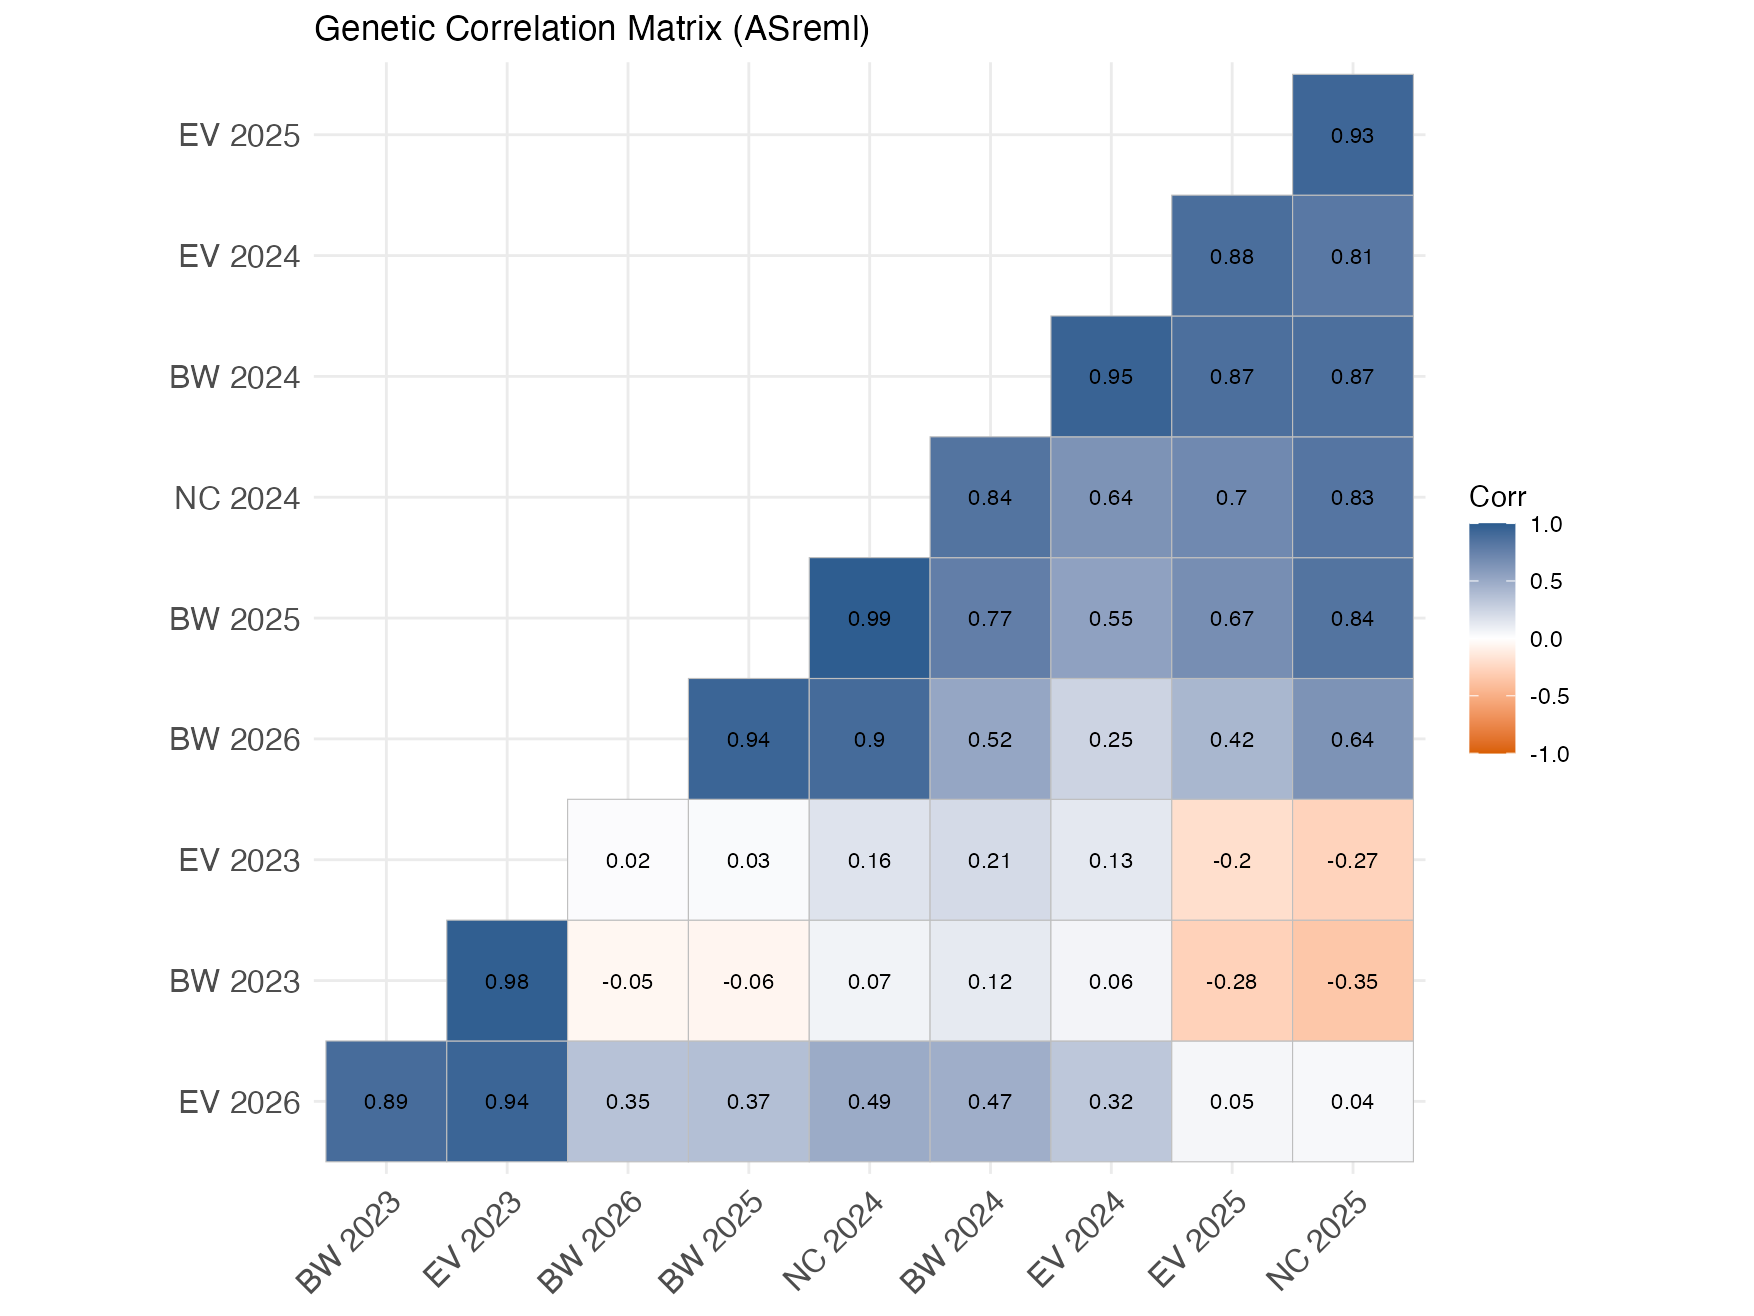

In [252]:
cor = extract_rg_matrix_asreml(summary(fa3_min_ide)$varcomp, env_levels, 3)$corr
plot_corr(cor, 'ASreml')

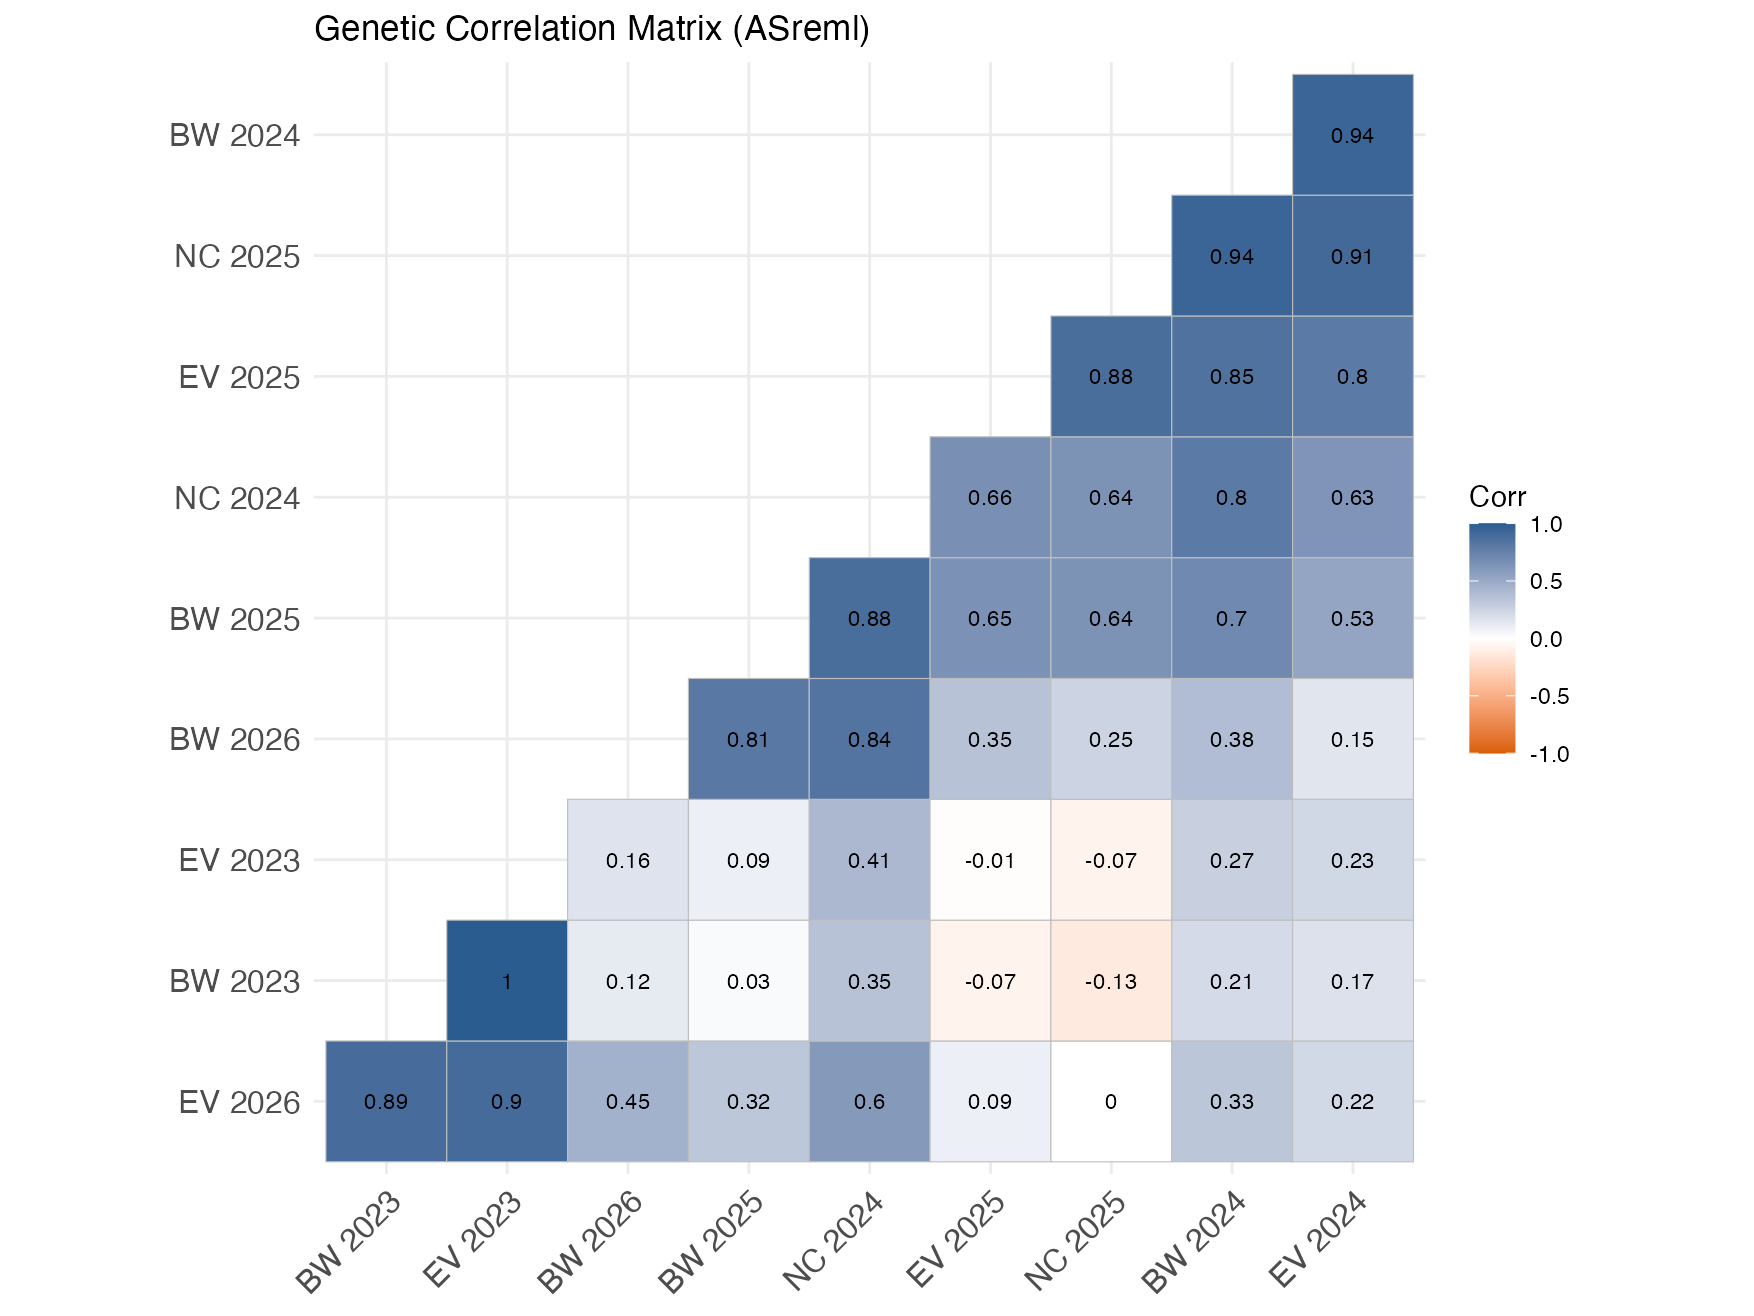

In [129]:
cor = extract_rg_matrix_asreml(summary(fa3_min_ide)$varcomp, env_levels, 3)$corr
plot_corr(cor, 'ASreml')

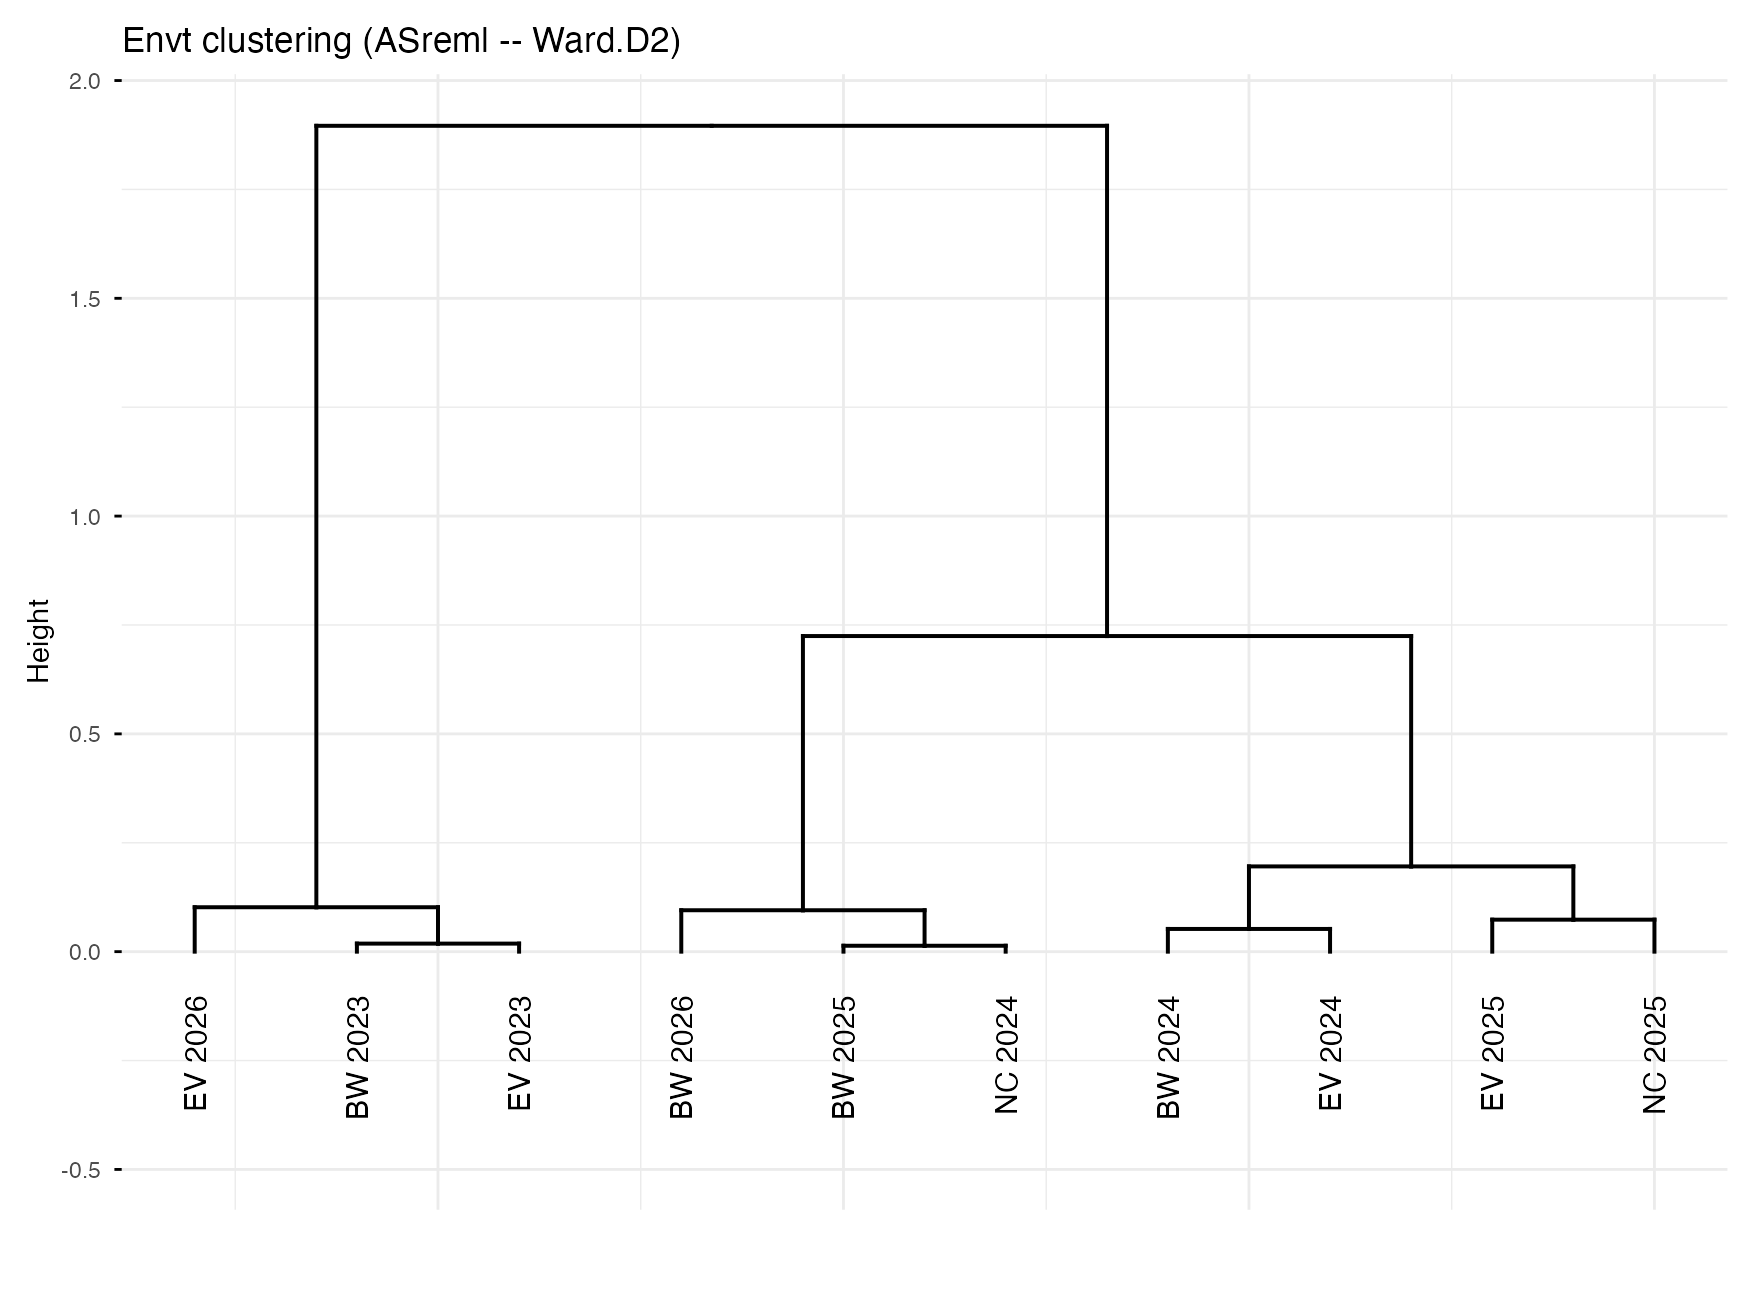

In [254]:
plot_hc(cor, 'ASreml -- Ward.D2')

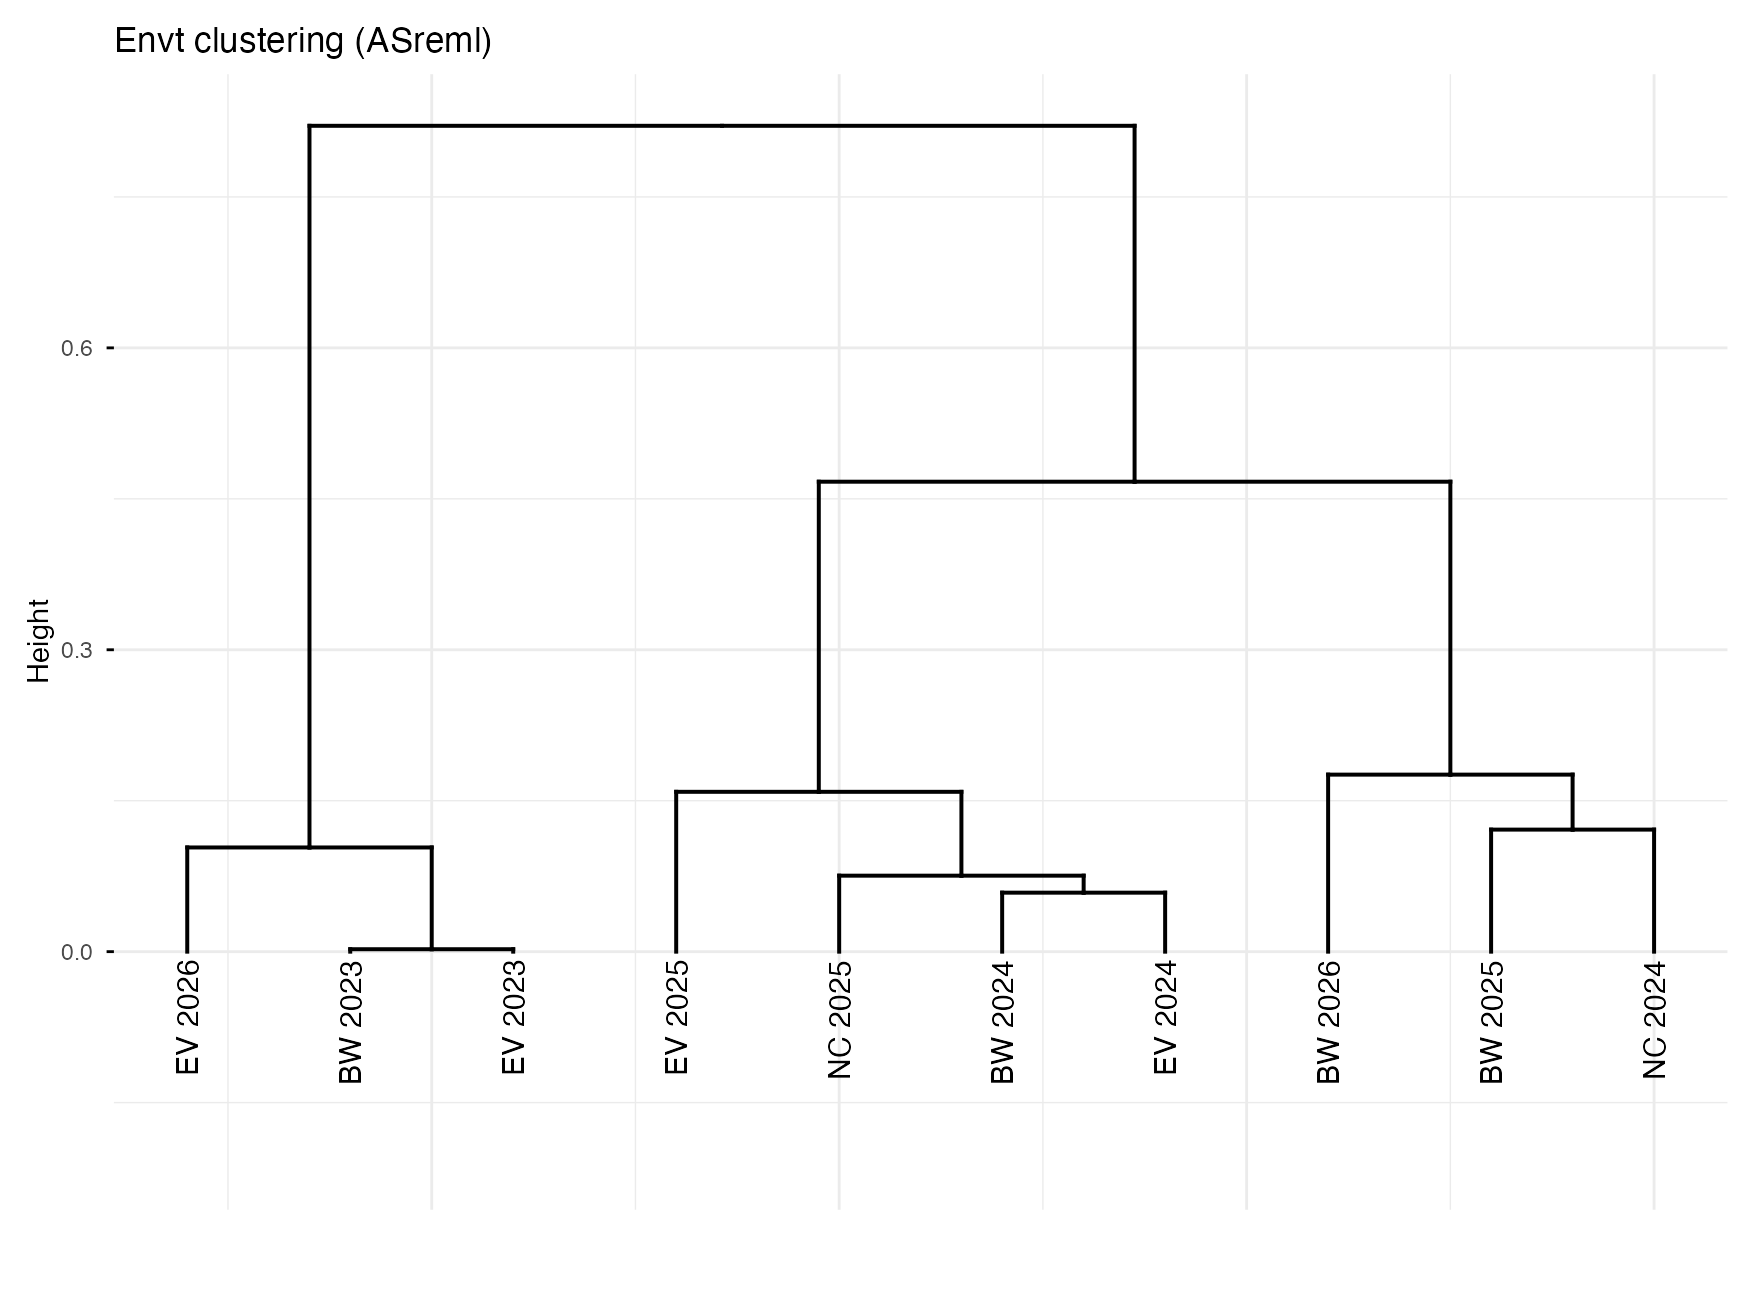

In [130]:
plot_hc(cor, 'ASreml')

In [131]:
round(cor, 2)

        BW 2023 BW 2024 BW 2025 BW 2026 EV 2023 EV 2024 EV 2025 EV 2026 NC 2024 NC 2025
BW 2023    1.00    0.21    0.03    0.12    1.00    0.17   -0.07    0.89    0.35   -0.13
BW 2024    0.21    1.00    0.70    0.38    0.27    0.94    0.85    0.33    0.80    0.94
BW 2025    0.03    0.70    1.00    0.81    0.09    0.53    0.65    0.32    0.88    0.64
BW 2026    0.12    0.38    0.81    1.00    0.16    0.15    0.35    0.45    0.84    0.25
EV 2023    1.00    0.27    0.09    0.16    1.00    0.23   -0.01    0.90    0.41   -0.07
EV 2024    0.17    0.94    0.53    0.15    0.23    1.00    0.80    0.22    0.63    0.91
EV 2025   -0.07    0.85    0.65    0.35   -0.01    0.80    1.00    0.09    0.66    0.88
EV 2026    0.89    0.33    0.32    0.45    0.90    0.22    0.09    1.00    0.60    0.00
NC 2024    0.35    0.80    0.88    0.84    0.41    0.63    0.66    0.60    1.00    0.64
NC 2025   -0.13    0.94    0.64    0.25   -0.07    0.91    0.88    0.00    0.64    1.00

In [132]:
summary(fa2_ke1)$varcomp

                                                  component   std.error    z.ratio bound %ch
Env:Block                                      1.260229e-02 0.007831879  1.6091015     P 0.0
fa(Env, k = 1):vm(Genotype, Dinv)!BW 2023!var  0.000000e+00          NA         NA     F  NA
fa(Env, k = 1):vm(Genotype, Dinv)!BW 2024!var  0.000000e+00          NA         NA     F  NA
fa(Env, k = 1):vm(Genotype, Dinv)!BW 2025!var  3.730437e-02 0.028801089  1.2952416     P 0.0
fa(Env, k = 1):vm(Genotype, Dinv)!BW 2026!var  0.000000e+00          NA         NA     F  NA
fa(Env, k = 1):vm(Genotype, Dinv)!EV 2023!var  5.131987e-07          NA         NA     B  NA
fa(Env, k = 1):vm(Genotype, Dinv)!EV 2024!var  0.000000e+00          NA         NA     F  NA
fa(Env, k = 1):vm(Genotype, Dinv)!EV 2025!var  0.000000e+00          NA         NA     F  NA
fa(Env, k = 1):vm(Genotype, Dinv)!EV 2026!var  0.000000e+00          NA         NA     F  NA
fa(Env, k = 1):vm(Genotype, Dinv)!NC 2024!var  0.000000e+00          N

In [111]:
prep_yield %>% count(Env, Block) %>% rename(n_genotype_per_block = n)

# A tibble: 36 × 3
   Env     Block n_genotype_per_block
   <chr>   <chr>                <int>
 1 BW 2023 1                       11
 2 BW 2023 2                       13
 3 BW 2023 3                       12
 4 BW 2024 1                       37
 5 BW 2024 2                       38
 6 BW 2024 3                       37
 7 BW 2025 1                       37
 8 BW 2025 2                       35
 9 BW 2025 3                       37
10 BW 2026 1                       30
# ℹ 26 more rows
# ℹ Use `print(n = ...)` to see more rows

In [38]:
tmp = readxl::read_excel('data/raw/nc/2024 NCSU Data.xlsx', sheet = '24 Harvest Data ')

New names:
• `` -> `...18`


In [42]:
tmp2 = tmp %>% dplyr::select(Orderid, Name, Bush)

In [46]:
tmp2 %>% count(Bush, Orderid)

# A tibble: 102 × 3
   Bush  Orderid     n
   <chr> <chr>   <int>
 1 A     0102        4
 2 A     0203        4
 3 A     0305        4
 4 A     0404        3
 5 A     0605        3
 6 A     0606        3
 7 A     0702        3
 8 A     0705        4
 9 A     0804        4
10 A     0901        3
# ℹ 92 more rows
# ℹ Use `print(n = ...)` to see more rows

In [133]:
split_varcomp_asreml <- function(varcomp,
                                  add_pattern = "Ainv",
                                  nonadd_pattern = "ide\\(Genotype|Dinv") {
  rn <- rownames(varcomp)
  is_add    <- grepl(add_pattern, rn)
  is_nonadd <- grepl(nonadd_pattern, rn) & !is_add
  stopifnot(any(is_add), any(is_nonadd))
  list(additive = varcomp[is_add, , drop = FALSE],
       nonadditive = varcomp[is_nonadd, , drop = FALSE])
}

extract_rg_matrix_asreml_split <- function(varcomp, env_levels, ka, ke) {
  parts <- split_varcomp_asreml(varcomp)
  list(
    additive    = extract_rg_matrix_asreml(parts$additive, env_levels, ka),
    nonadditive = extract_rg_matrix_asreml(parts$nonadditive, env_levels, ke)
  )
}

In [152]:
Ainv = g_mat

In [182]:
pv <- predict(fa3, classify = "Env:Genotype", data = prep_and_scale_dta(prep_yield), average = 'Age')$pvals

ASReml Version 4.2 27/10/2026 12:12:49
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -141.9823           1.0    795   12:12:49
  2     -141.9821           1.0    795   12:12:49
 3     -141.9819           1.0    795   12:12:49


Warning message:
In asreml(fixed = y_scaled ~ Env + Age, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


In [168]:
dta = prep_and_scale_dta(prep_yield)

In [190]:
dta$Age = factor(dta$Age)

In [192]:
str(dta)

tibble [810 × 8] (S3: tbl_df/tbl/data.frame)
 $ Genotype: Factor w/ 41 levels "Arcadia","Colossus",..: 40 22 29 25 23 20 31 26 28 39 ...
 $ Env     : Factor w/ 10 levels "BW 2023","BW 2024",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ Block   : Factor w/ 6 levels "1","2","3","A",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ y       : num [1:810] 2.59 2.63 8.87 19.81 3.23 ...
 $ Age     : Factor w/ 6 levels "1","2","3","4",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ mean_env: num [1:810] 6.06 6.06 6.06 6.06 6.06 ...
 $ sd_env  : num [1:810] 5.4 5.4 5.4 5.4 5.4 ...
 $ y_scaled: num [1:810] -0.643 -0.636 0.521 2.548 -0.525 ...


In [175]:
Dinv = d_mat

In [191]:
   wald.asreml(fa3, ssType = "conditional", denDF = "numeric")

ASReml Version 4.2 27/10/2026 12:21:49
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -141.9823           1.0    795   12:21:49
  2     -141.9821           1.0    795   12:21:49


Warning message:
In asreml(fixed = y_scaled ~ Env + Age, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


$Wald

Wald tests for fixed effects.
Response: y_scaled

            Df denDF  F.inc  F.con Margin      Pr
(Intercept)  1  20.6  3.226  3.226        0.08717
Env          9    NA  4.140  5.832      A      NA
Age          5    NA 12.380 12.380      A      NA

$stratumVariances
NULL


In [201]:
summary(fa3, coef = TRUE)$coef.fixed

               solution std error    z.ratio
(Intercept) -0.25261207 0.1831335 -1.3793873
Env_BW 2023  0.00000000        NA         NA
Env_BW 2024 -0.12866166 0.2166704 -0.5938129
Env_BW 2025 -0.96661981 0.2785570 -3.4700975
Env_BW 2026 -1.30763189 0.3497434 -3.7388320
Env_EV 2023  0.10400628 0.2108650  0.4932364
Env_EV 2024 -0.07147698 0.2141064 -0.3338386
Env_EV 2025 -0.90439485 0.2801448 -3.2283119
Env_EV 2026 -1.49084036 0.3387305 -4.4012587
Env_NC 2024 -1.63176730 0.3420716 -4.7702512
Env_NC 2025 -1.23976238 0.4164619 -2.9768927
Age_1        0.00000000        NA         NA
Age_2        1.03040119 0.1317036  7.8236378
Age_3        1.51436519 0.2286508  6.6230488
Age_4        1.61638740 0.3000727  5.3866518
Age_5        1.57636136 0.3402864  4.6324552
Age_6        1.25831828 0.3735310  3.3687117

In [198]:
fit_fa3_asreml3 <- function(fa_dta, Ainv, maxiter = 300, extra_fixed = NULL) {
  dta = prep_and_scale_dta(fa_dta)

  fixed_ef = 'Env'
  if(!is.null(extra_fixed)) fixed_ef = paste(fixed_ef, extra_fixed, sep = '+')
  fixed_formula = as.formula(paste0('y_scaled ~ ', fixed_ef ))

  fit <- asreml(
    fixed    = fixed_formula,
    random   = ~fa(Env, k = 3):vm(Genotype, Ainv) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit  = maxiter,
    ai.loadings = 5,   
    ai.penalty  = 15     
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}

In [199]:
fa3 = fit_fa3_asreml3(prep_yield, g_mat, extra_fixed = 'Age')

ASReml Version 4.2 27/10/2026 12:36:51
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -213.1228           1.0    795   12:36:51  (  2 restrained)
  2     -200.2391           1.0    795   12:36:51  (  2 restrained)
  3     -171.2611           1.0    795   12:36:51  (  2 restrained)
  4     -157.7433           1.0    795   12:36:51  (  4 restrained)
  5     -153.4471           1.0    795   12:36:51  (  3 restrained)
  6     -150.4209           1.0    795   12:36:51  (  4 restrained)
  7     -149.0209           1.0    795   12:36:51  (  1 restrained)
  8     -148.4236           1.0    795   12:36:51  (  2 restrained)
  9     -148.2462           1.0    795   12:36:51  (  1 restrained)
 10     -148.0915           1.0    795   12:36:51  (  1 restrained)
 11     -147.9393           1.0    795   12:36:51  (  1 restrained)
 12     -147.7347           1.0    795   12:36:51  (  1 restrained)
 13     -147.4256           1.0    795   12:

Warning messages:
1: In asreml(fixed = fixed_formula, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env + Age, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


In [207]:


library(dplyr)
library(readxl)
library(chillR)

# ---- 1. Read BW/EV (NASA POWER, already clean) --------------------------

read_nasa_power = function(path, location) {
  read.csv(path) %>%
    mutate(Location = location) %>%
    rename(Year = YEAR, Month = MO, Day = DY, Hour = HR, Temp = T2M) %>%
    dplyr::select(Year, Month, Day, Hour, Temp, Location)
}

BW_Data = read_nasa_power("data/raw/weather/NASA_BW_POWER_Point_Hourly_20220101_20260628_UTC.csv", "BW")
EV_Data = read_nasa_power("data/raw/weather/NASA_EV_POWER_Point_Hourly_20220101_20260628_UTC.csv", "EV")

# ---- 2. Read NC (ECONET/HCRS workbook, 3 sheets, messy headers) ---------

read_nc_sheet = function(path, sheet_name) {
  raw = read_excel(path, sheet = sheet_name, col_names = FALSE, n_max = 20)
  header_row = which(apply(raw, 1, function(r) any(grepl("Date/Time", r, fixed = TRUE))))
  stopifnot(length(header_row) == 1)

  dta = read_excel(path, sheet = sheet_name, skip = header_row, col_names = FALSE)
  names(dta)[1:3] = c("datetime", "Temp", "Precip_cm")

  dta %>%
    mutate(
      datetime = as.POSIXct(datetime, tz = "America/New_York"),
      Year  = as.integer(format(datetime, "%Y")),
      Month = as.integer(format(datetime, "%m")),
      Day   = as.integer(format(datetime, "%d")),
      Hour  = as.integer(format(datetime, "%H")),
      Temp  = as.numeric(Temp),
      Location = "NC"
    ) %>%
    arrange(datetime) %>%
    dplyr::select(Year, Month, Day, Hour, Temp, Location)
}

nc_path = "data/raw/weather/NCHCRS temp precip hourly 23-25.xlsx"
NC_Data = bind_rows(
  read_nc_sheet(nc_path, "2023"),
  read_nc_sheet(nc_path, "2024"),
  read_nc_sheet(nc_path, "2025")
)

CombinedData = bind_rows(BW_Data, EV_Data, NC_Data)

# ---- 3. Season-window extraction (generalized, replaces per-year blocks) --

get_chill_season = function(data, loc, season_year) {
  data %>%
    filter(
      Location == loc,
      (Year == season_year - 1 & Month >= 10) | (Year == season_year & Month <= 2)
    ) %>%
    arrange(Year, Month, Day, Hour)
}

get_heat_season = function(data, loc, season_year) {
  data %>%
    filter(Location == loc, Year == season_year, Month <= 2) %>%
    arrange(Year, Month, Day, Hour)
}

# ---- 4. Which Location x season combos actually have data ---------------

seasons = bind_rows(
  tibble(Location = "BW", season = 2023:2026),
  tibble(Location = "EV", season = 2023:2026),
  tibble(Location = "NC", season = 2024:2025)   # only 2 seasons available
)

# ---- 5. Compute chill models + GDH for each Location x season -----------

compute_units = function(loc, season_year) {
  chill_dta = get_chill_season(CombinedData, loc, season_year)
  heat_dta  = get_heat_season(CombinedData, loc, season_year)

  tibble(
    Location = loc,
    season = season_year,
    n_chill_hours_available = nrow(chill_dta),
    n_heat_hours_available  = nrow(heat_dta),
    Basic_Chilling_hrs   = Chilling_Hours(chill_dta$Temp, summ = TRUE),
    Utah_Chillinghrs     = Utah_Model(chill_dta$Temp, summ = TRUE),
    Dynamic_Chillinghrs  = Dynamic_Model(chill_dta$Temp, summ = TRUE),
    GDH                  = GDH_model(heat_dta$Temp, sum = TRUE)  # see note at top re: function name
  )
}

ChillHeatUnits = purrr::pmap_dfr(seasons, function(Location, season) compute_units(Location, season))

# 
ChillHeatUnits %>%
  mutate(
    chill_hours_flag = n_chill_hours_available < 3500,
    heat_hours_flag  = n_heat_hours_available < 1350
  ) %>%
  filter(chill_hours_flag | heat_hours_flag) %>%
  print()

ChillHeatUnits

New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`


Warning messages:
1: Expecting numeric in C2136 / R2136C3: got 'MV' 
2: Expecting numeric in C2137 / R2137C3: got 'QCF' 
3: Expecting numeric in C4657 / R4657C3: got 'QCF' 
4: Expecting numeric in C6649 / R6649C3: got 'MV' 
5: Expecting numeric in C6793 / R6793C3: got 'QCF' 


: [1m[33mError[39m in `pmap()`:[22m
[1m[22m[36mℹ[39m In index: 1.
[1mCaused by error in `tibble()` at ]8;line = 83:col = 3;file://file:///var/folders/_v/qzwwcnmn743btzqw76jjq7j80000gn/T/ark-debug-67778/480659021.rT/ark-debug-67778/480659021.r:83:3]8;;:[22m
[1m[22m[33m![39m Tibble columns must have compatible sizes.
[36m•[39m Size 3624: Existing data.
[36m•[39m Size 1416: Column `GDH`.
[36mℹ[39m Only values of size one are recycled.

In [208]:


library(dplyr)
library(readxl)
library(chillR)

# ---- 1. Read BW/EV (NASA POWER, already clean) --------------------------

read_nasa_power = function(path, location) {
  read.csv(path) %>%
    mutate(Location = location) %>%
    rename(Year = YEAR, Month = MO, Day = DY, Hour = HR, Temp = T2M) %>%
    dplyr::select(Year, Month, Day, Hour, Temp, Location)
}

BW_Data = read_nasa_power("data/raw/weather/NASA_BW_POWER_Point_Hourly_20220101_20260628_UTC.csv", "BW")
EV_Data = read_nasa_power("data/raw/weather/NASA_EV_POWER_Point_Hourly_20220101_20260628_UTC.csv", "EV")

# ---- 2. Read NC (ECONET/HCRS workbook, 3 sheets, messy headers) ---------

read_nc_sheet = function(path, sheet_name) {
  # sheets "2023"/"2024" have 13 metadata rows before the header row;
  # sheet "2025" has none. Detect by looking for the header row itself
  # rather than hardcoding a row count per sheet, so this doesn't silently
  # break if a future export adds/removes a metadata line.
  raw = read_excel(path, sheet = sheet_name, col_names = FALSE, n_max = 20)
  header_row = which(apply(raw, 1, function(r) any(grepl("Date/Time", r, fixed = TRUE))))
  stopifnot(length(header_row) == 1)

  dta = read_excel(path, sheet = sheet_name, skip = header_row, col_names = FALSE)
  names(dta)[1:3] = c("datetime", "Temp", "Precip_cm")

  dta %>%
    mutate(
      datetime = as.POSIXct(datetime, tz = "America/New_York"),
      Year  = as.integer(format(datetime, "%Y")),
      Month = as.integer(format(datetime, "%m")),
      Day   = as.integer(format(datetime, "%d")),
      Hour  = as.integer(format(datetime, "%H")),
      Temp  = as.numeric(Temp),
      Location = "NC"
    ) %>%
    arrange(datetime) %>%
    dplyr::select(Year, Month, Day, Hour, Temp, Location)
}

nc_path = "data/raw/weather/NCHCRS temp precip hourly 23-25.xlsx"
NC_Data = bind_rows(
  read_nc_sheet(nc_path, "2023"),
  read_nc_sheet(nc_path, "2024"),
  read_nc_sheet(nc_path, "2025")
)

CombinedData = bind_rows(BW_Data, EV_Data, NC_Data)

# ---- 3. Season-window extraction (generalized, replaces per-year blocks) --

get_chill_season = function(data, loc, season_year) {
  data %>%
    filter(
      Location == loc,
      (Year == season_year - 1 & Month >= 10) | (Year == season_year & Month <= 2)
    ) %>%
    arrange(Year, Month, Day, Hour)
}

get_heat_season = function(data, loc, season_year) {
  data %>%
    filter(Location == loc, Year == season_year, Month <= 2) %>%
    arrange(Year, Month, Day, Hour)
}

# ---- 4. Which Location x season combos actually have data ---------------

seasons = bind_rows(
  tibble(Location = "BW", season = 2023:2026),
  tibble(Location = "EV", season = 2023:2026),
  tibble(Location = "NC", season = 2024:2025)   # only 2 seasons available
)

# ---- 5. Compute chill models + GDH for each Location x season -----------

compute_units = function(loc, season_year) {
  chill_dta = get_chill_season(CombinedData, loc, season_year)
  heat_dta  = get_heat_season(CombinedData, loc, season_year)

  last_val = function(x) tail(x, 1)

  tibble(
    Location = loc,
    season = season_year,
    n_chill_hours_available = nrow(chill_dta),
    n_heat_hours_available  = nrow(heat_dta),
    Basic_Chilling_hrs   = last_val(Chilling_Hours(chill_dta$Temp, summ = TRUE)),
    Utah_Chillinghrs     = last_val(Utah_Model(chill_dta$Temp, summ = TRUE)),
    Dynamic_Chillinghrs  = last_val(Dynamic_Model(chill_dta$Temp, summ = TRUE)),
    GDH                  = last_val(GDH_model(heat_dta$Temp, sum = TRUE))  # see note at top re: function name
  )
}

ChillHeatUnits = purrr::pmap_dfr(seasons, function(Location, season) compute_units(Location, season))

# Quick sanity check: flag any season with suspiciously few hours
# (a full Oct-Feb chill window should be ~3600-3650 hours; a full Jan-Feb
# heat window should be ~1400-1416 hours). A low count usually means a gap
# in the source data, not a real missing season.
ChillHeatUnits %>%
  mutate(
    chill_hours_flag = n_chill_hours_available < 3500,
    heat_hours_flag  = n_heat_hours_available < 1350
  ) %>%
  filter(chill_hours_flag | heat_hours_flag) %>%
  print()

ChillHeatUnits

New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`


Warning messages:
1: Expecting numeric in C2136 / R2136C3: got 'MV' 
2: Expecting numeric in C2137 / R2137C3: got 'QCF' 
3: Expecting numeric in C4657 / R4657C3: got 'QCF' 
4: Expecting numeric in C6649 / R6649C3: got 'MV' 
5: Expecting numeric in C6793 / R6793C3: got 'QCF' 


# A tibble: 0 × 10
# ℹ 10 variables: Location <chr>, season <int>, n_chill_hours_available <int>, n_heat_hours_available <int>,
#   Basic_Chilling_hrs <dbl>, Utah_Chillinghrs <dbl>, Dynamic_Chillinghrs <dbl>, GDH <dbl>, chill_hours_flag <lgl>,
#   heat_hours_flag <lgl>


# A tibble: 10 × 8
   Location season n_chill_hours_availa…¹ n_heat_hours_available Basic_Chilling_hrs Utah_Chillinghrs Dynamic_Chillinghrs    GDH
   <chr>     <int>                  <int>                  <int>              <dbl>            <dbl>               <dbl>  <dbl>
 1 BW         2023                   3624                   1416                457            -638.                37.5 13984.
 2 BW         2024                   3648                   1440                683             -26                 50.8  9601.
 3 BW         2025                   3624                   1416                627            -548.                41.3  9519.
 4 BW         2026                   3624                   1416                512            -494.                41.4 11449.
 5 EV         2023                   3624                   1416                667              85                 49.8 11141.
 6 EV         2024                   3648                   1440                903  

In [209]:


get_frost_season = function(data, loc, season_year) {
  data %>%
    filter(
      Location == loc,
      (Year == season_year - 1 & Month >= 9) | (Year == season_year & Month <= 2)
    ) %>%
    arrange(Year, Month, Day, Hour)
}

compute_frost_score = function(data, loc, season_year,
                                frost_threshold_c = -2,
                                monthly_weights = c(`9` = 0, `10` = 0, `11` = 0,
                                                     `12` = 0.1, `1` = 0.3, `2` = 0.7)) {
  dta = get_frost_season(data, loc, season_year)

  monthly_frost = dta %>%
    group_by(Month) %>%
    summarise(frost_occurred = any(Temp <= frost_threshold_c, na.rm = TRUE), .groups = "drop") %>%
    mutate(weight = monthly_weights[as.character(Month)])

  # pull out the per-month flags as named columns too, so you can see WHY a
  # score came out the way it did, not just the final number -- same reasoning
  # as the n_*_hours_available columns in ChillHeatUnits above.
  month_names = c(`9` = "sept", `10` = "oct", `11` = "nov", `12` = "dec", `1` = "jan", `2` = "feb")
  flags = setNames(
    as.list(rep(FALSE, length(month_names))),
    paste0("frost_", month_names)
  )
  for (m in monthly_frost$Month) {
    flags[[paste0("frost_", month_names[as.character(m)])]] = monthly_frost$frost_occurred[monthly_frost$Month == m]
  }

  tibble(
    Location = loc,
    season = season_year,
    n_frost_hours_available = nrow(dta)
  ) %>%
    bind_cols(as_tibble(flags)) %>%
    mutate(frost_score = sum(monthly_frost$weight[monthly_frost$frost_occurred]))
}

FrostScore = purrr::pmap_dfr(seasons, function(Location, season) compute_frost_score(CombinedData, Location, season))

FrostScore

# A tibble: 10 × 10
   Location season n_frost_hours_available frost_sept frost_oct frost_nov frost_dec frost_jan frost_feb frost_score
   <chr>     <int>                   <int> <lgl>      <lgl>     <lgl>     <lgl>     <lgl>     <lgl>           <dbl>
 1 BW         2023                    4344 FALSE      FALSE     TRUE      TRUE      TRUE      FALSE             0.4
 2 BW         2024                    4368 FALSE      FALSE     FALSE     FALSE     TRUE      FALSE             0.3
 3 BW         2025                    4344 FALSE      FALSE     FALSE     TRUE      TRUE      TRUE              1.1
 4 BW         2026                    4344 FALSE      FALSE     TRUE      TRUE      TRUE      TRUE              1.1
 5 EV         2023                    4344 FALSE      FALSE     TRUE      TRUE      TRUE      TRUE              1.1
 6 EV         2024                    4368 FALSE      FALSE     TRUE      TRUE      TRUE      FALSE             0.4
 7 EV         2025                    4344 FALSE    

In [245]:
tar_load(env_clustering_covariates)

In [247]:
env_clustering_covariates

# A tibble: 10 × 11
   location season Chill_Portions_sum GDH_sum n_frost_hours_available frost_late_window frost_late_window_min_temp frost_score
   <chr>     <int>              <dbl>   <dbl>                   <int> <lgl>                                  <dbl>       <dbl>
 1 EV         2023               46.1  11198.                    5088 TRUE                                  -3.33          0.5
 2 EV         2024               74.1   7784.                    5088 FALSE                                 -1.06          0  
 3 EV         2025               55.0   6900.                    5088 FALSE                                 -1.28          0  
 4 EV         2026               53.6   8039.                    5088 TRUE                                  -2.89          0.5
 5 BW         2023               38.6  13966.                    5088 TRUE                                  -2.56          0.5
 6 BW         2024               51.4   9601.                    5088 FALSE                

In [216]:
names(al_fixed_window_covariates)

[1] "location"           "season"             "Chill_Portions_sum" "GDH_sum"           

In [241]:
tar_load(env_clustering_covariates)

In [226]:
cutree(hc, k = 3)

EV 2023 EV 2024 EV 2025 EV 2026 BW 2023 BW 2024 BW 2025 BW 2026 NC 2024 NC 2025 
      1       2       3       3       1       2       1       1       3       3 

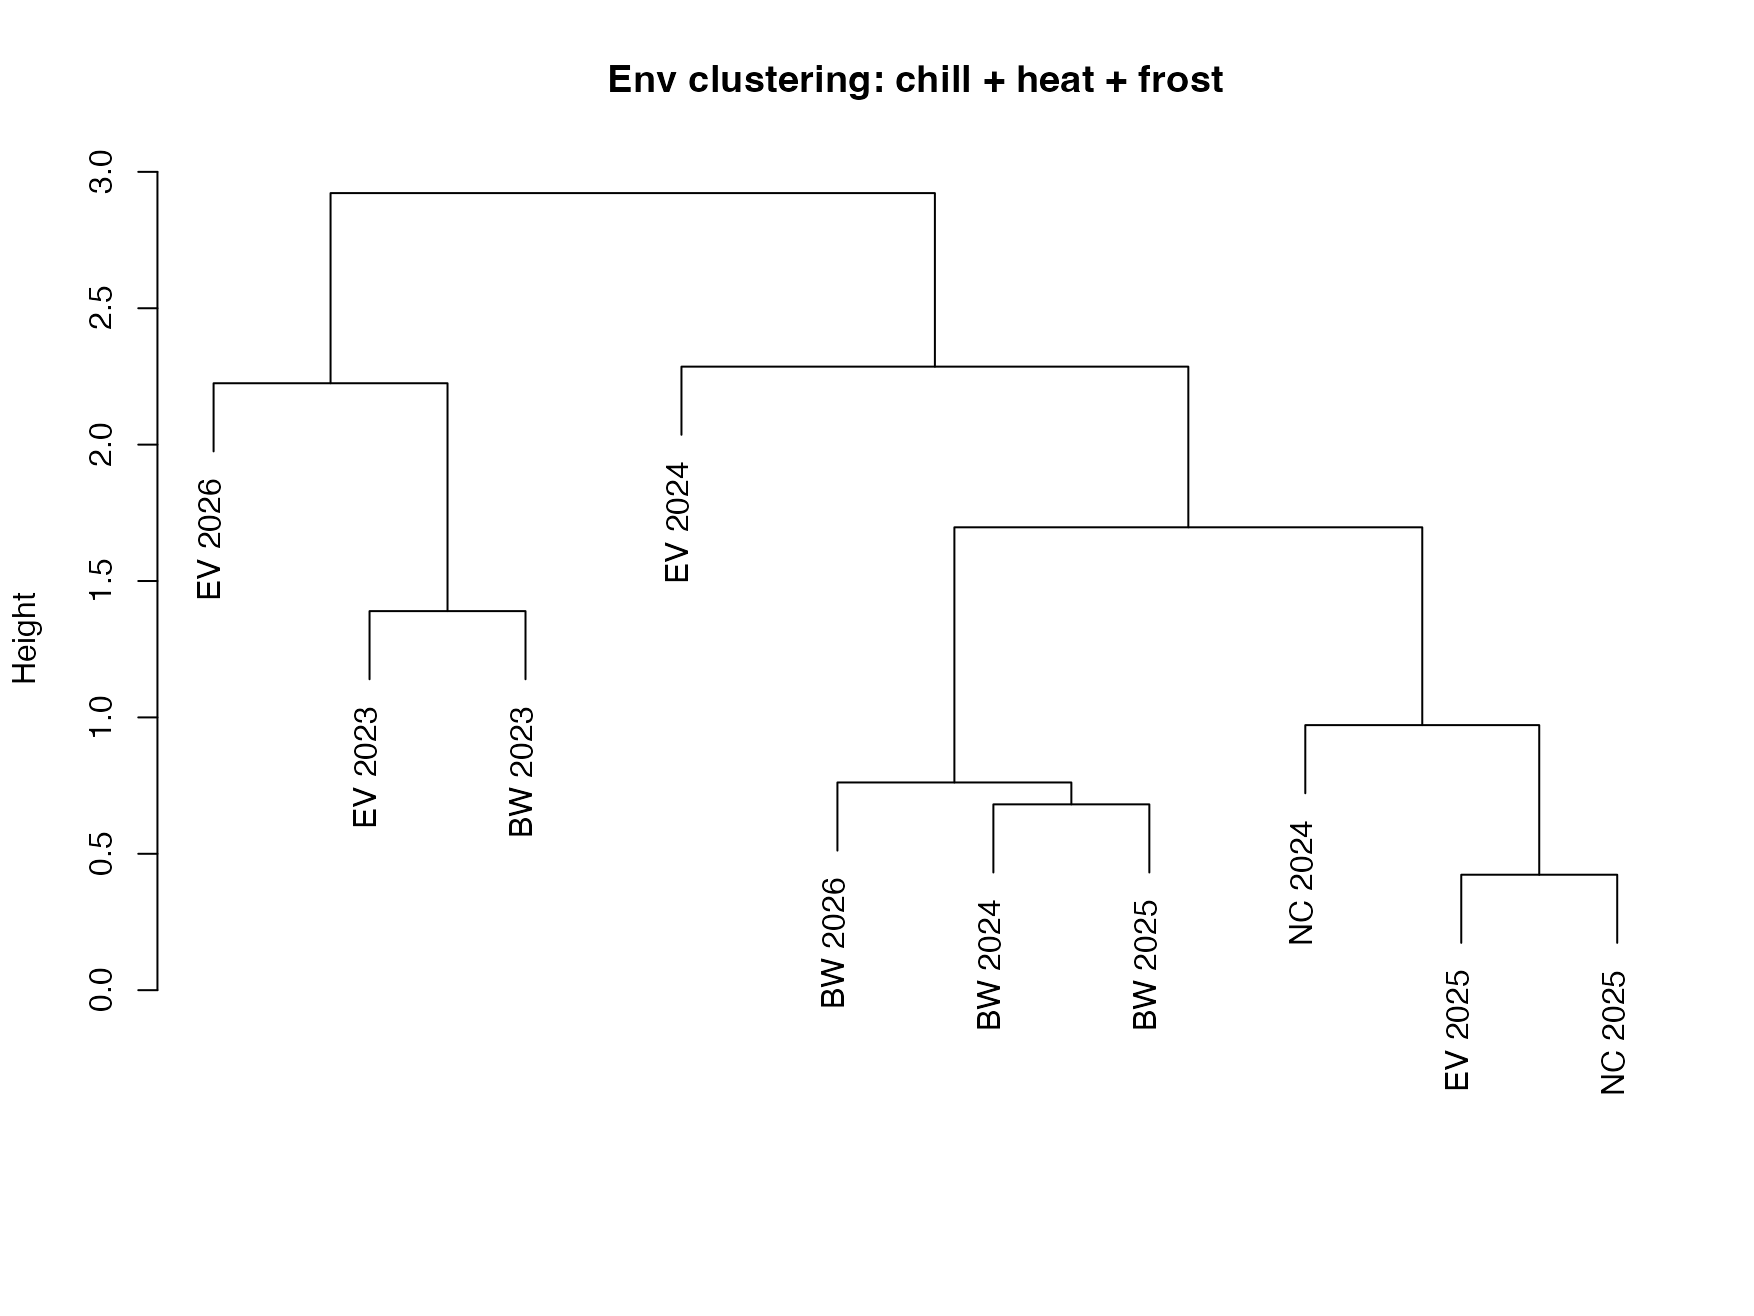

        EV 2023 EV 2024 EV 2025 EV 2026 BW 2023 BW 2024 BW 2025 BW 2026 NC 2024 NC 2025
EV 2023    0.00    3.76    2.90    1.53    1.39    2.24    2.22    2.07    2.84    3.20
EV 2024    3.76    0.00    1.94    2.91    4.86    2.39    3.01    3.14    1.31    1.92
EV 2025    2.90    1.94    0.00    2.13    3.99    1.20    1.47    1.97    0.85    0.42
EV 2026    1.53    2.91    2.13    0.00    2.92    2.18    2.32    2.55    2.21    2.27
BW 2023    1.39    4.86    3.99    2.92    0.00    3.05    2.90    2.52    3.89    4.35
BW 2024    2.24    2.39    1.20    2.18    3.05    0.00    0.68    0.82    1.12    1.62
BW 2025    2.22    3.01    1.47    2.32    2.90    0.68    0.00    0.70    1.71    1.86
BW 2026    2.07    3.14    1.97    2.55    2.52    0.82    0.70    0.00    1.92    2.39
NC 2024    2.84    1.31    0.85    2.21    3.89    1.12    1.71    1.92    0.00    1.09
NC 2025    3.20    1.92    0.42    2.27    4.35    1.62    1.86    2.39    1.09    0.00

In [ ]:
# Environmental clustering on env_clustering_covariates (chill + heat + frost
# together, now that all three are in one table out of the reworked stage06).
#
# Only the 3 real signal columns go in: Chill_Portions_sum, GDH_sum,
# frost_score. n_frost_hours_available and the frost_sept..frost_feb flags
# are diagnostic/intermediate (how the score was built, not additional
# signal) -- including the flags alongside frost_score would effectively
# double-count the same information with the same weights baked in twice.
#
# Scaling matters here for the same reason as before: Chill_Portions_sum
# (~35-65), GDH_sum (~5900-14000), and frost_score (0-1.1) are on very
# different scales -- without scaling, GDH would dominate and frost_score
# would barely register at all in the distance calculation.

library(dplyr)

Env_label = env_clustering_covariates %>%
  mutate(Env = paste(location, season)) %>%
  pull(Env)

clust_vars = env_clustering_covariates %>%
  dplyr::select(Chill_Portions_sum, GDH_sum, frost_score) %>%
  scale()

rownames(clust_vars) = Env_label

dist_mat = dist(clust_vars, method = "euclidean")
hc = hclust(dist_mat, method = "ward.D2")

plot(hc, main = "Env clustering: chill + heat + frost", xlab = "", sub = "")

# No k chosen on purpose -- look at the dendrogram first, decide how many
# groups actually look distinct, then:
#
#   cutree(hc, k = <your choice>)
#
# gives a named vector (Env -> cluster number) to compare against the FA
# model's Env grouping (e.g. the BW 2023 / EV 2023 / EV 2026 frost trio).

round(as.matrix(dist_mat), 2)

In [134]:
rg_ke1 = extract_rg_matrix_asreml_split(summary(fa3_ke1)$varcomp, env_levels, 3, 1)

In [140]:
rg_ke1 = extract_rg_matrix_asreml_split(summary(fa2_ke1)$varcomp, env_levels, 2, 1)

In [342]:
tar_load(fit_fa3_ke1_asr)

In [428]:
rg_ke1 = extract_rg_matrix_asreml_split(summary(fa2_ke2)$varcomp, env_levels, 2, 2)

In [141]:
nonadd_corr = rg_ke1$nonadditive$corr

In [306]:
env_levels

 [1] "BW 2023" "BW 2024" "BW 2025" "BW 2026" "EV 2023" "EV 2024" "EV 2025" "EV 2026" "NC 2024" "NC 2025"

In [ ]:
tar_load()

In [142]:
add_corr= rg_ke1$additive$corr

In [137]:
round(add_corr, 2)

        BW 2023 BW 2024 BW 2025 BW 2026 EV 2023 EV 2024 EV 2025 EV 2026 NC 2024 NC 2025
BW 2023    1.00    0.51   -0.05   -0.23    0.91    0.60    0.15    0.76    0.29    0.48
BW 2024    0.51    1.00    0.83    0.72    0.56    0.94    0.77    0.74    0.97    0.93
BW 2025   -0.05    0.83    1.00    0.98    0.03    0.72    0.82    0.40    0.94    0.75
BW 2026   -0.23    0.72    0.98    1.00   -0.11    0.58    0.75    0.22    0.86    0.66
EV 2023    0.91    0.56    0.03   -0.11    1.00    0.50    0.09    0.53    0.38    0.67
EV 2024    0.60    0.94    0.72    0.58    0.50    1.00    0.79    0.91    0.87    0.76
EV 2025    0.15    0.77    0.82    0.75    0.09    0.79    1.00    0.61    0.81    0.60
EV 2026    0.76    0.74    0.40    0.22    0.53    0.91    0.61    1.00    0.60    0.50
NC 2024    0.29    0.97    0.94    0.86    0.38    0.87    0.81    0.60    1.00    0.91
NC 2025    0.48    0.93    0.75    0.66    0.67    0.76    0.60    0.50    0.91    1.00

In [145]:
round(nonadd_corr, 2)

        BW 2023 BW 2024 BW 2025 BW 2026 EV 2023 EV 2024 EV 2025 EV 2026 NC 2024 NC 2025
BW 2023    1.00   -1.00    0.13    1.00    1.00   -1.00   -1.00    1.00    1.00   -0.71
BW 2024   -1.00    1.00   -0.13   -1.00   -1.00    1.00    1.00   -1.00   -1.00    0.71
BW 2025    0.13   -0.13    1.00    0.13    0.13   -0.13   -0.13    0.13    0.13   -0.09
BW 2026    1.00   -1.00    0.13    1.00    1.00   -1.00   -1.00    1.00    1.00   -0.71
EV 2023    1.00   -1.00    0.13    1.00    1.00   -1.00   -1.00    1.00    1.00   -0.71
EV 2024   -1.00    1.00   -0.13   -1.00   -1.00    1.00    1.00   -1.00   -1.00    0.71
EV 2025   -1.00    1.00   -0.13   -1.00   -1.00    1.00    1.00   -1.00   -1.00    0.71
EV 2026    1.00   -1.00    0.13    1.00    1.00   -1.00   -1.00    1.00    1.00   -0.71
NC 2024    1.00   -1.00    0.13    1.00    1.00   -1.00   -1.00    1.00    1.00   -0.71
NC 2025   -0.71    0.71   -0.09   -0.71   -0.71    0.71    0.71   -0.71   -0.71    1.00

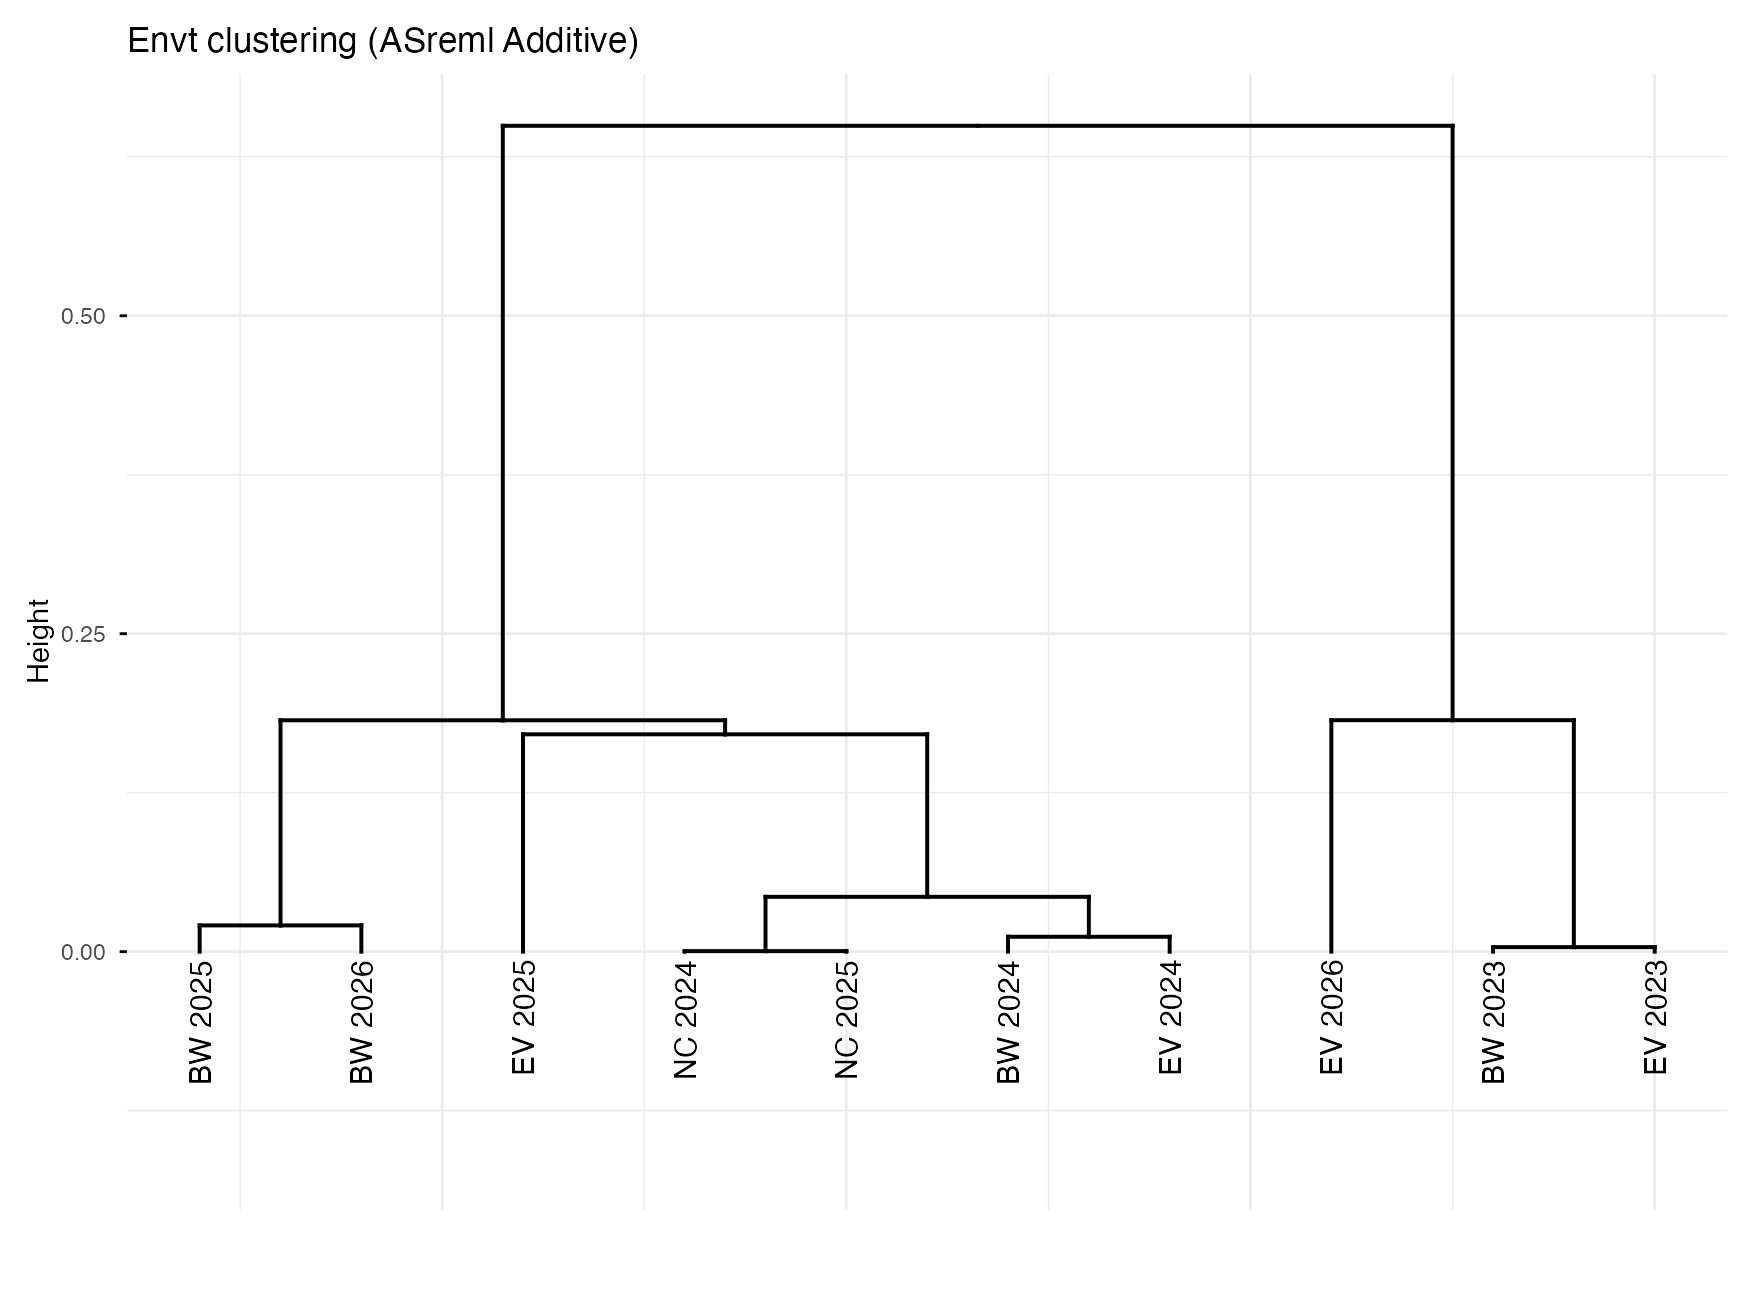

In [143]:
plot_hc(add_corr, 'ASreml Additive')

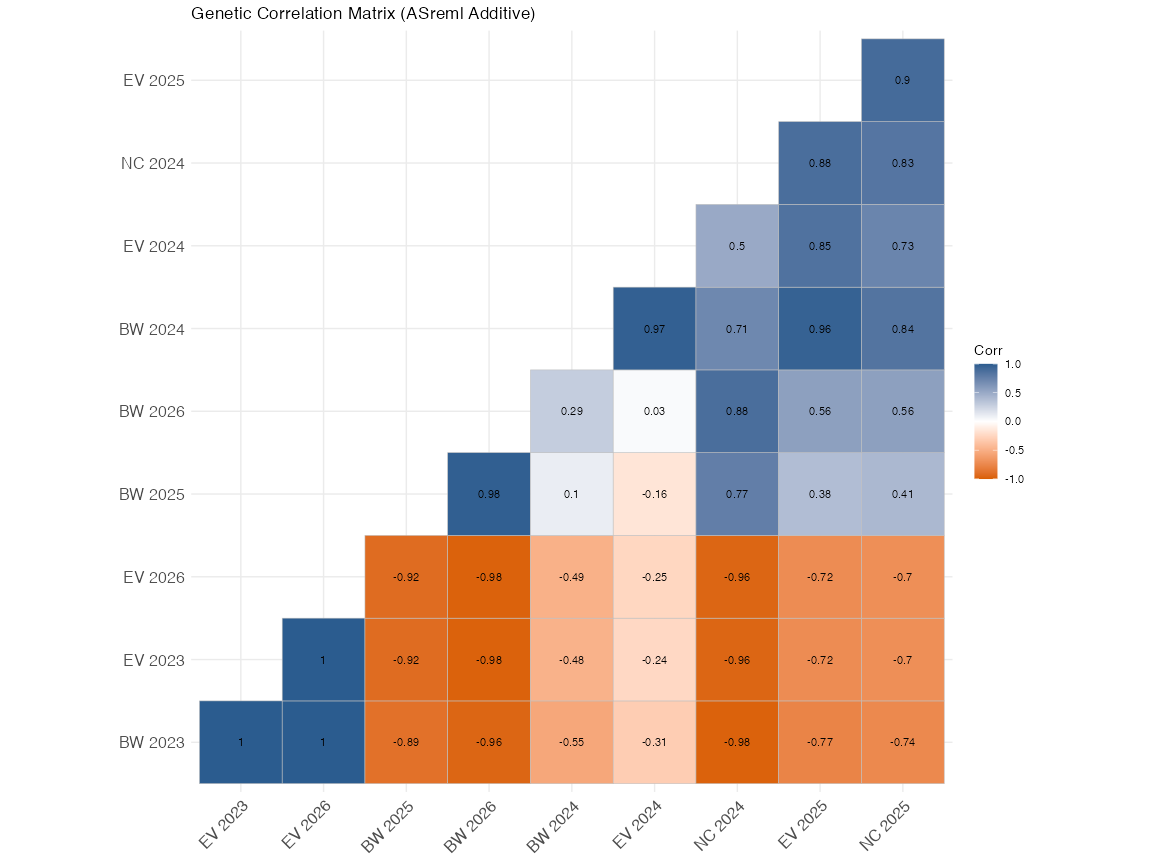

In [385]:
plot_corr(add_corr, 'ASreml Additive')

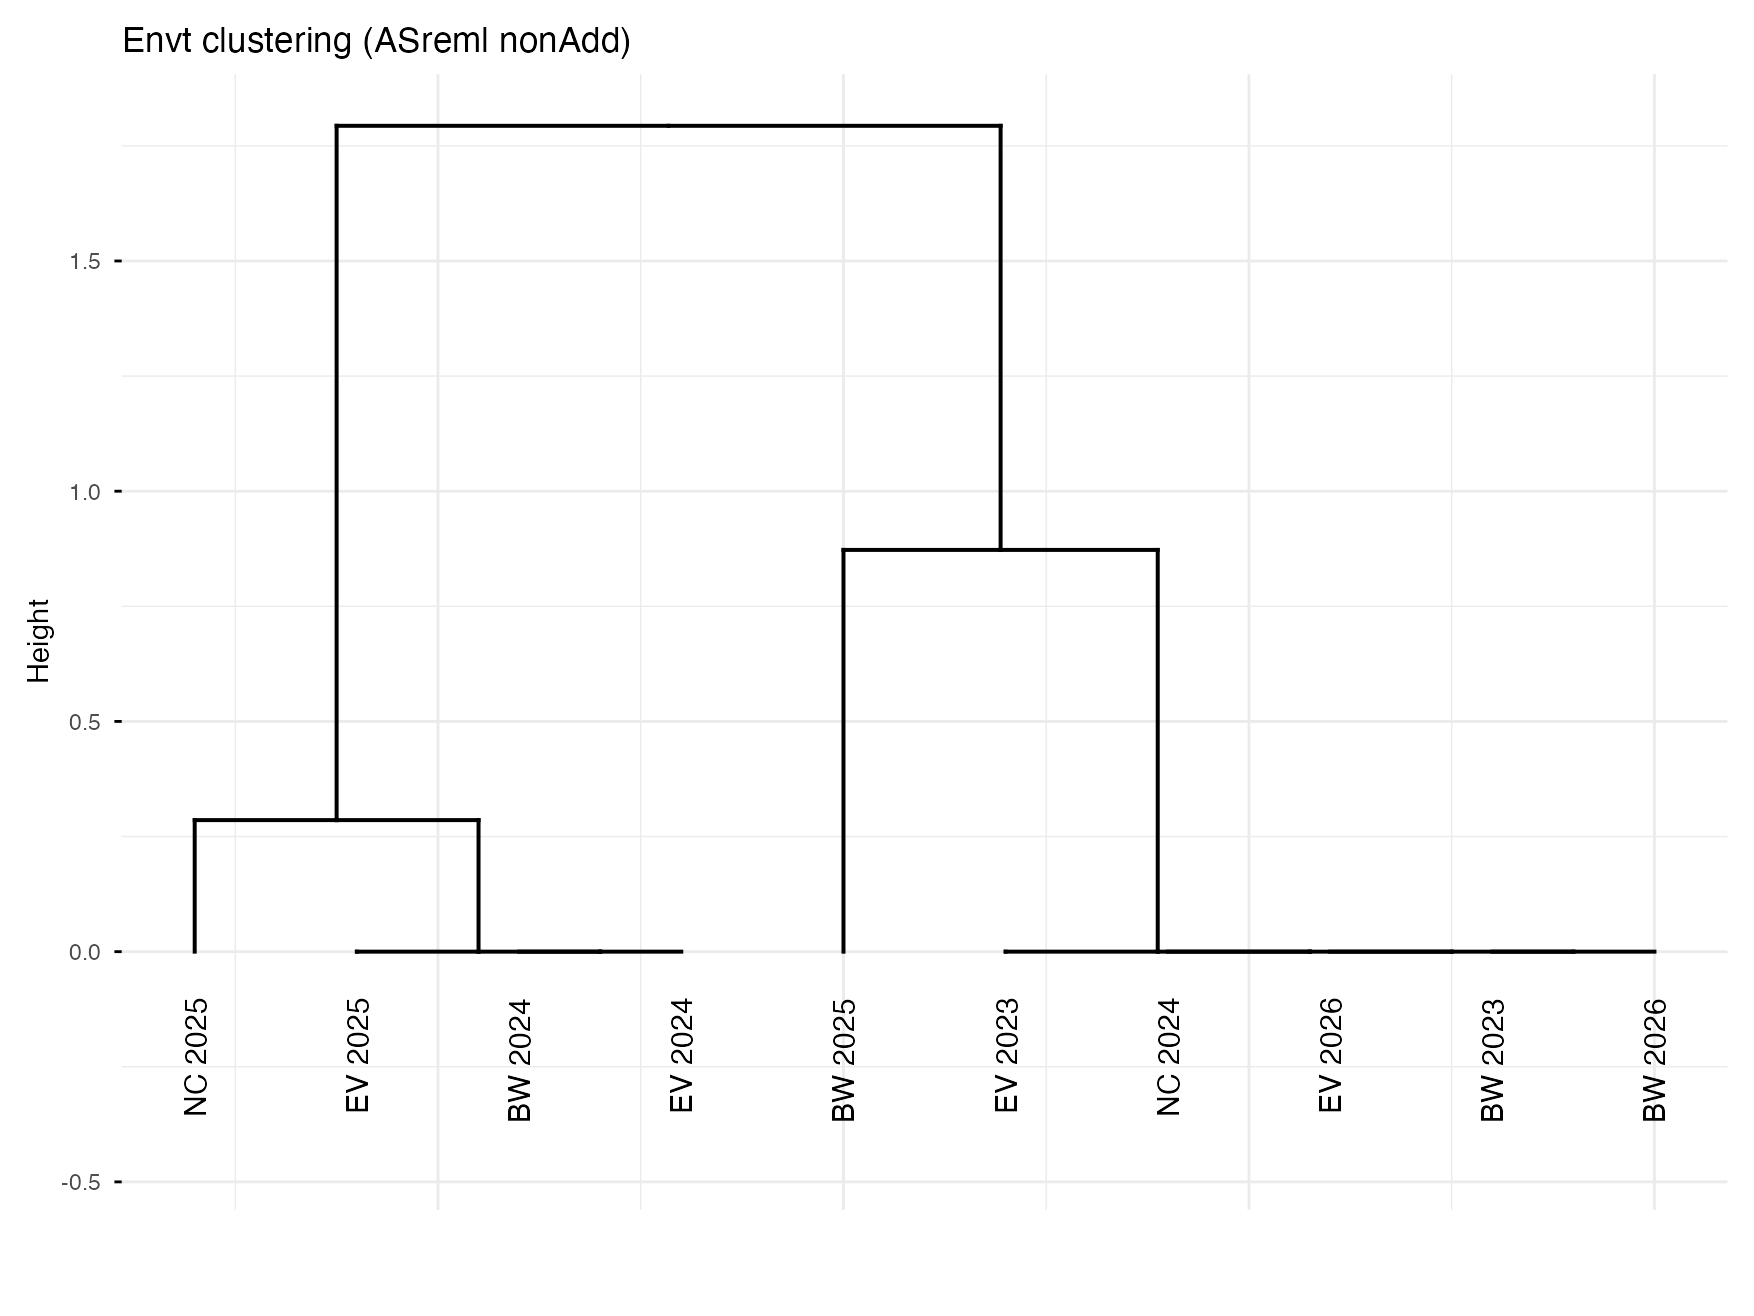

In [144]:
plot_hc(nonadd_corr, 'ASreml nonAdd')

In [35]:
extract_blups_asreml_additive <- function(fit, dta, Ainv, Dinv = NULL) {
  pv <- predict(fit, classify = "Env:Genotype", data = dta,
                onlyuse = ~fa(Env, k = 3):vm(Genotype, Ainv))$pvals
  env_fixed <- predict(fit, classify = "Env", data = dta)$pvals
  pv %>%
    mutate(Env = as.character(Env), Genotype = as.character(Genotype)) %>%
    left_join(
      env_fixed %>% transmute(Env = as.character(Env), env_effect = predicted.value),
      by = "Env"
    ) %>%
    transmute(Genotype, Env, blup = predicted.value - env_effect, se = std.error)
}

In [36]:
a = extract_blups_asreml_additive(fa3_min_ide, prep_and_scale_dta(prep_yield), g_mat, d_mat)

ASReml Version 4.2 24/10/2026 16:50:31
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -167.7698           1.0    848   16:50:31
  2     -167.7695           1.0    848   16:50:31
 3     -167.7691           1.0    848   16:50:31
ASReml Version 4.2 24/10/2026 16:50:31
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -167.7698           1.0    848   16:50:31
  2     -167.7695           1.0    848   16:50:31
 3     -167.7691           1.0    848   16:50:31


Warning messages:
1: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


In [474]:
tmp_dinv = Dinv

In [475]:
rm(Dinv)

In [245]:
# 09/13

library(dplyr)
library(asreml)

fit_single_trial_blue_asreml = function(trial_dta) {

  # has_block = 'block' %in% names(trial_dta) &&
  #   length(unique(trial_dta$block[!is.na(trial_dta$block)])) > 1

  dta = trial_dta %>% mutate(genotype = factor(genotype), block = factor(block)) %>%
    as.data.frame()
  
  # print(names(dta))

  # fixed_form = if (has_block) y ~ block + genotype else y ~ genotype

  fit = tryCatch(
    asreml(
      fixed    = y ~ block + genotype,
      residual = ~units,
      na.action = na.method(x = 'include'),
      data     = dta
    ),
    error = function(e) NULL
  )

  if (is.null(fit)) return(NULL)

  pred = predict(fit, classify = 'genotype')$pvals

  pred %>%
    transmute(
      genotype = as.character(genotype),
      predicted_value = predicted.value,
      std_error = std.error
    ) %>% rename(Genotype = genotype)
  
  # dta %>%
  #   mutate(fitted = fitted(fit), residual = residuals(fit)) %>%
  #   rename(Genotype = genotype)
}

In [251]:
# tar_load(al_yield_trial_dta)
# tar_load(nc_yield_trial_dta)
tar_load(yield_trial_dta_named)
use_dta = rbind(al_yield_trial_dta, nc_yield_trial_dta)
tar_load(yield_blues)

In [249]:
blues_dta = build_trait_blues_dta(use_dta)

: [1m[33mError[39m in `map2()`:[22m
[1m[22m[36mℹ[39m In index: 1.
[36mℹ[39m With name: season.
[1mCaused by error in `if (is.null(trial_dta) || nrow(trial_dta) == 0) ...`:[22m
[33m![39m missing value where TRUE/FALSE needed

In [252]:
dta = yield_blues %>%
    transmute(
      Genotype = factor(Genotype),
      Env   = factor(Env),
      predicted_value = predicted_value,
      std_error = std_error,
      wts = 1 / std_error^2
    ) %>%
    as.data.frame()


fit = asreml::asreml(
  fixed = predicted_value ~ Env + Genotype,
  random = ~Genotype:Env,
  data = dta,
  residual = ~dsum(~id(units) | Env),
  predict = asreml::predict.asreml(classify = 'Genotype', ignore = 'Genotype:Env'),
  weights = 'wts',
  aom = TRUE,
  sparse = ~Genotype,
  family   = asreml::asr_gaussian(dispersion = 1)
)

ASReml Version 4.2 21/10/2026 10:48:27
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
 1     -120.0973           1.0    202   10:48:27
 2     -112.3261           1.0    202   10:48:27
 3     -105.0409           1.0    202   10:48:27
 4     -101.8831           1.0    202   10:48:27
 5     -101.2735           1.0    202   10:48:27
 6     -101.2631           1.0    202   10:48:27
 7     -101.2630           1.0    202   10:48:27
Terms with zero df listed in attribute 'zerodf' of the wald table.


Warning message:
In asreml::asreml(fixed = predicted_value ~ Env + Genotype, random = ~Genotype:Env,  :


In [256]:
Rinv = fit$aom$R[,2]
alpha = 1 - .9973
critical_value = qt(alpha / 2, df = fit$nedf, lower.tail = FALSE)

In [260]:
is_outlier = abs(Rinv) > critical_value
is_outlier[is.na(is_outlier)] = FALSE

In [265]:
trt = 'yield'

In [267]:
outliers = droplevels(dta[is_outlier, ])
colnames(outliers) = gsub('predicted_value', trt, colnames(outliers))
colnames(outliers) = gsub('std_error', paste0(trt, '_SE'), colnames(outliers))
colnames(outliers) = gsub('wts', paste0(trt, '_wt'), colnames(outliers))
outliers = cbind(join = paste0(outliers$Genotype, outliers$Env), outliers)

blues_clean = droplevels(dta[!is_outlier, ])

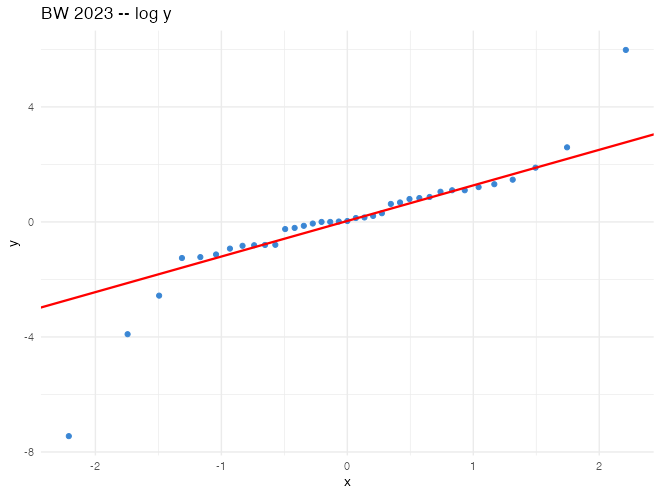

In [233]:
blues_dta %>% filter(Env == 'BW 2023') %>% ggplot( aes(sample = residual)) +
  stat_qq(colour = "#3a86d4") +
  stat_qq_line(colour = "red", linewidth = 0.8) +
  labs(title = 'BW 2023 -- log y') +
  theme_minimal()

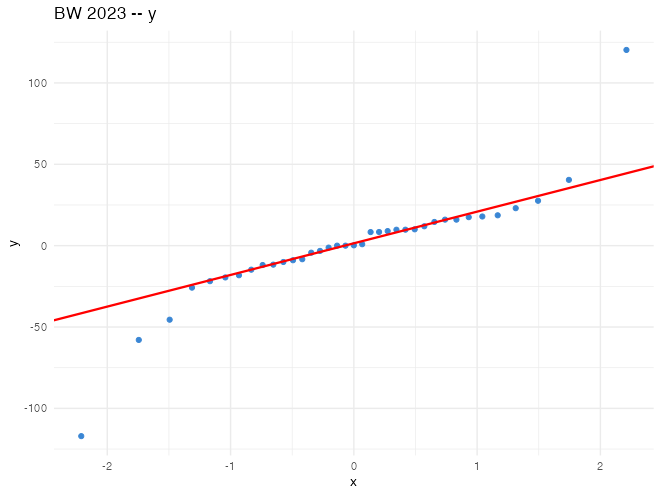

In [221]:
blues_dta %>% filter(Env == 'BW 2023') %>% ggplot( aes(sample = residual)) +
  stat_qq(colour = "#3a86d4") +
  stat_qq_line(colour = "red", linewidth = 0.8) +
  labs(title = 'BW 2023 -- y') +
  theme_minimal()

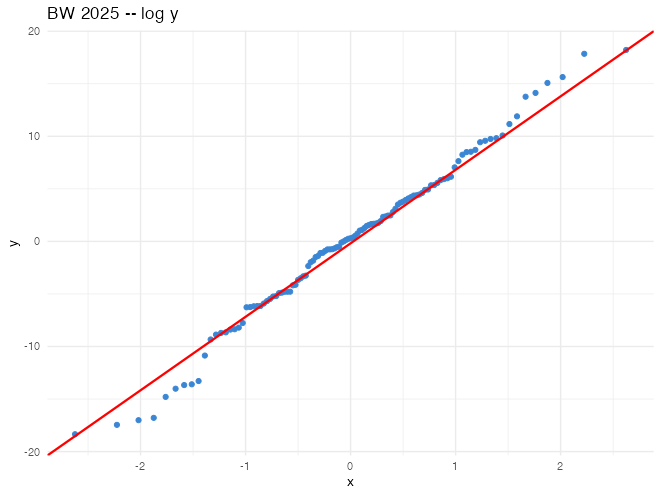

In [234]:
blues_dta %>% filter(Env == 'BW 2025') %>% ggplot( aes(sample = residual)) +
  stat_qq(colour = "#3a86d4") +
  stat_qq_line(colour = "red", linewidth = 0.8) +
  labs(title = 'BW 2025 -- log y') +
  theme_minimal()

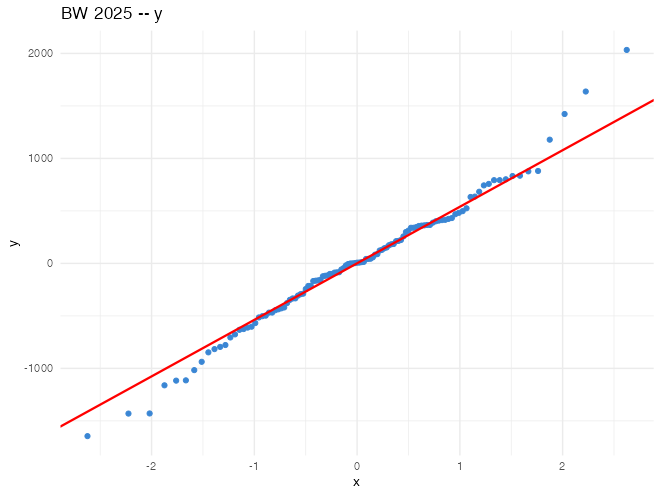

In [220]:
blues_dta %>% filter(Env == 'BW 2025') %>% ggplot( aes(sample = residual)) +
  stat_qq(colour = "#3a86d4") +
  stat_qq_line(colour = "red", linewidth = 0.8) +
  labs(title = 'BW 2025 -- y') +
  theme_minimal()

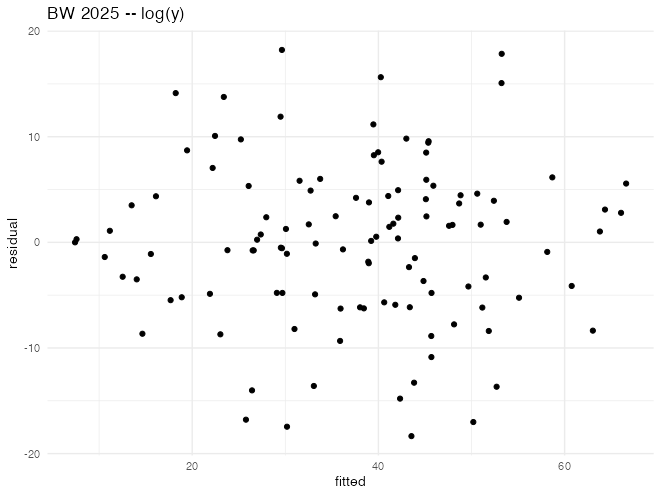

In [235]:
blues_dta %>% filter(Env == 'BW 2025') %>% ggplot(aes(x = fitted, y = residual))+ geom_point() + 
  labs(title = 'BW 2025 -- log(y)') + theme_minimal()

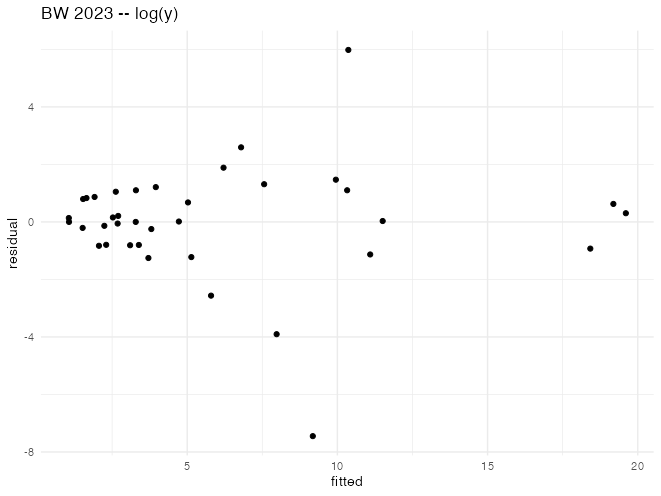

In [236]:
blues_dta %>% filter(Env == 'BW 2023') %>% ggplot(aes(x = fitted, y = residual))+ geom_point() + 
  labs(title = 'BW 2023 -- log(y)') + theme_minimal()

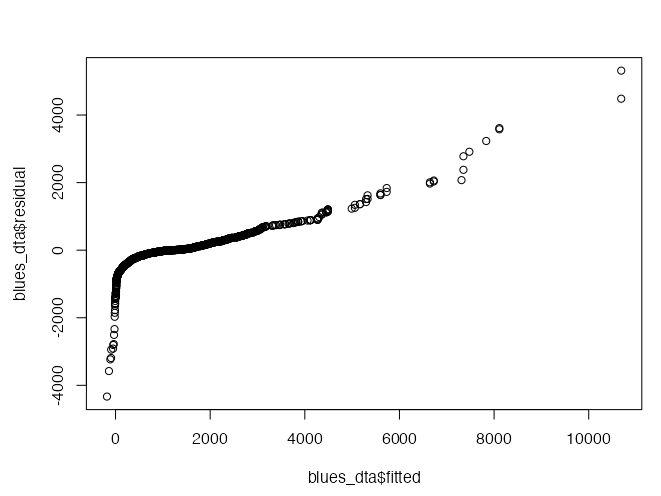

In [204]:
qqplot(blues_dta$fitted, blues_dta$residual)

In [145]:
# 09/13


library(dplyr)
library(purrr)
library(asreml)


build_trait_blues_dta = function(trial_dta_list, fit_fun = fit_single_trial_blue_asreml) {
  purrr::imap_dfr(trial_dta_list, function(trial_dta, env_name) {
    if (is.null(trial_dta) || nrow(trial_dta) == 0) return(NULL)
    blue = fit_fun(trial_dta)
    if (is.null(blue) || nrow(blue) == 0) return(NULL)
    blue %>% mutate(Env = env_name, .before = 1)
  })
}

# `blues_dta` needs columns Genotype, Env, predicted.value, std.error
# (as build_trait_blues_dta() produces). `trt` is only used to label the
# dropped-outlier columns for reporting (predicted.value -> <trt>,
# std.error -> <trt>.SE, wts -> <trt>.wt), matching the legacy script's
# convention of tagging which trait's outliers these are.
#
# Model: fixed = predicted.value ~ aoi + ge_id, random = ~ge_id:aoi,
# residual heterogeneous by aoi, weighted by the BLUE's own precision
# (1/SE^2) with dispersion fixed at 1 -- i.e. the weights are treated as
# the TRUE (not merely relative) variance, which is appropriate since
# these weights come from a real per-trial BLUE SE, not an assumed
# constant. Outliers are flagged via the aom externally studentized
# residual against a ~3-SD (99.73%) two-sided critical t-value, using
# the model's exact residual df rather than a flat "3".
detect_blue_outliers_asreml = function(blues_dta, trt) {

  dta = blues_dta %>%
    transmute(
      Genotype = factor(Genotype),
      Env   = factor(Env),
      predicted_value = predicted_value,
      std_error = std_error,
      wts = 1 / std_error^2
    ) %>%
    as.data.frame()


  fit = asreml::asreml(
    fixed = predicted_value ~ Env + Genotype,
    random = ~Genotype:Env,
    data = dta,
    residual = ~dsum(~id(units) | Env),
    predict = asreml::predict.asreml(classify = 'Genotype', ignore = 'Genotype:Env'),
    weights = 'wts',
    aom = TRUE,
    sparse = ~Genotype,
    family   = asreml::asr_gaussian(dispersion = 1)
  )

  Rinv = fit$aom$R[, 2]

  # alpha for a ~3-SD (99.73%) two-sided cutoff; use the exact alpha
  # rather than a flat "3" since the critical t-value shifts with df
  alpha = 1 - .9973
  critical_value = qt(alpha / 2, df = fit$nedf, lower.tail = FALSE)

  is_outlier = abs(Rinv) > critical_value
  is_outlier[is.na(is_outlier)] = FALSE

  outliers = droplevels(dta[is_outlier, ])
  colnames(outliers) = gsub('predicted_value', trt, colnames(outliers))
  colnames(outliers) = gsub('std_error', paste0(trt, '_SE'), colnames(outliers))
  colnames(outliers) = gsub('wts', paste0(trt, '_wt'), colnames(outliers))
  outliers = cbind(join = paste0(outliers$ge_id, outliers$aoi), outliers)

  blues_clean = droplevels(dta[!is_outlier, ])

  list(
    fit            = fit,
    critical_value = critical_value,
    outliers       = outliers,
    blues_clean    = blues_clean
  )
}

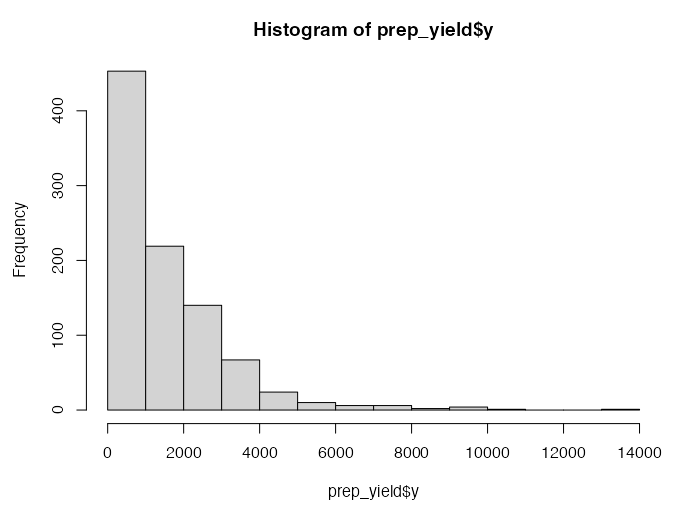

In [140]:
hist(prep_yield$y)

In [155]:
d = prep_and_scale_dta(prep_yield)

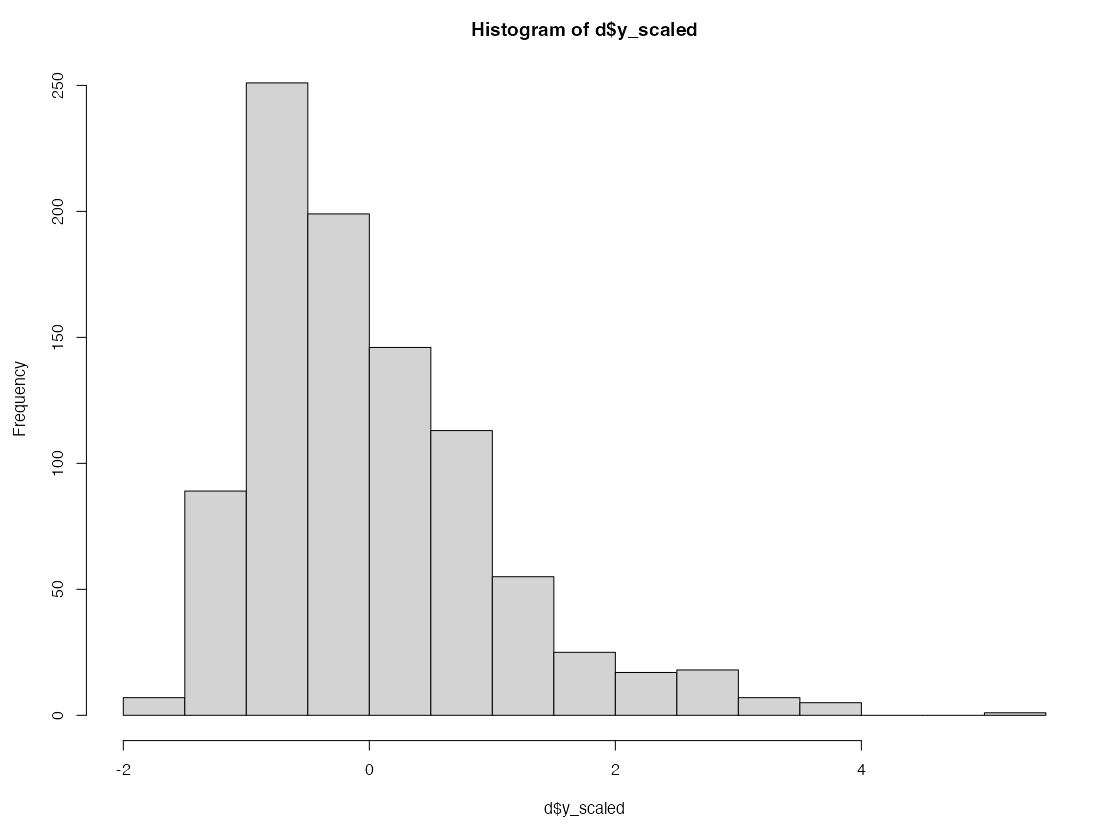

In [156]:
hist(d$y_scaled)

In [268]:
tar_load(prep_yield)

In [273]:
fit_fa3_asreml <- function(fa_dta, Ainv, maxiter = 300) {
  # dta = prep_and_scale_dta(fa_dta)
  dta = fa_dta %>% mutate(Genotype = factor(Genotype), Block = factor(Block), Env = factor(Env))

  fit <- asreml(
    fixed    = y ~ Env,
    random   = ~fa(Env, k = 3):vm(Genotype, Ainv) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit  = maxiter,
    ai.loadings = 5,   
    ai.penalty  = 15     
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}

In [274]:
fa3 = fit_fa3_asreml(prep_yield, a_inv)

ASReml Version 4.2 21/10/2026 22:04:21
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -452.3314           1.0    930   22:04:21  (  2 restrained)
  2     -412.6412           1.0    930   22:04:21  (  2 restrained)
  3     -392.2173           1.0    930   22:04:21  (  2 restrained)
  4     -383.4768           1.0    930   22:04:21  (  3 restrained)
  5     -380.6130           1.0    930   22:04:21  (  2 restrained)
  6     -377.9584           1.0    930   22:04:21  (  2 restrained)
  7     -375.8545           1.0    930   22:04:21  (  1 restrained)
  8     -374.3860           1.0    930   22:04:21  (  1 restrained)
  9     -373.4338           1.0    930   22:04:21  (  1 restrained)
 10     -372.8971           1.0    930   22:04:21  (  1 restrained)
 11     -372.6156           1.0    930   22:04:21  (  1 restrained)
 12     -372.3803           1.0    930   22:04:21  (  1 restrained)
 13     -372.2242           1.0    930   22:

Warning messages:
1: In asreml(fixed = y ~ Env, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y ~ Env, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


In [275]:
a = summary(fa3)$varcomp

In [ ]:
no_citra = prep_yield_split %>% filter(!Env %in% c('FL-Waldo 2024', 'FL-Waldo 2025'))

In [5]:
library(targets)
library(dplyr)


Attaching package: ‘dplyr’

The following objects are masked from ‘package:stats’:

    filter, lag

The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



In [27]:
tar_load(stab_fa3_total_ide_asr)
tar_load(stab_fa3_asr)
tar_load(blup_fa3_total_ide_asr_grams)
tar_load(blup_fa3_asr_grams)

In [12]:
stab_ide = stab_fa3_total_ide_asr$table %>% select(Genotype, OP_ide = OP) 
stab_d = stab_fa3_asr$table %>% select(Genotype, OP_base = OP)
stab = stab_ide %>% inner_join(stab_d, by = 'Genotype')
stab = stab %>% mutate(ide_rank = rank(-OP_ide, ties = 'average'), base_rank = rank(-OP_base, ties = 'average'))

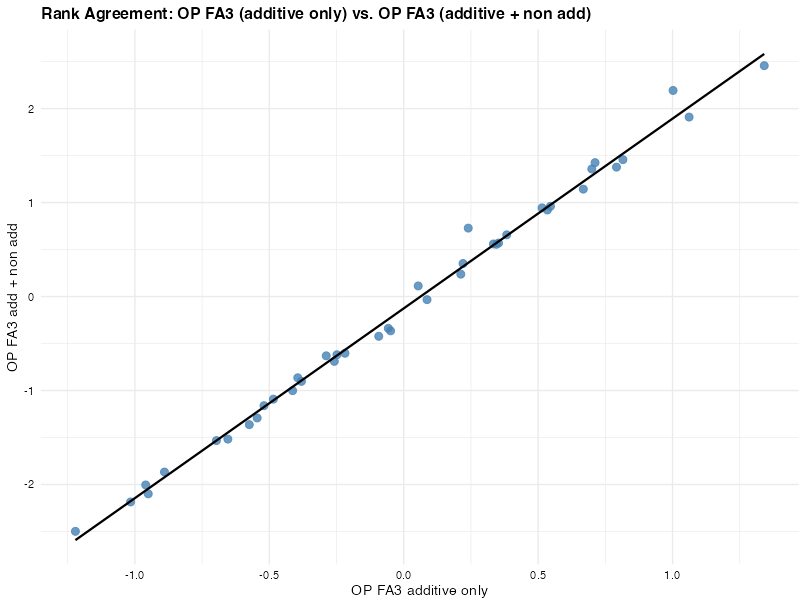

`geom_smooth()` using formula = 'y ~ x'

In [15]:
library(ggplot2)

ggplot(stab, aes(x = OP_base, y = OP_ide)) +
  # 1:1 line representing perfect rank consistency
  # geom_abline(intercept = 0, slope = 1, linetype = "dashed", color = "gray50") +
  # Scatter points
  geom_point(size = 2.5, alpha = 0.8, color = "steelblue") +
  # Optional: Linear trend line
  geom_smooth(method = "lm", se = FALSE, color = "black", linewidth = 0.8) +
  labs(
    title = "Rank Agreement: OP FA3 (additive only) vs. OP FA3 (additive + non add)",
    x = "OP FA3 additive only",
    y = "OP FA3 add + non add"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(face = "bold", size = 12),
    axis.title = element_text(size = 11, color = "black"),
    axis.text  = element_text(color = "black")
  )

In [34]:
mb = blup_fa3_asr_grams %>% group_by(Genotype) %>%
  summarize(mean_blup = mean(blup))

mb = mb %>% inner_join(stab_fa3_asr$table, by = 'Genotype')

mb = mb %>% mutate(OP_rank = rank(-OP, ties.method = 'average'),
MeanBlups_rank = rank(-mean_blup, ties.method = 'average'))

cor.test(mb$OP_rank, mb$MeanBlups_rank, method = 'spearman')


	Spearman's rank correlation rho

data:  mb$OP_rank and mb$MeanBlups_rank
S = 134, p-value < 2.2e-16
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.9883275 


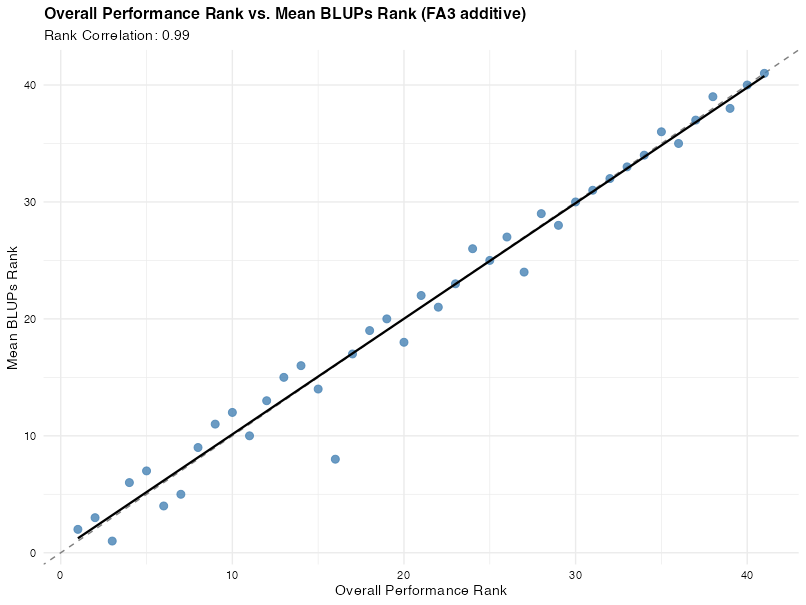

`geom_smooth()` using formula = 'y ~ x'

In [35]:
ggplot(mb, aes(x = OP_rank, y = MeanBlups_rank)) +
  # 1:1 line representing perfect rank consistency
  geom_abline(intercept = 0, slope = 1, linetype = "dashed", color = "gray50") +
  # Scatter points
  geom_point(size = 2.5, alpha = 0.8, color = "steelblue") +
  # Optional: Linear trend line
  geom_smooth(method = "lm", se = FALSE, color = "black", linewidth = 0.8) +
  labs(
    title = "Overall Performance Rank vs. Mean BLUPs Rank (FA3 additive)",
    subtitle = 'Rank Correlation: 0.99',
    x = "Overall Performance Rank",
    y = "Mean BLUPs Rank"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(face = "bold", size = 12),
    axis.title = element_text(size = 11, color = "black"),
    axis.text  = element_text(color = "black")
  )

In [20]:
mb = blup_fa3_total_ide_asr_grams %>% group_by(Genotype) %>%
  summarize(mean_blup = mean(blup))

mb = mb %>% inner_join(stab_fa3_min_ide_asr$table, by = 'Genotype')

mb = mb %>% mutate(OP_rank = rank(-OP, ties.method = 'average'),
MeanBlups_rank = rank(-mean_blup, ties.method = 'average'))

cor.test(mb$OP_rank, mb$MeanBlups_rank, method = 'spearman')


	Spearman's rank correlation rho

data:  mb$OP_rank and mb$MeanBlups_rank
S = 134, p-value < 2.2e-16
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.9883275 


In [23]:
plot_fw_trellis <- function(fw_fit, genotypes, trait_label = "Yield", color_by = "loc") {

  # one row per genotype x trial, with loc/year/trait kept for coloring
  td_long <- purrr::map_dfr(fw_fit$TD, as.data.frame, .id = "trial_name") %>%
    mutate(trial = as.character(trial))

  env_idx <- fw_fit$envEffs %>%
    transmute(trial = as.character(Trial), EnvMean)

  grand_index <- mean(env_idx$EnvMean)

  plot_dta <- td_long %>%
    left_join(env_idx, by = "trial") %>%
    filter(genotype %in% genotypes) %>%
    mutate(Genotype = factor(genotype, levels = genotypes))

  # fitted FW line per genotype: GenMean + Sens * (index - mean(index)) --
  # same line plot(fw_fit, plotType = "trellis") draws, read straight off
  # estimates rather than refit here
  line_dta <- fw_fit$estimates %>%
    filter(Genotype %in% genotypes) %>%
    mutate(Genotype = factor(Genotype, levels = genotypes)) %>%
    tidyr::crossing(index = range(env_idx$EnvMean)) %>%
    mutate(fitted = GenMean + Sens * (index - grand_index))

  ggplot(plot_dta, aes(x = EnvMean, y = trait)) +
    geom_line(data = line_dta, aes(x = index, y = fitted), colour = "black", linewidth = 0.5) +
    geom_point(aes(colour = .data[[color_by]]), size = 2.5) +
    facet_wrap(vars(Genotype)) +
    scale_colour_viridis_d(name = tools::toTitleCase(color_by)) +
    labs(x = "Environmental index", y = trait_label, title = paste0("Finlay-Wilkinson regression - ", trait_label)) +
    theme_minimal(base_size = 12) +
    theme(
      strip.background = element_rect(fill = "grey85", colour = "grey50"),
      strip.text        = element_text(colour = "black", face = "bold"),
      panel.border      = element_rect(colour = "grey50", fill = NA),
      panel.grid.minor  = element_blank(),
      panel.grid.major  = element_line(colour = "grey90")
    )
}



In [ ]:




prepare_td <- function(blup_long, use_col = "trait", tested = NULL) {
  d <- blup_long %>%
    tidyr::separate(Env, into = c("loc", "year"), sep = " ", remove = FALSE) %>%
    mutate(year = as.integer(year))

  if (!is.null(tested)) {
    d <- d %>%
      left_join(tested %>% mutate(.tested = TRUE), by = c("Genotype", "Env")) %>%
      mutate(trait = ifelse(is.na(.tested), NA_real_, .data[[use_col]])) %>%
      dplyr::select(-.tested)
  } else {
    d <- d %>% mutate(trait = .data[[use_col]])
  }

  statgenSTA::createTD(
    data      = as.data.frame(d),
    genotype  = "Genotype",
    trial     = "Env",
    loc       = "loc",
    year      = "year"
  )
}

# ------------------------------------------------------------
# 2. Finlay-Wilkinson regression.
#    One slope (b_i) + one intercept (BLUP-of-mean, g_i) per genotype.
#    Per last turn's discussion: this collapses whatever multi-dimensional
#    structure your FA model found (BW2023/EV2023/EV2026 as a distinct
#    3rd factor) into a single responsiveness number -- treat this as the
#    familiar, stakeholder-facing cross-check, not a replacement read.
# ------------------------------------------------------------
run_fw <- function(td, trait = "trait") {
  fit <- gxeFw(td, trait = trait)
  list(
    fit   = fit,
    table = fit$estimates,   # genotype, intercept (b0), slope (b1), MSdeviation
    plot_scatter = function() plot(fit, plotType = "scatter"),
    plot_line    = function() plot(fit, plotType = "line")
  )
}

# ------------------------------------------------------------
# 3. Classic AMMI: additive main effects (G + E) estimated by ANOVA,
#    then SVD on the G x E interaction residual only.
# ------------------------------------------------------------
run_ammi <- function(td, trait = "trait", n_pc = 3) {
  fit <- gxeAmmi(td, trait = trait, nPC = n_pc)
  list(
    fit = fit,
    plot_ammi1 = function() plot(fit, plotType = "AMMI1"),   # mean vs PC1
    plot_ammi2 = function() plot(fit, plotType = "AMMI2")    # PC1 vs PC2 biplot
  )
}

# ------------------------------------------------------------
# 4. GGE: centers by environment mean only (keeps G + GE together), then
#    SVD on that combined matrix. This is the one that gives you the
#    familiar "which-won-where" / mega-environment biplot.
# ------------------------------------------------------------
run_gge <- function(td, trait = "trait") {
  fit <- gxeGGE(td, trait = trait)
  list(
    fit = fit,
    plot_biplot    = function() plot(fit, plotType = "AMMI2"),
    plot_which_won = function() plot(fit, plotType = "AMMI2", primePlot = TRUE)
    # NOTE: confirm the exact argument statgenGxE uses for the polygon /
    # which-won-where overlay on a GGE biplot -- recalled, not verified.
    # If this doesn't produce the polygon view, check the plot.AMMI help
    # page directly; the sector/polygon overlay is what delineates mega-
    # environments visually, not a separately-named function.
  )
}


run_mega <- function(td, trait = "trait") {
  fit <- gxeMegaEnv(td, trait = trait)
  list(
    fit = fit,
    plot_mega = function() plot(fit)
    # plot_which_won = function() plot(fit, plotType = "AMMI2", primePlot = TRUE)
    # NOTE: confirm the exact argument statgenGxE uses for the polygon /
    # which-won-where overlay on a GGE biplot -- recalled, not verified.
    # If this doesn't produce the polygon view, check the plot.AMMI help
    # page directly; the sector/polygon overlay is what delineates mega-
    # environments visually, not a separately-named function.
  )
}


run_stability <- function(td, trait = "trait") {
  fit <- gxeStability(td, trait = trait)
  list(
    fit = fit,
    summary = summary(fit, pctGeno = 2),
    plot_stab    = function() plot(fit)
    # plot_which_won = function() plot(fit, plotType = "AMMI2", primePlot = TRUE)
    # NOTE: confirm the exact argument statgenGxE uses for the polygon /
    # which-won-where overlay on a GGE biplot -- recalled, not verified.
    # If this doesn't produce the polygon view, check the plot.AMMI help
    # page directly; the sector/polygon overlay is what delineates mega-
    # environments visually, not a separately-named function.
  )
}

# ------------------------------------------------------------
# 5. Cross-check against the FA model: do AMMI/GGE's genotype scores
#    agree with fa_stability()'s f1/OP on who the outliers are? This is
#    the actual payoff from last turn's discussion -- triangulation from
#    a completely different estimation framework (fixed-effects SVD vs.
#    your mixed FA-GBLUP model).
# ------------------------------------------------------------
cross_check_vs_fa <- function(ammi_fit, stab_table) {
  ammi_scores <- as.data.frame(ammi_fit$fit$genoScores) %>%
    tibble::rownames_to_column("Genotype")

  merged <- stab_table %>%
    dplyr::select(Genotype, f1, OP, RMSD) %>%
    left_join(ammi_scores, by = "Genotype")

  list(
    table = merged,
    cor_f1_pc1   = suppressWarnings(cor(merged$f1,   merged$PC1, method = "spearman")),
    cor_rmsd_pc2 = suppressWarnings(cor(merged$RMSD, abs(merged$PC2), method = "spearman"))
  )
}
# High cor_f1_pc1 = AMMI's PC1 (usually the dominant "overall performance"
# axis) agrees with the FA model's f1/OP on genotype ranking -- expected,
# both are trying to capture the same main signal.
# cor_rmsd_pc2 is the more interesting one: AMMI's interaction-only PC2
# captures instability in a completely different way than RMSD does
# (fixed-effects residual SVD vs. deviation-from-factor-1-regression).
# If NC5289/MS2162/SanJoaquin show up as extreme on both, that's the
# triangulation worth reporting. If they diverge, that's worth
# understanding before trusting either one alone.

# ============================================================
# USAGE
# ============================================================
# blup_long <- res$fa[["2"]]$blups          # from your LOEO/baseline FA fit
# tested    <- prep_y %>% distinct(Genotype, Env)
#
# td   <- prepare_td(blup_long)
# fw   <- run_fw(td)
# ammi <- run_ammi(td)
# gge  <- run_gge(td)
#
# fw$plot_line()
# ammi$plot_ammi2()
# gge$plot_which_won()
#
# check <- cross_check_vs_fa(ammi, stab$table)   # stab from fa_stability()
# check$cor_f1_pc1; check$cor_rmsd_pc2

In [40]:
tar_load(prep_yield)

In [71]:
prep_and_scale_dta = function(fa_dta){
  fa_dta = fa_dta %>%
    mutate(Genotype = factor(Genotype), Env = factor(Env), Block = factor(Block)) %>%
    arrange(Env)
 
  env_stats = fa_dta %>% group_by(Env) %>%
    summarize(mean_env = mean(y, na.rm = TRUE), sd_env = sd(y, na.rm = TRUE))
 
  fa_dta_scaled = fa_dta %>% left_join(env_stats, by = 'Env') %>%
    mutate(y_scaled = (y - mean_env) / sd_env)
}

reconstruct_adjusted_means <- function(blup_long, env_stats) {
  blup_long %>%
    left_join(env_stats, by = "Env") %>%
    mutate(trait = mean_env + blup * sd_env)  
}        
env_stats <- prep_and_scale_dta(prep_yield) %>% distinct(Env, mean_env, sd_env)

In [50]:
names(blup_fa3_total_ide_asr_grams)

 [1] "Genotype"      "Env"           "blup_additive" "se_additive"   "g_e"           "se_e"          "blup"         
 [8] "se"            "mean_env"      "sd_env"        "blup_sqrt"     "se_sqrt"       "blup_original" "se_original"  
[15] "blup_sqrt_abs" "blup_median"   "env_var"       "blup_mean"    

In [94]:
tar_load(blup_fa2_asr_bloom_bloom5)
tar_load(blup_fa2_asr_bloom_bloom_duration)
tar_load(blup_fa2_total_ide_asr_bloom_bloom5)
tar_load(prep_bloom_bloom5)
tar_load(prep_bloom_bloom_duration)
tar_load(prep_ph)
tar_load(blup_fa2_asr_ph)
tar_load(blup_fa2_asr_qual_avg_berry_weight)
tar_load(prep_qual_avg_berry_weight)

tar_load(blup_fa2_asr_qual_brix)
tar_load(prep_qual_brix)

tar_load(blup_fa2_asr_qual_ta)
tar_load(prep_qual_ta)

tar_load(blup_fa2_asr_qual_firmness)
tar_load(prep_qual_firmness)

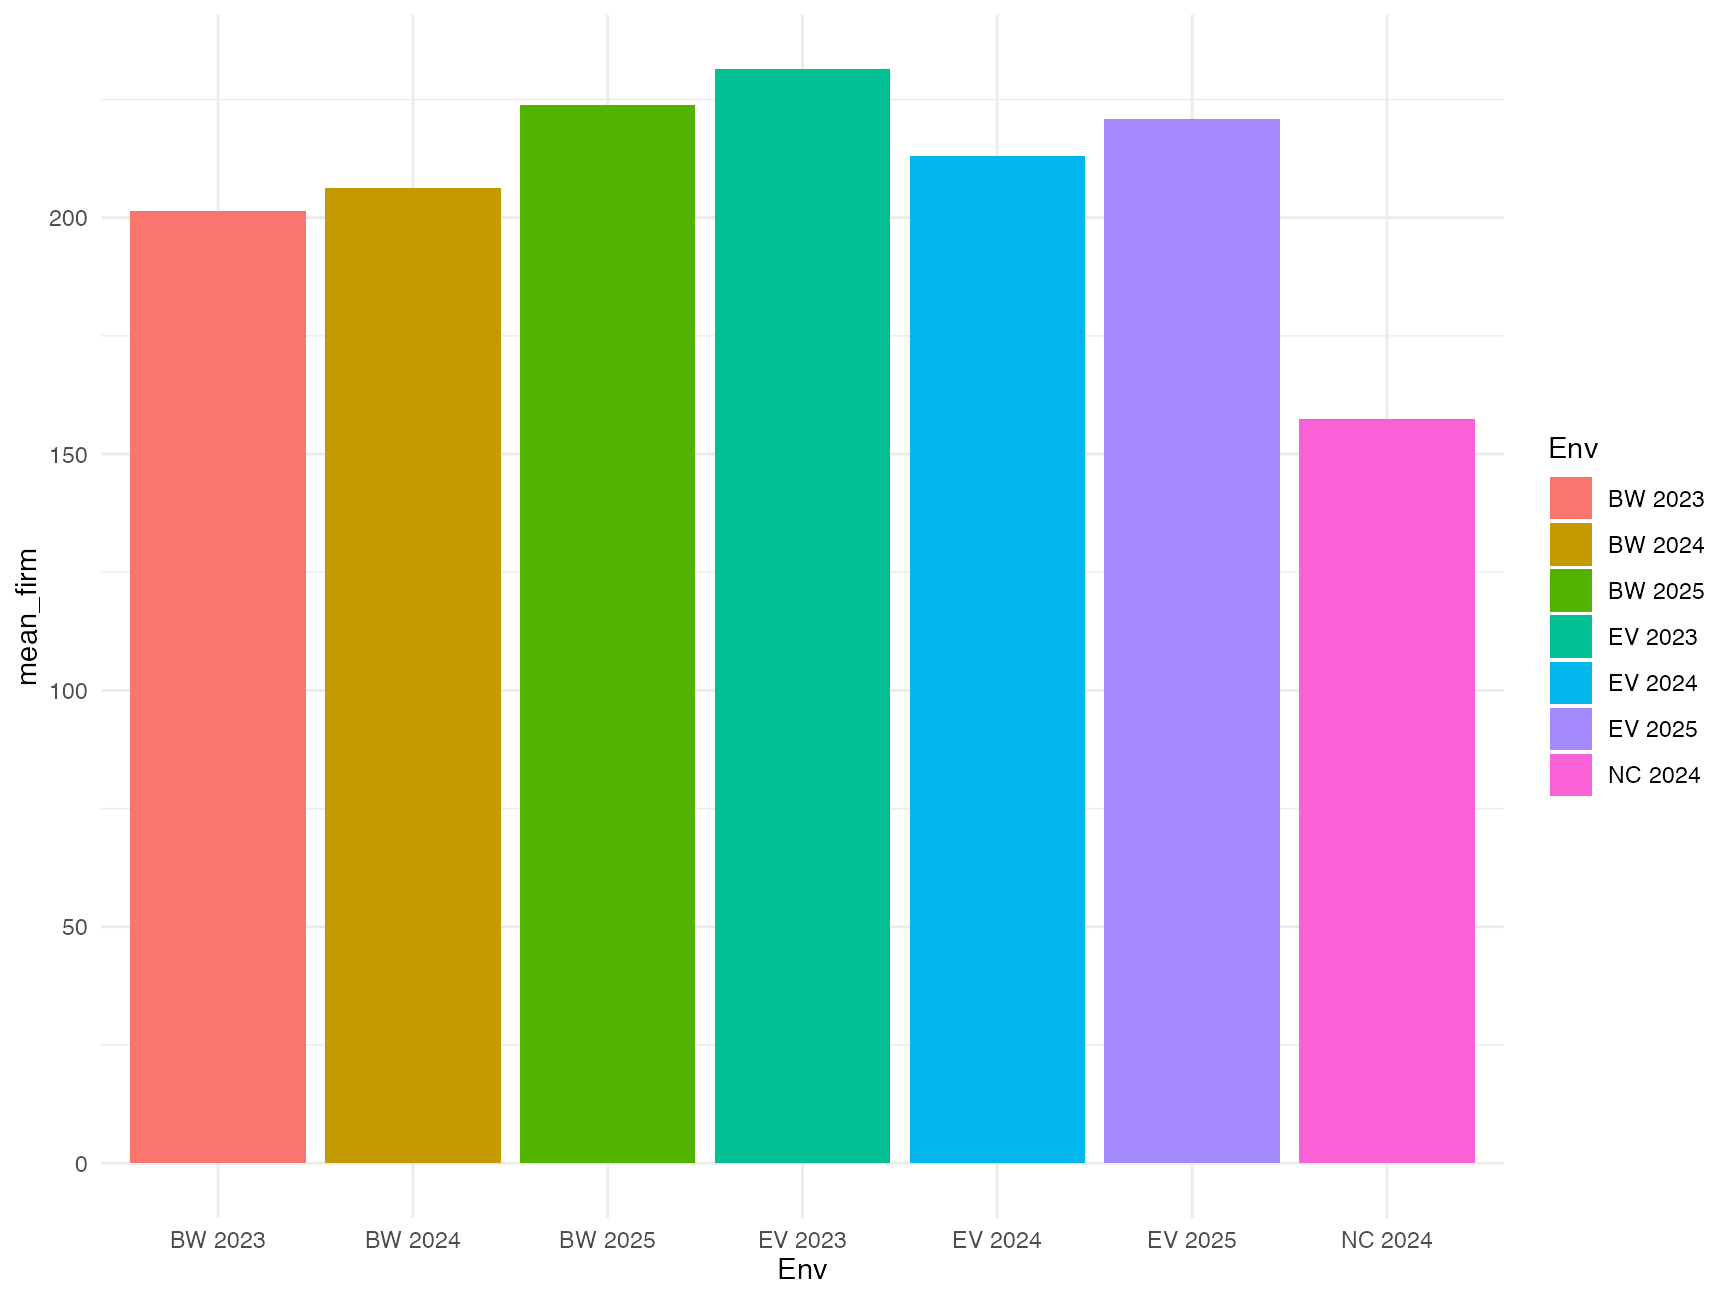

In [111]:
prep_qual_firmness %>% group_by(Env) %>% summarize(mean_firm = mean(y)) %>% mutate(Env = factor(Env)) %>%
  ggplot(aes(x = Env, y = mean_firm, fill = Env)) +
  geom_col(position = 'dodge') + theme_minimal()

Warning message:
In anova.lm(modelA) :
  ANOVA F-tests on an essentially perfect fit are unreliable


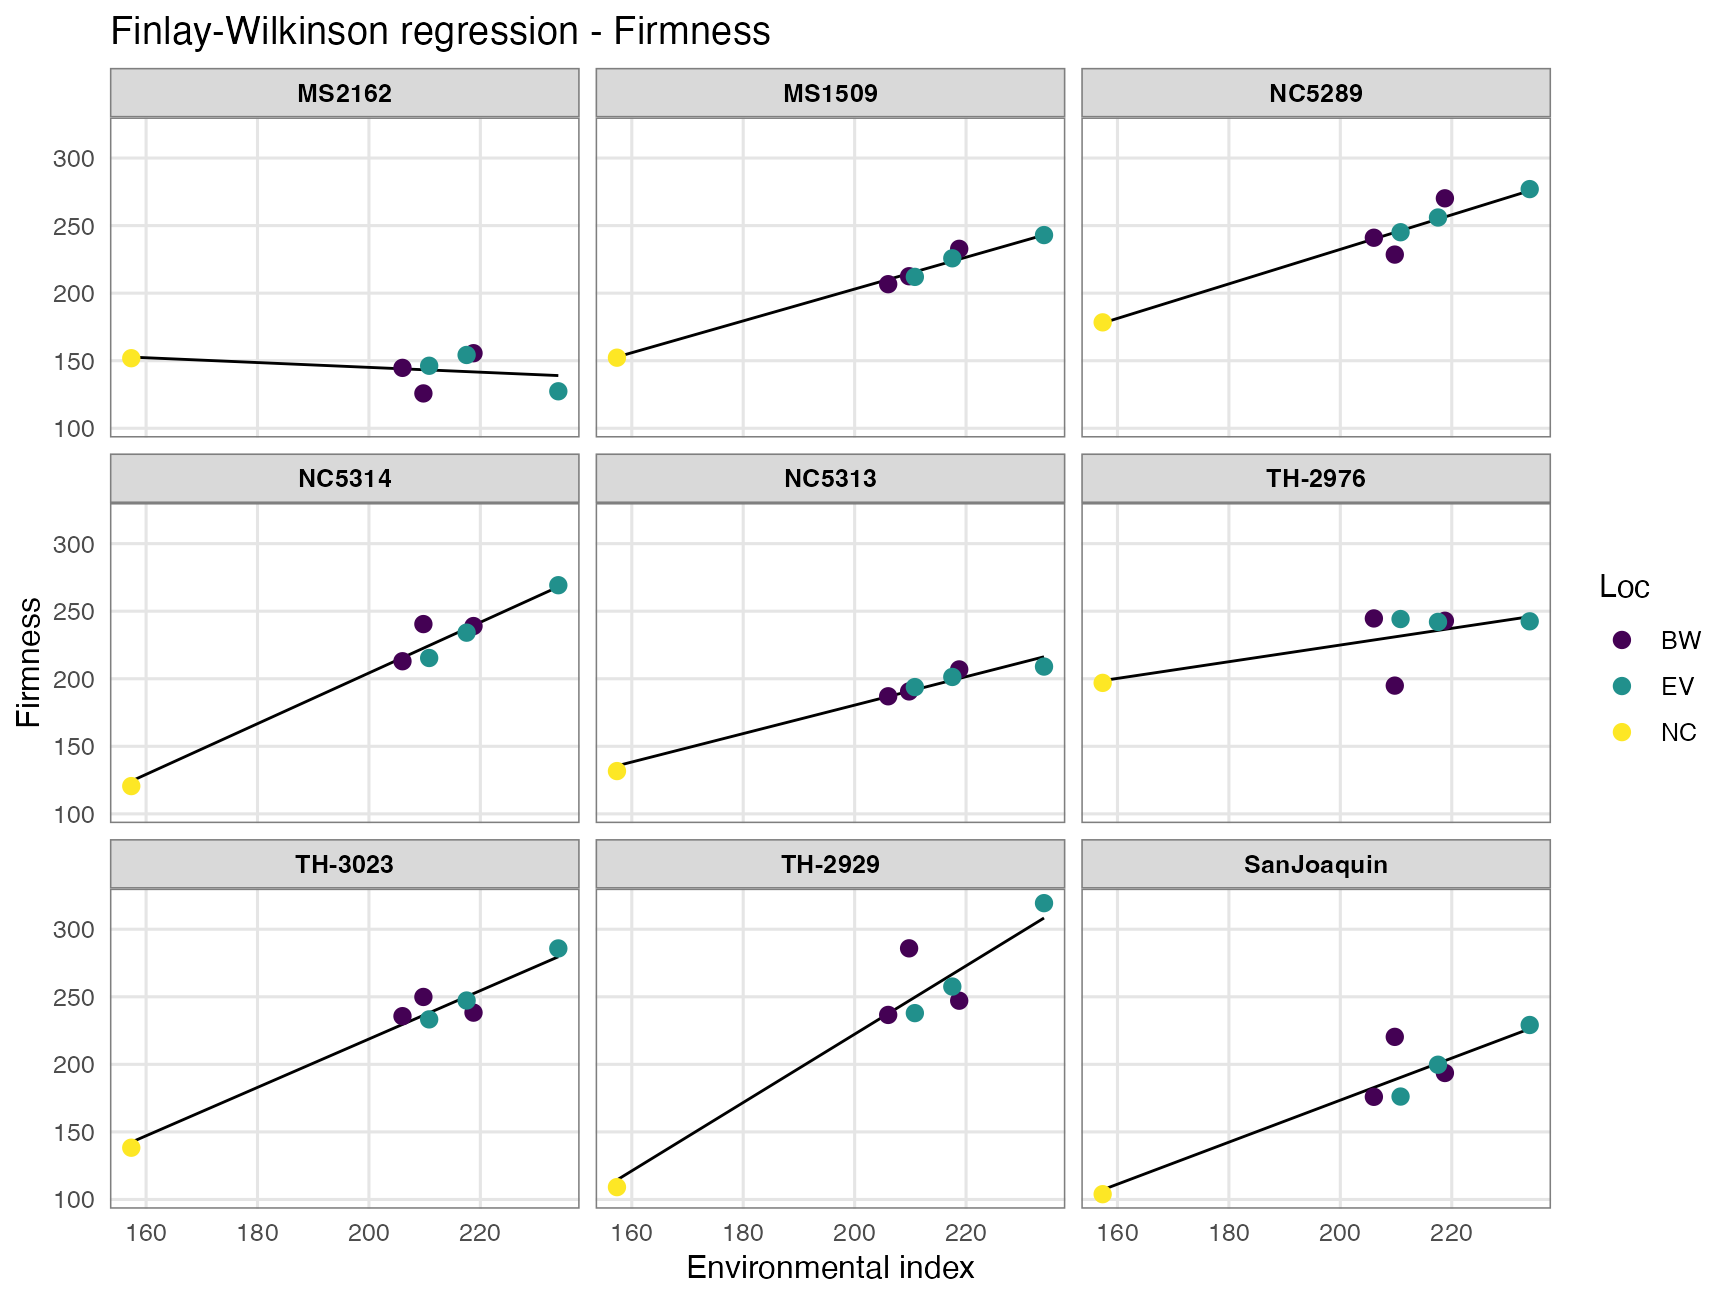

In [96]:
env_stats <- prep_and_scale_dta(prep_qual_firmness) %>% distinct(Env, mean_env, sd_env)
bl <- reconstruct_adjusted_means(blup_fa2_asr_qual_firmness, env_stats)
td   <- prepare_td(bl, use_col = 'trait')
fw   <- run_fw(td)

plot_fw_trellis(
  fw$fit,
  genotypes = c("MS2162", 'MS1509', "NC5289", "NC5314", 'NC5313', "TH-2976", "TH-3023", "TH-2929", "TH-2937", "SanJoaquin"),
  trait_label = "Firmness",
  color_by = "loc"
)

Warning message:
In anova.lm(modelA) :
  ANOVA F-tests on an essentially perfect fit are unreliable


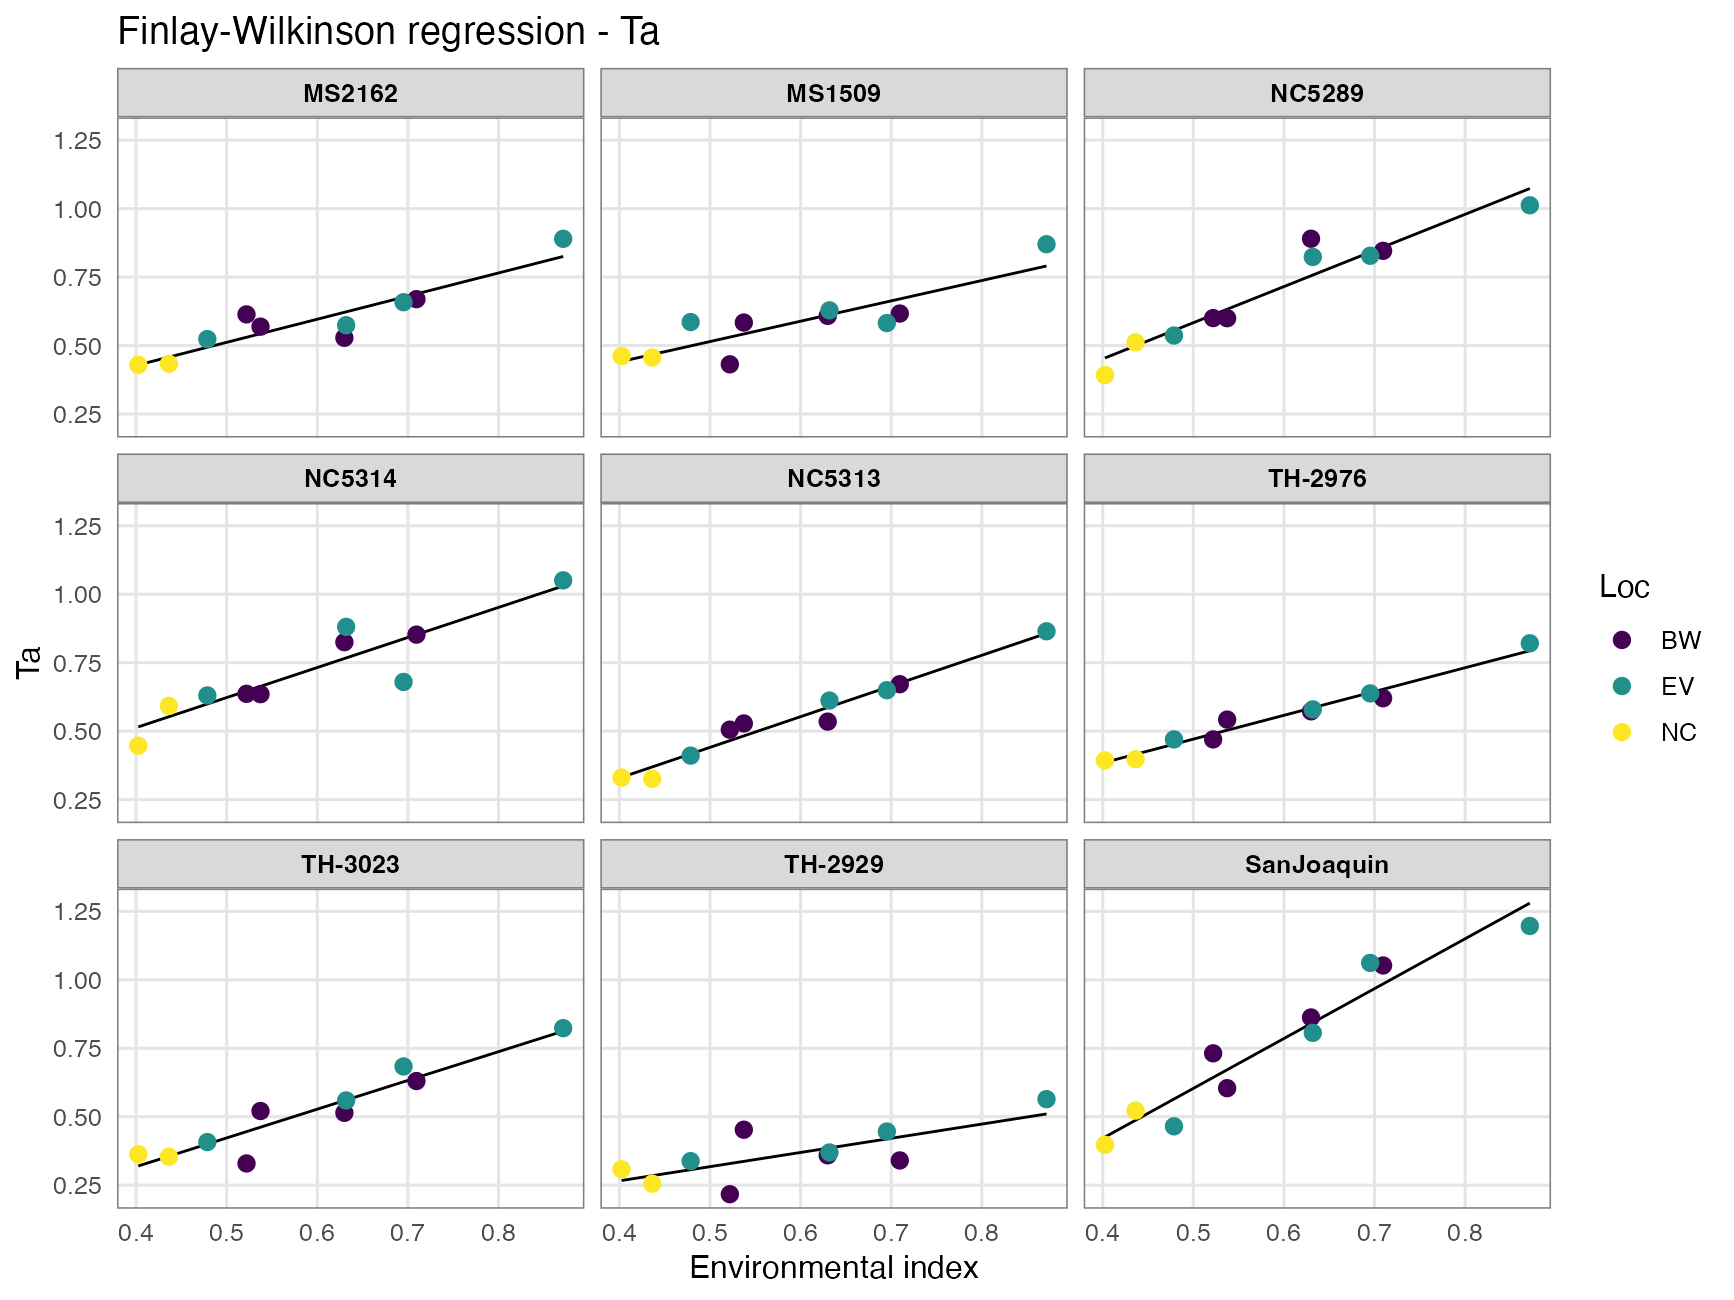

In [93]:
env_stats <- prep_and_scale_dta(prep_qual_ta) %>% distinct(Env, mean_env, sd_env)
bl <- reconstruct_adjusted_means(blup_fa2_asr_qual_ta, env_stats)
td   <- prepare_td(bl, use_col = 'trait')
fw   <- run_fw(td)

plot_fw_trellis(
  fw$fit,
  genotypes = c("MS2162", 'MS1509', "NC5289", "NC5314", 'NC5313', "TH-2976", "TH-3023", "TH-2929", "TH-2937", "SanJoaquin"),
  trait_label = "Ta",
  color_by = "loc"
)

Warning message:
In anova.lm(modelA) :
  ANOVA F-tests on an essentially perfect fit are unreliable


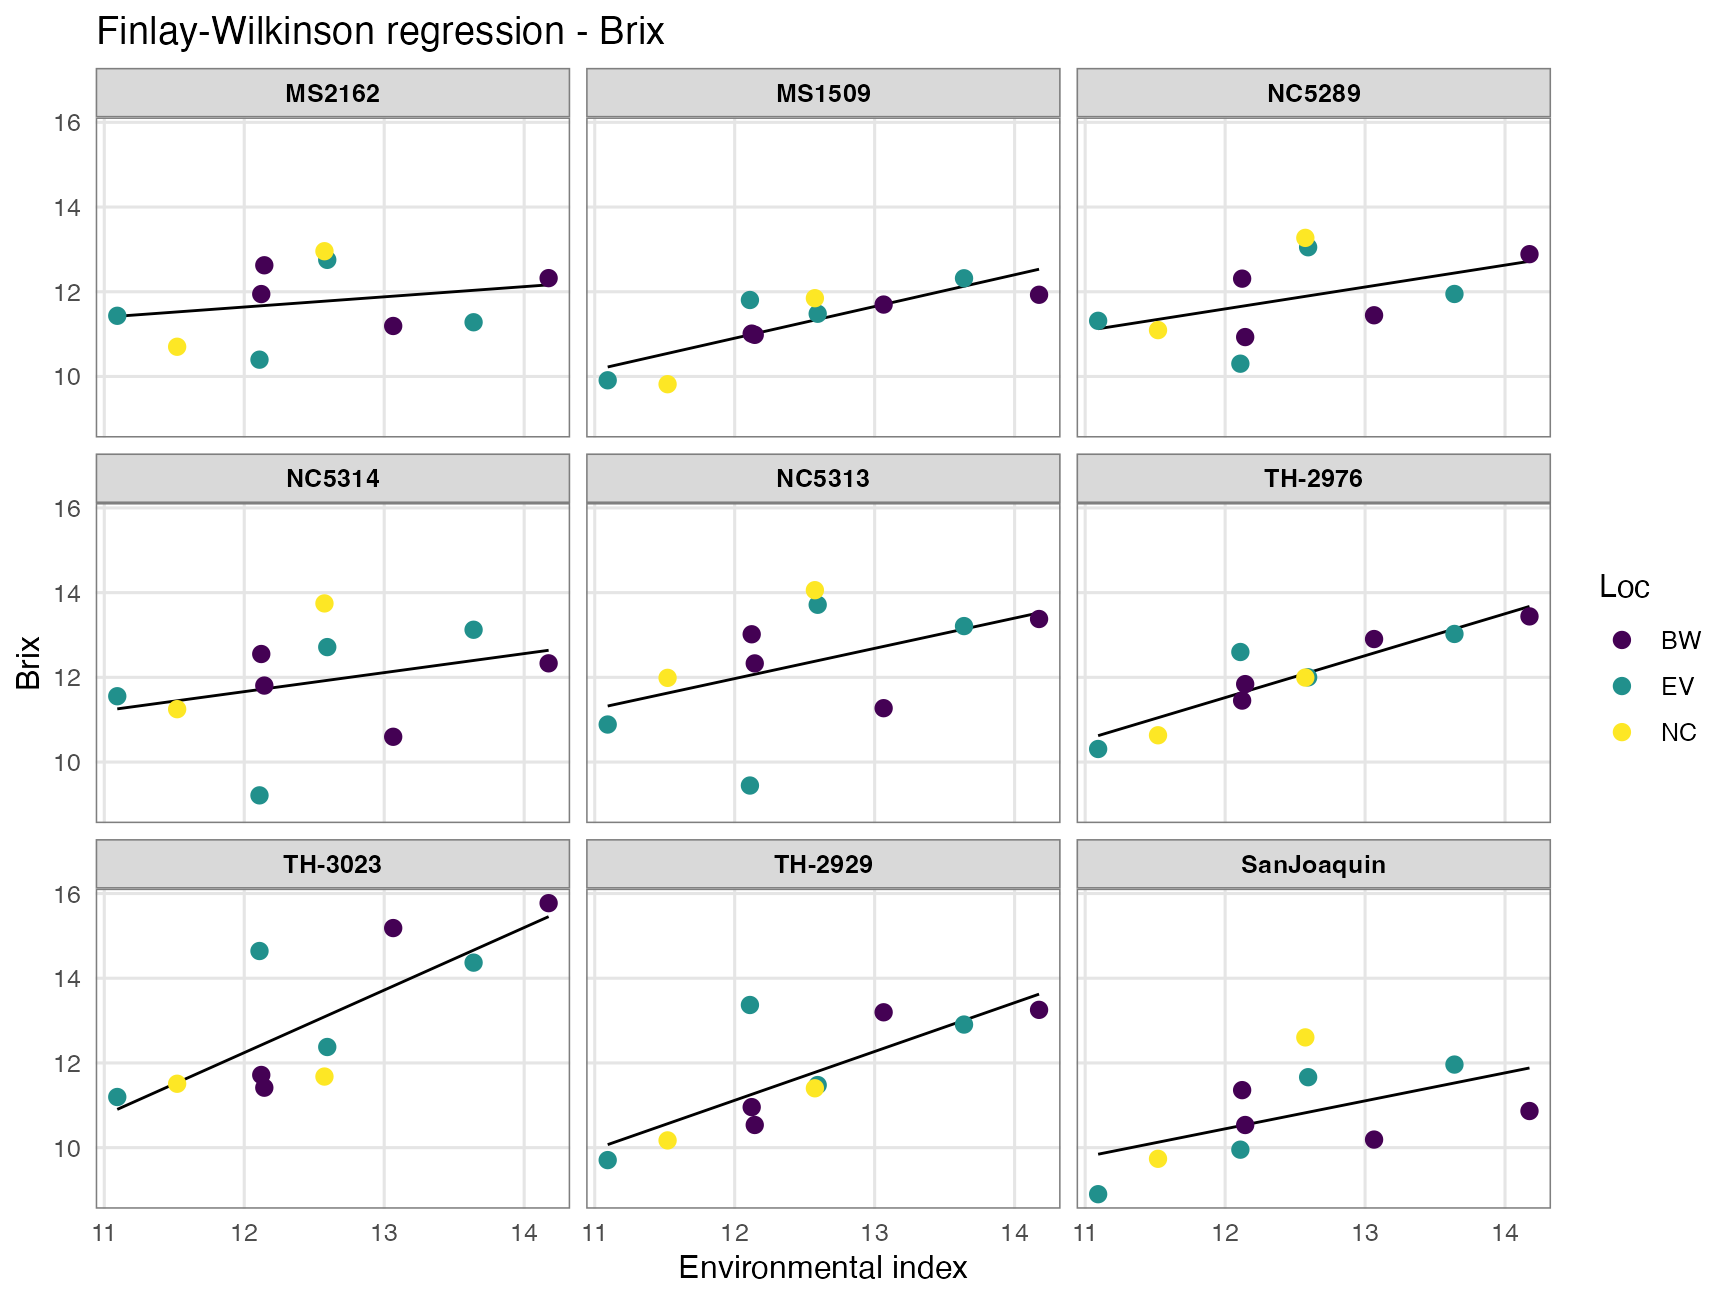

In [91]:
env_stats <- prep_and_scale_dta(prep_qual_brix) %>% distinct(Env, mean_env, sd_env)
bl <- reconstruct_adjusted_means(blup_fa2_asr_qual_brix, env_stats)
td   <- prepare_td(bl, use_col = 'trait')
fw   <- run_fw(td)

plot_fw_trellis(
  fw$fit,
  genotypes = c("MS2162", 'MS1509', "NC5289", "NC5314", 'NC5313', "TH-2976", "TH-3023", "TH-2929", "TH-2937", "SanJoaquin"),
  trait_label = "Brix",
  color_by = "loc"
)

Warning message:
In anova.lm(modelA) :
  ANOVA F-tests on an essentially perfect fit are unreliable


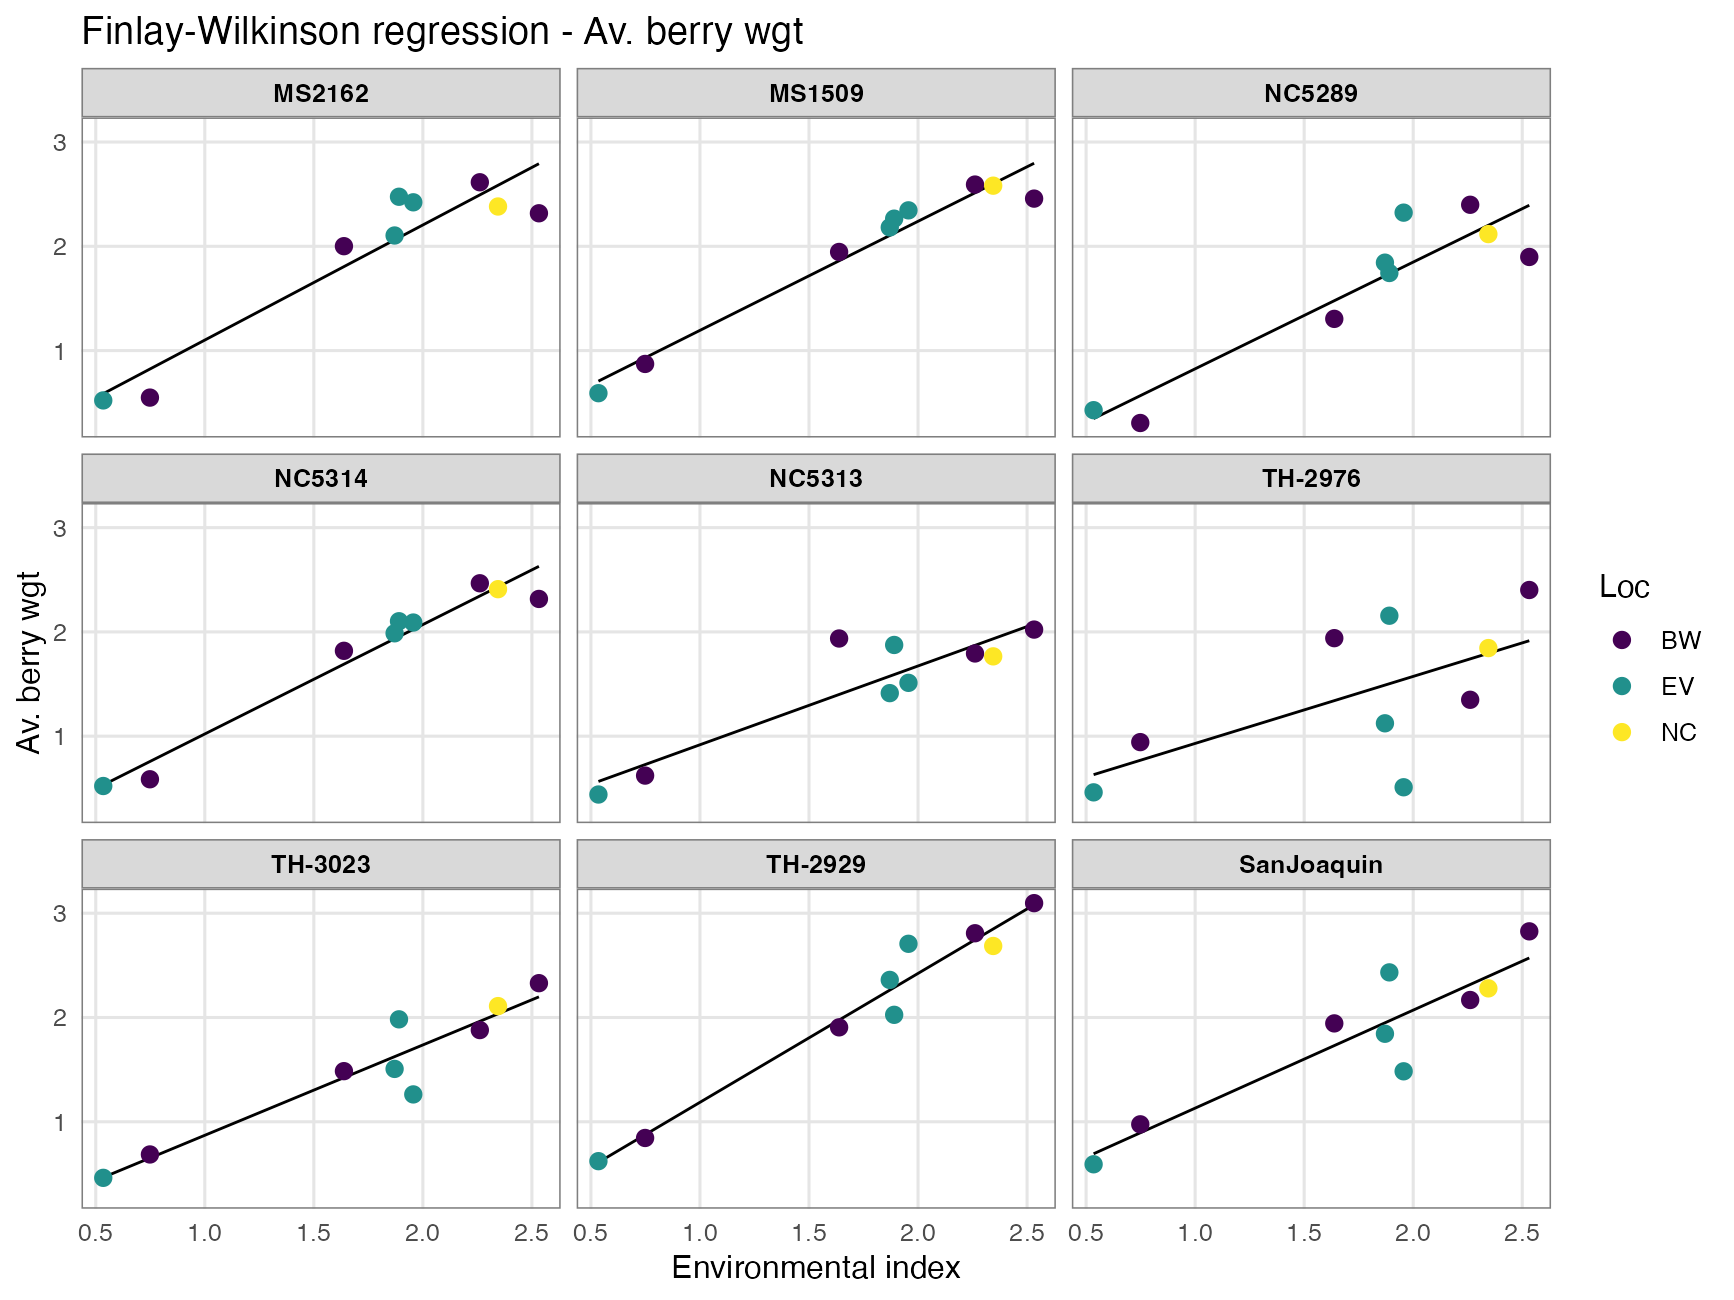

In [89]:
env_stats <- prep_and_scale_dta(prep_qual_avg_berry_weight) %>% distinct(Env, mean_env, sd_env)
bl <- reconstruct_adjusted_means(blup_fa2_asr_qual_avg_berry_weight, env_stats)
td   <- prepare_td(bl, use_col = 'trait')
fw   <- run_fw(td)

plot_fw_trellis(
  fw$fit,
  genotypes = c("MS2162", 'MS1509', "NC5289", "NC5314", 'NC5313', "TH-2976", "TH-3023", "TH-2929", "TH-2937", "SanJoaquin"),
  trait_label = "Av. berry wgt",
  color_by = "loc"
)

Warning message:
In anova.lm(modelA) :
  ANOVA F-tests on an essentially perfect fit are unreliable


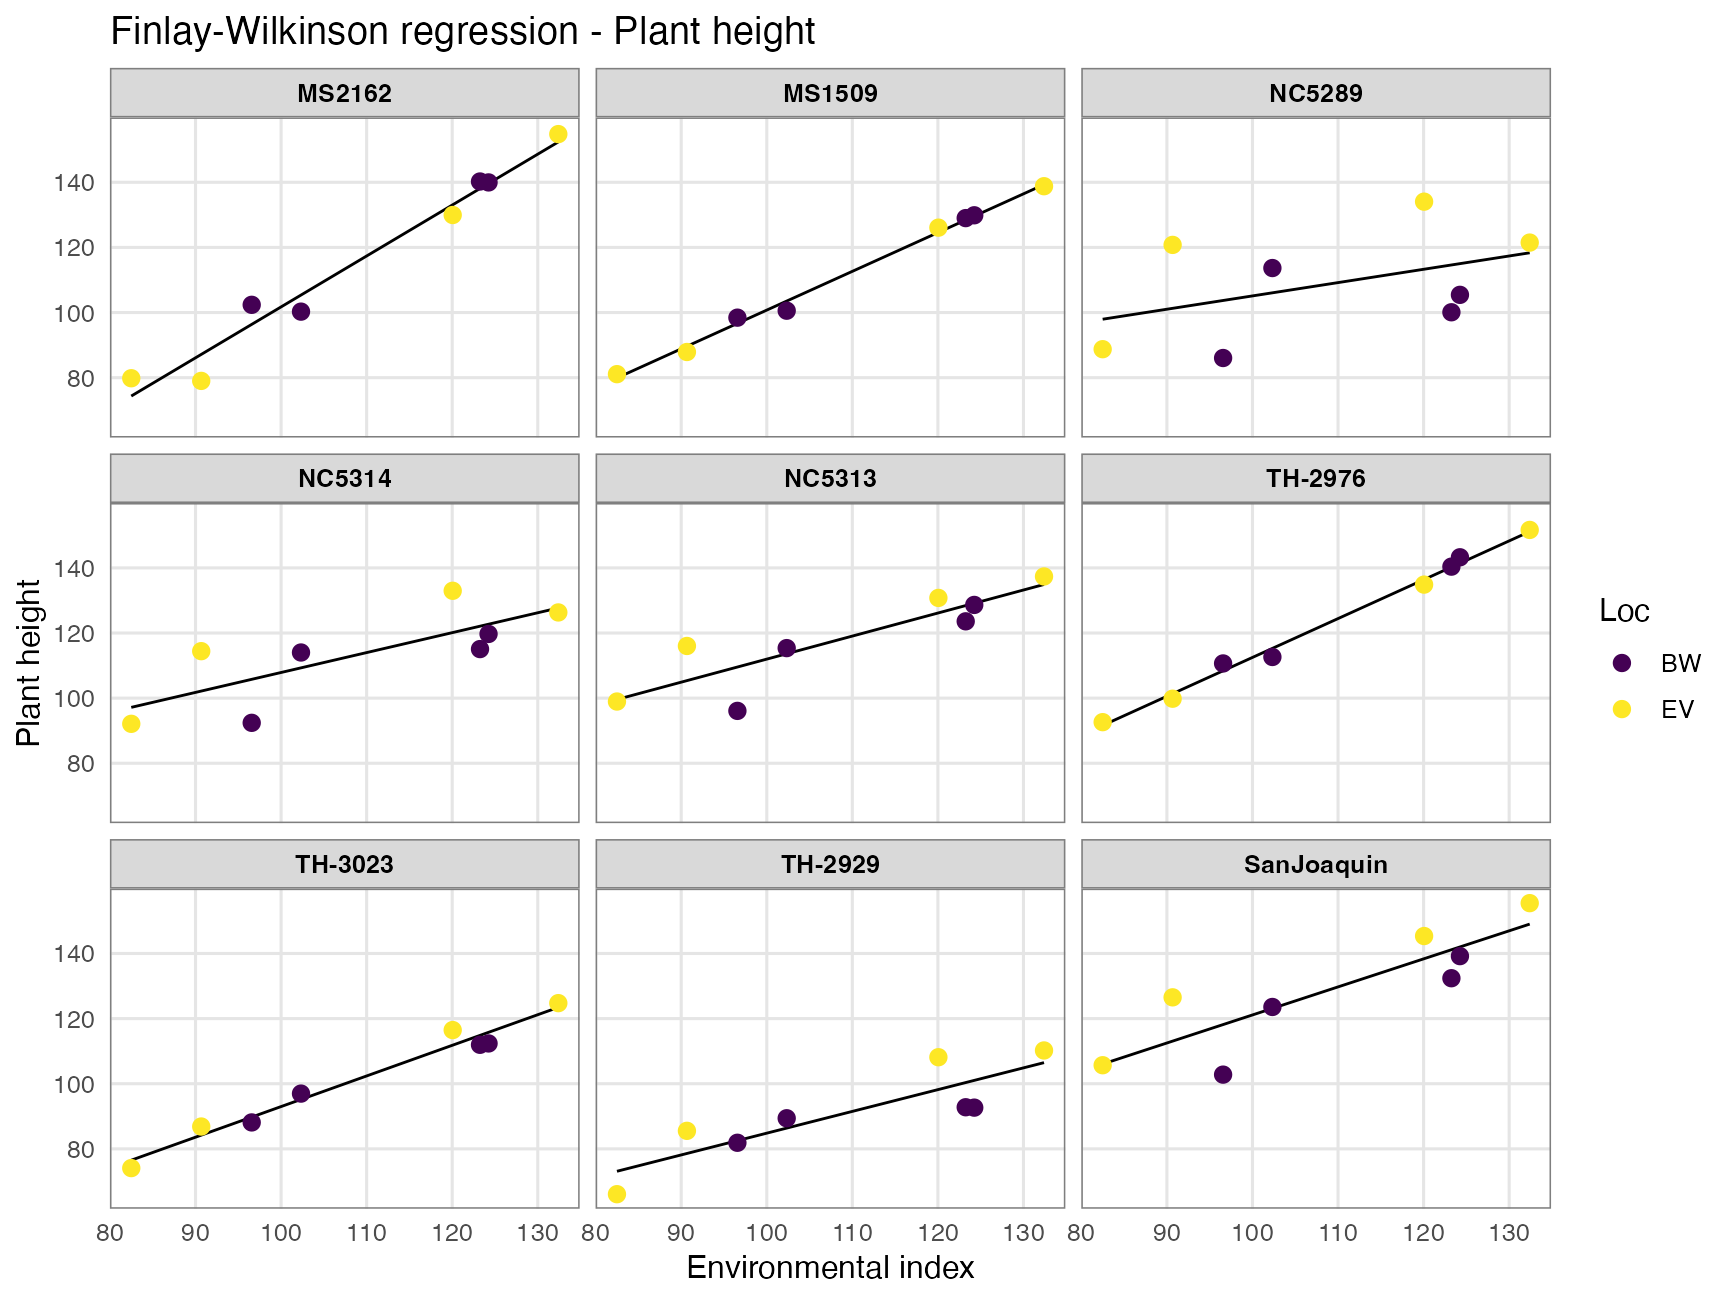

In [86]:
env_stats <- prep_and_scale_dta(prep_ph) %>% distinct(Env, mean_env, sd_env)
bl <- reconstruct_adjusted_means(blup_fa2_asr_ph, env_stats)
td   <- prepare_td(bl, use_col = 'trait')
fw   <- run_fw(td)

plot_fw_trellis(
  fw$fit,
  genotypes = c("MS2162", 'MS1509', "NC5289", "NC5314", 'NC5313', "TH-2976", "TH-3023", "TH-2929", "TH-2937", "SanJoaquin"),
  trait_label = "Plant height",
  color_by = "loc"
)

In [77]:
env_stats <- prep_and_scale_dta(prep_bloom_bloom5) %>% distinct(Env, mean_env, sd_env)
bl <- reconstruct_adjusted_means(blup_fa2_asr_bloom_bloom5, env_stats)
# td   <- prepare_td(blup_fa2_asr_bloom_bloom5, use_col = 'blup')

Warning message:
In anova.lm(modelA) :
  ANOVA F-tests on an essentially perfect fit are unreliable


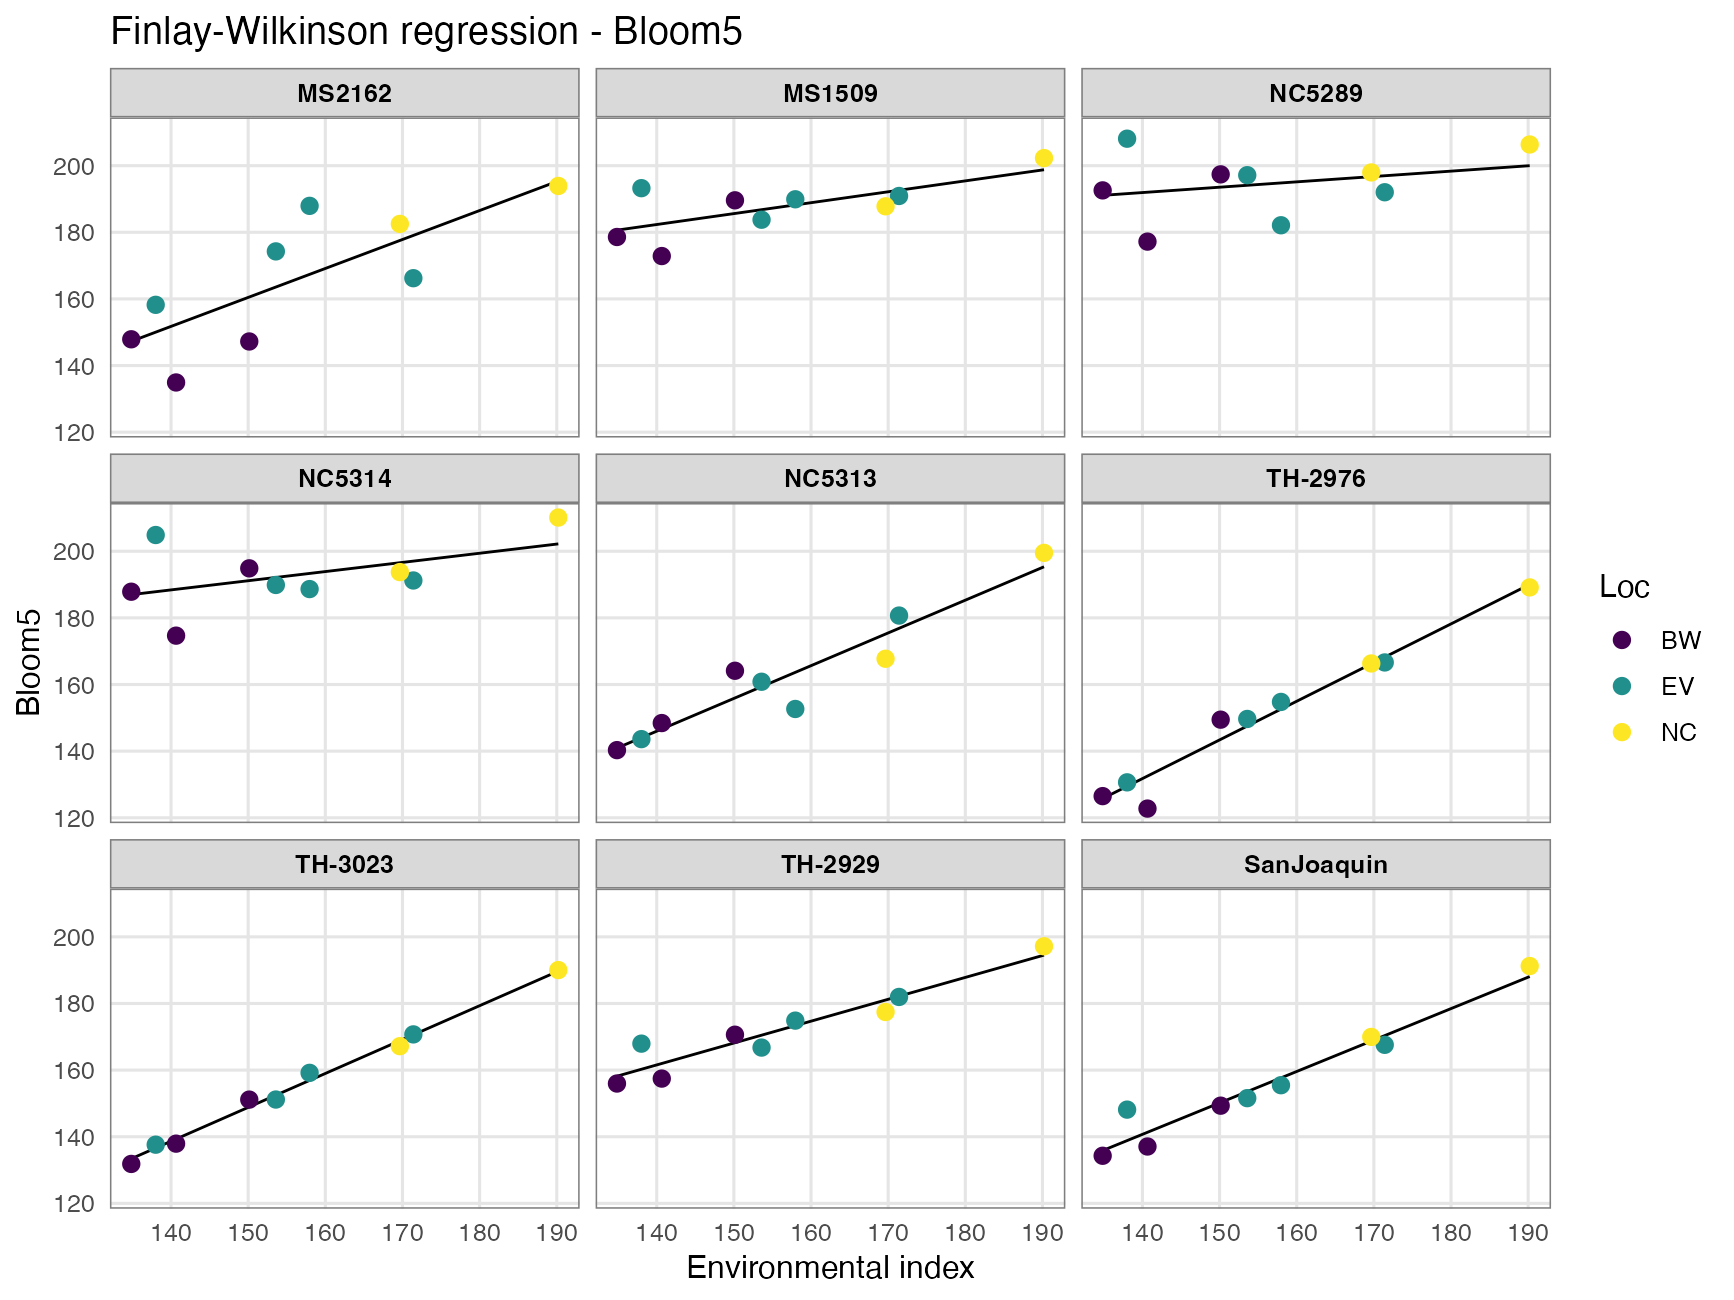

In [78]:
env_stats <- prep_and_scale_dta(prep_bloom_bloom5) %>% distinct(Env, mean_env, sd_env)
bl <- reconstruct_adjusted_means(blup_fa2_asr_bloom_bloom5, env_stats)
td   <- prepare_td(bl, use_col = 'trait')
fw   <- run_fw(td)

plot_fw_trellis(
  fw$fit,
  genotypes = c("MS2162", 'MS1509', "NC5289", "NC5314", 'NC5313', "TH-2976", "TH-3023", "TH-2929", "TH-2937", "SanJoaquin"),
  trait_label = "Bloom5",
  color_by = "loc"
)

Warning message:
In anova.lm(modelA) :
  ANOVA F-tests on an essentially perfect fit are unreliable


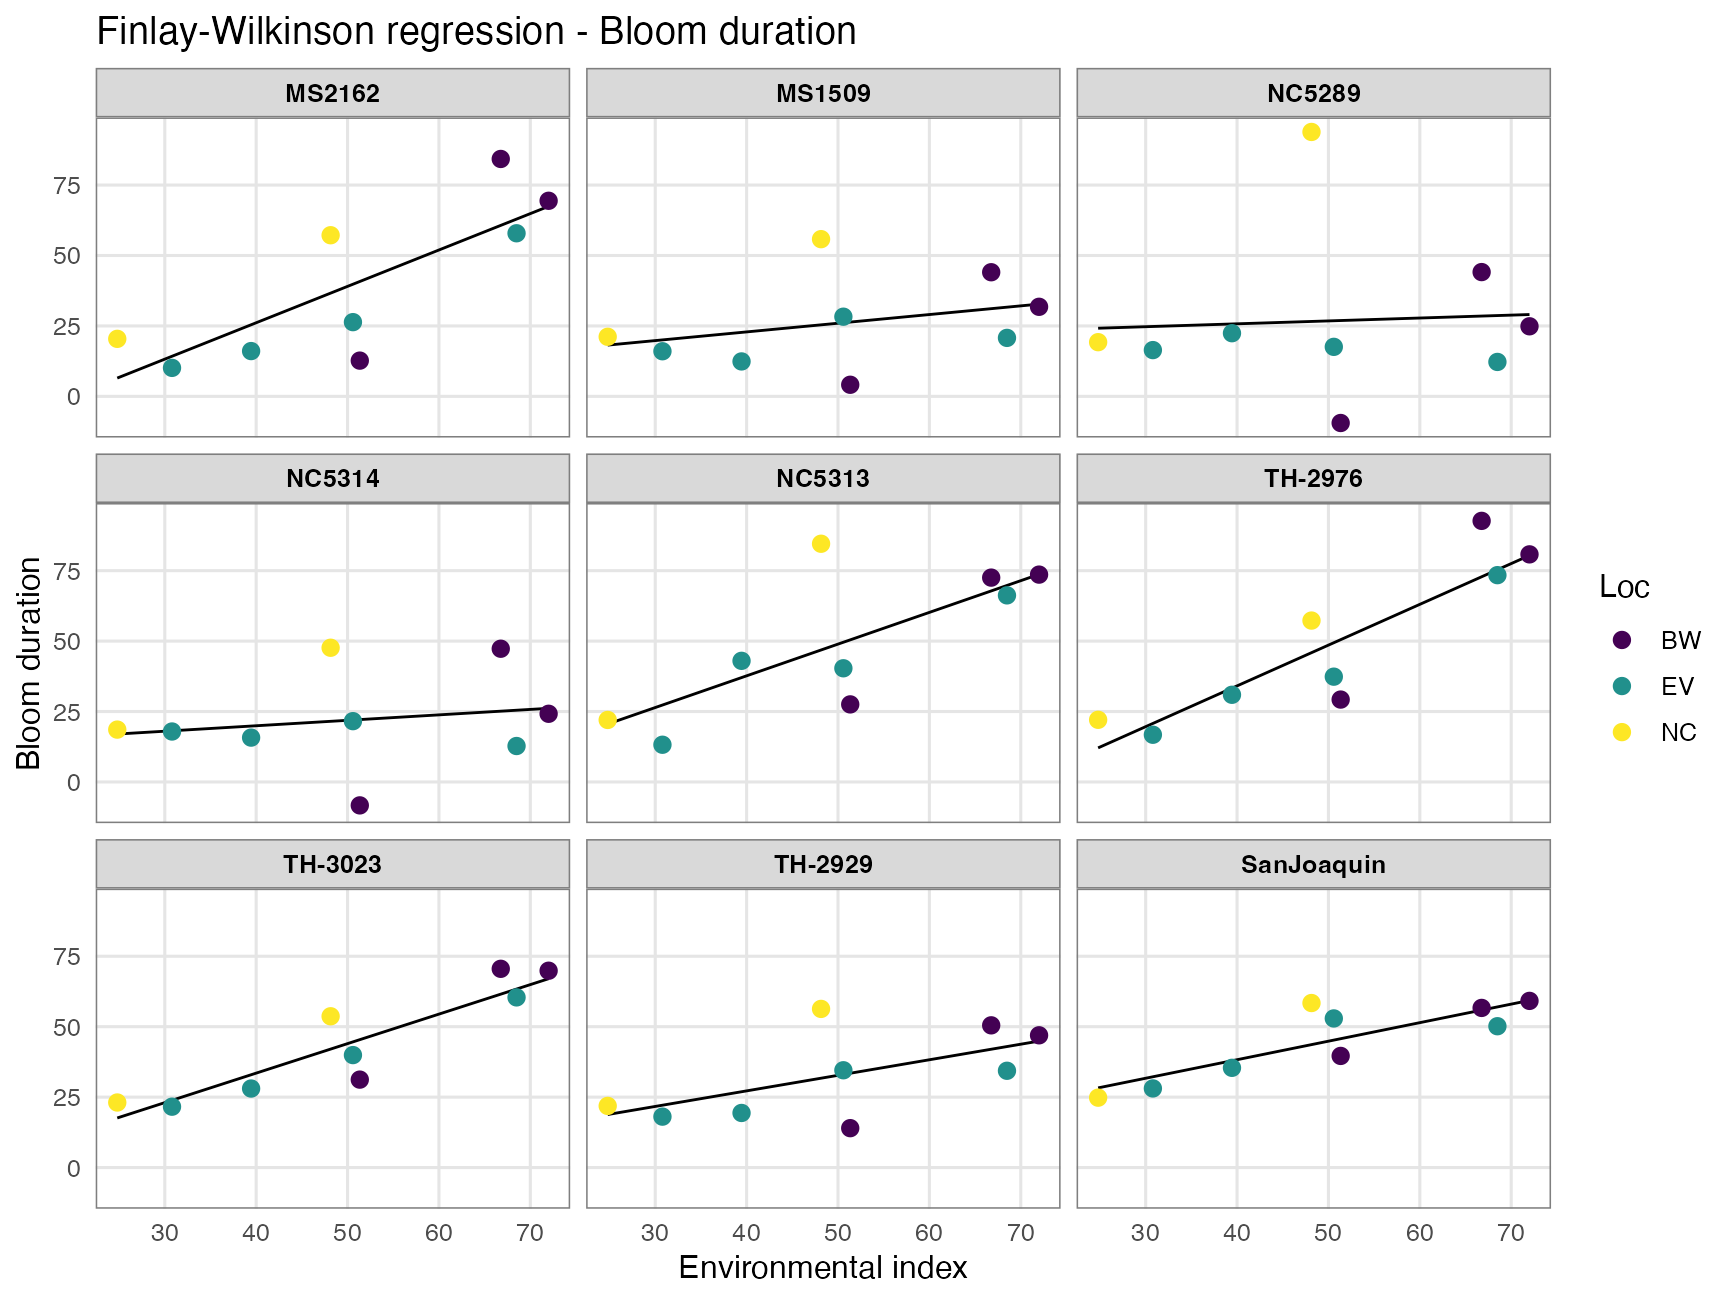

In [81]:
env_stats <- prep_and_scale_dta(prep_bloom_bloom_duration) %>% distinct(Env, mean_env, sd_env)
bl <- reconstruct_adjusted_means(blup_fa2_asr_bloom_bloom_duration, env_stats)
td   <- prepare_td(bl, use_col = 'trait')
fw   <- run_fw(td)

plot_fw_trellis(
  fw$fit,
  genotypes = c("MS2162", 'MS1509', "NC5289", "NC5314", 'NC5313', "TH-2976", "TH-3023", "TH-2929", "TH-2937", "SanJoaquin"),
  trait_label = "Bloom duration",
  color_by = "loc"
)

In [490]:
tar_load(blup_fa3_asr)

In [492]:
# bl <- reconstruct_adjusted_means(blup_fa3_total_ide_asr_grams)
td   <- prepare_td(blup_fa3_asr, use_col = 'blup')
fw   <- run_fw(td)

Warning message:
In anova.lm(modelA) :
  ANOVA F-tests on an essentially perfect fit are unreliable


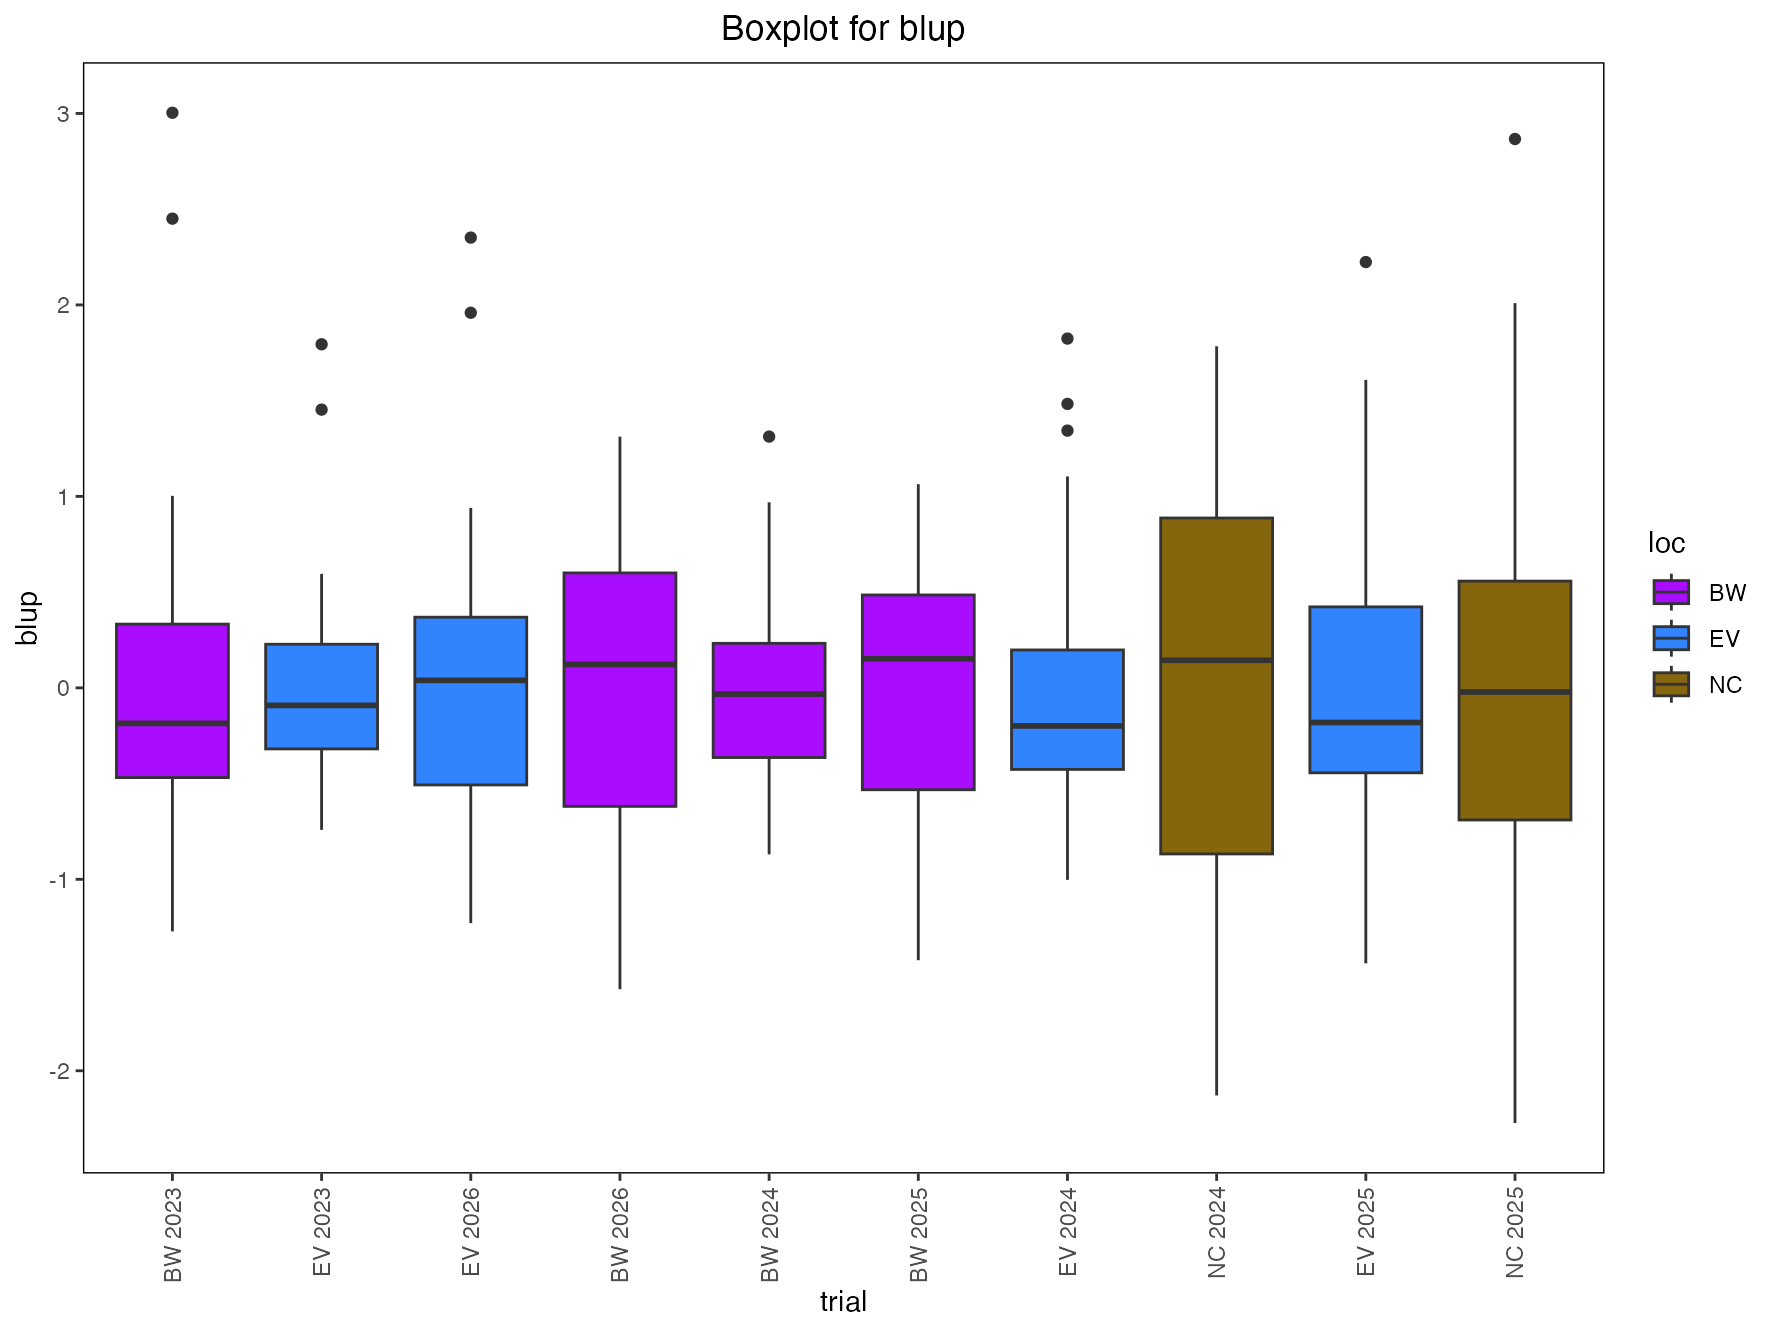

In [494]:
plot(td, plotType = "box", traits = "blup", colorTrialBy = "loc", orderBy = "ascending")

In [497]:
dropsFW <- gxeFw(TD = td, trait = "blup")

Warning message:
In anova.lm(modelA) :
  ANOVA F-tests on an essentially perfect fit are unreliable


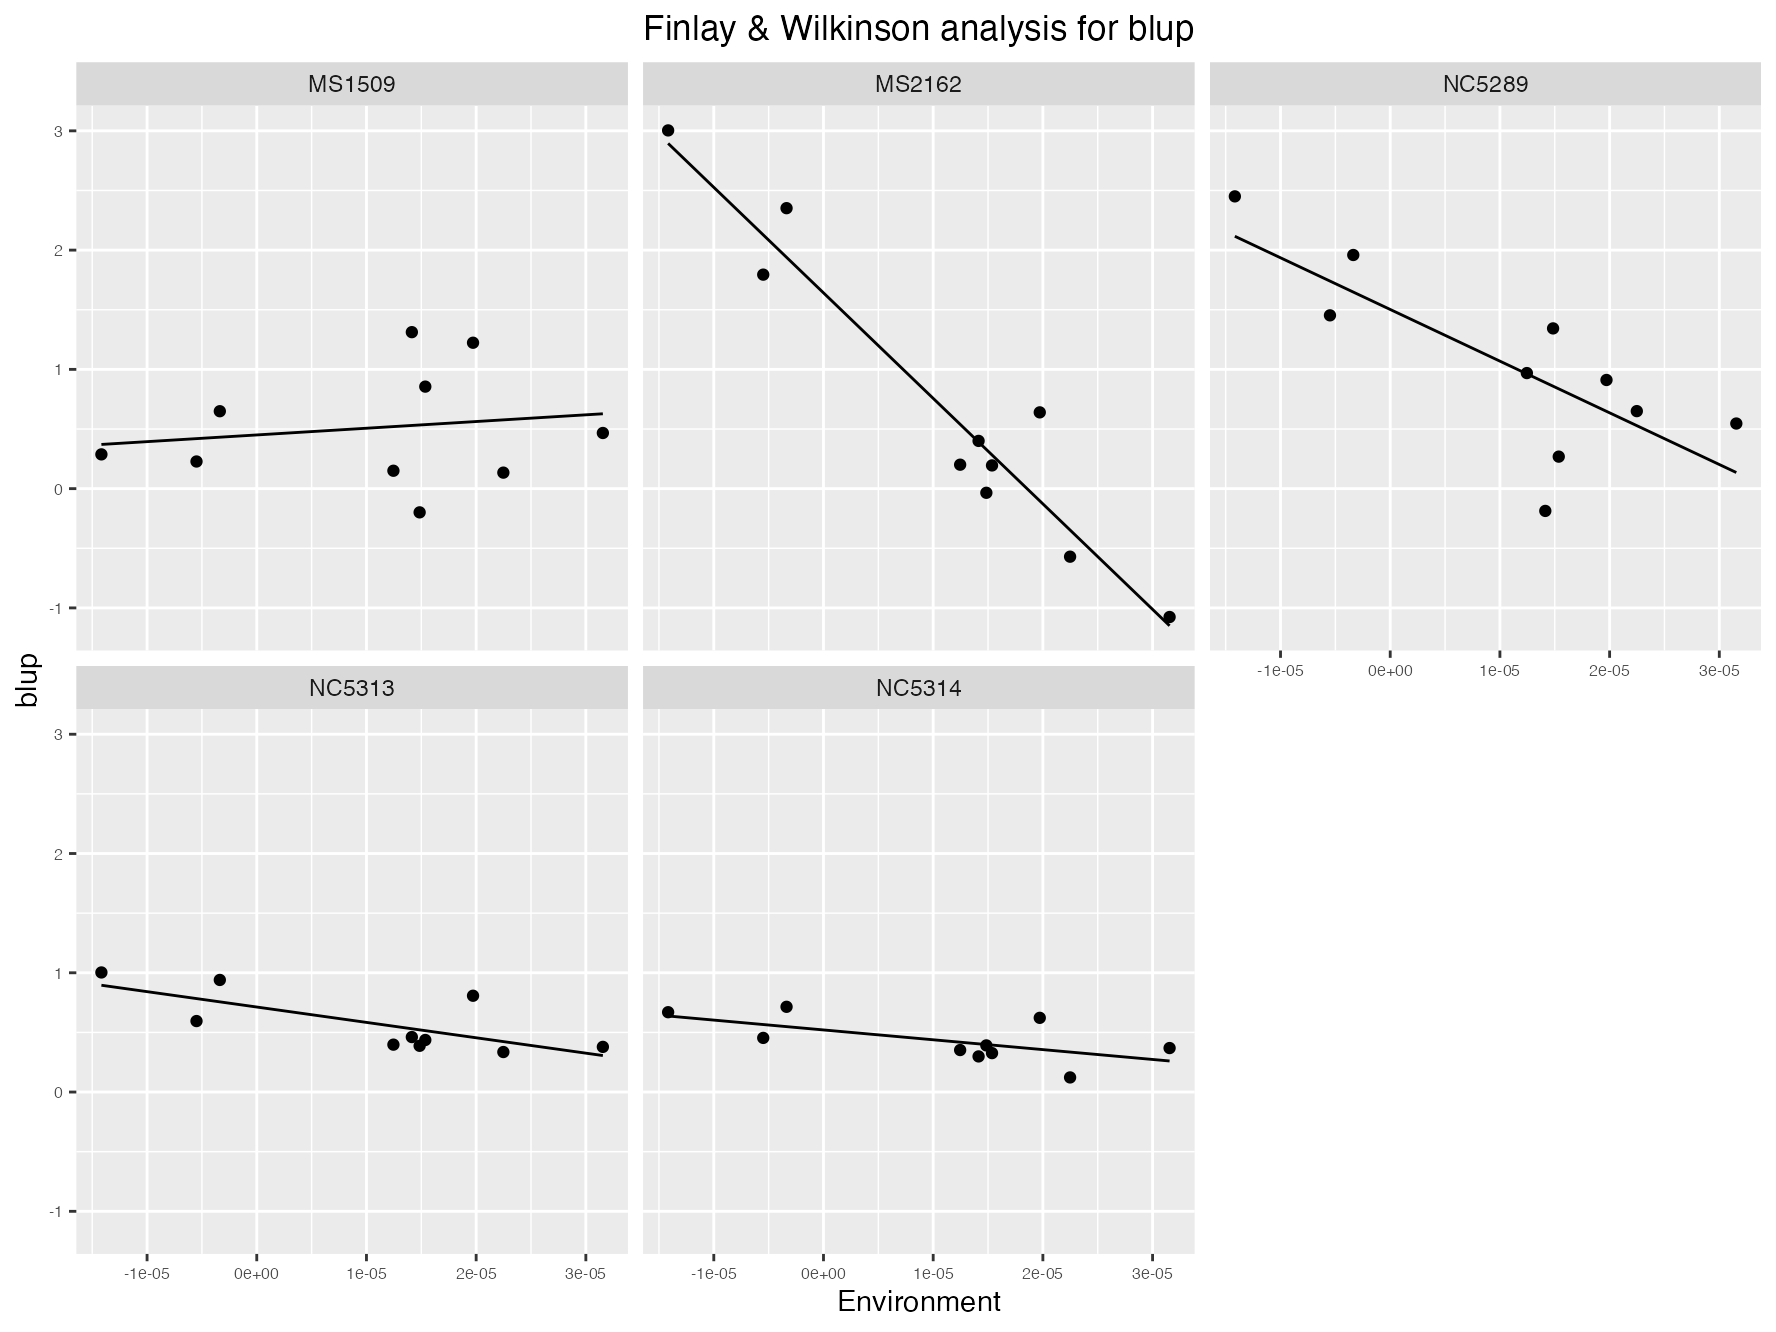

In [499]:
## Create trellis plot for Finlay Wilkinson analysis.
## Restrict to first 5 genotypes.
plot(dropsFW, plotType = "trellis", genotypes = c("MS2162", 'MS1509', "NC5289", "NC5314", 'NC5313'))

In [500]:
td_long <- purrr::map_dfr(fw$fit$TD, as.data.frame, .id = "trial_name")
env_idx <- fw$fit$envEffs %>% transmute(trial = as.character(Trial), EnvMean)
check <- td_long %>% left_join(env_idx, by = c("trial" = "trial")) %>%
  distinct(trial, EnvMean) 
check 

     trial       EnvMean
1  BW 2023 -1.416329e-05
2  BW 2024  1.245720e-05
3  BW 2025  1.536316e-05
4  BW 2026  1.413755e-05
5  EV 2023 -5.492938e-06
6  EV 2024  1.484690e-05
7  EV 2025  2.247965e-05
8  EV 2026 -3.367918e-06
9  NC 2024  1.971554e-05
10 NC 2025  3.155079e-05

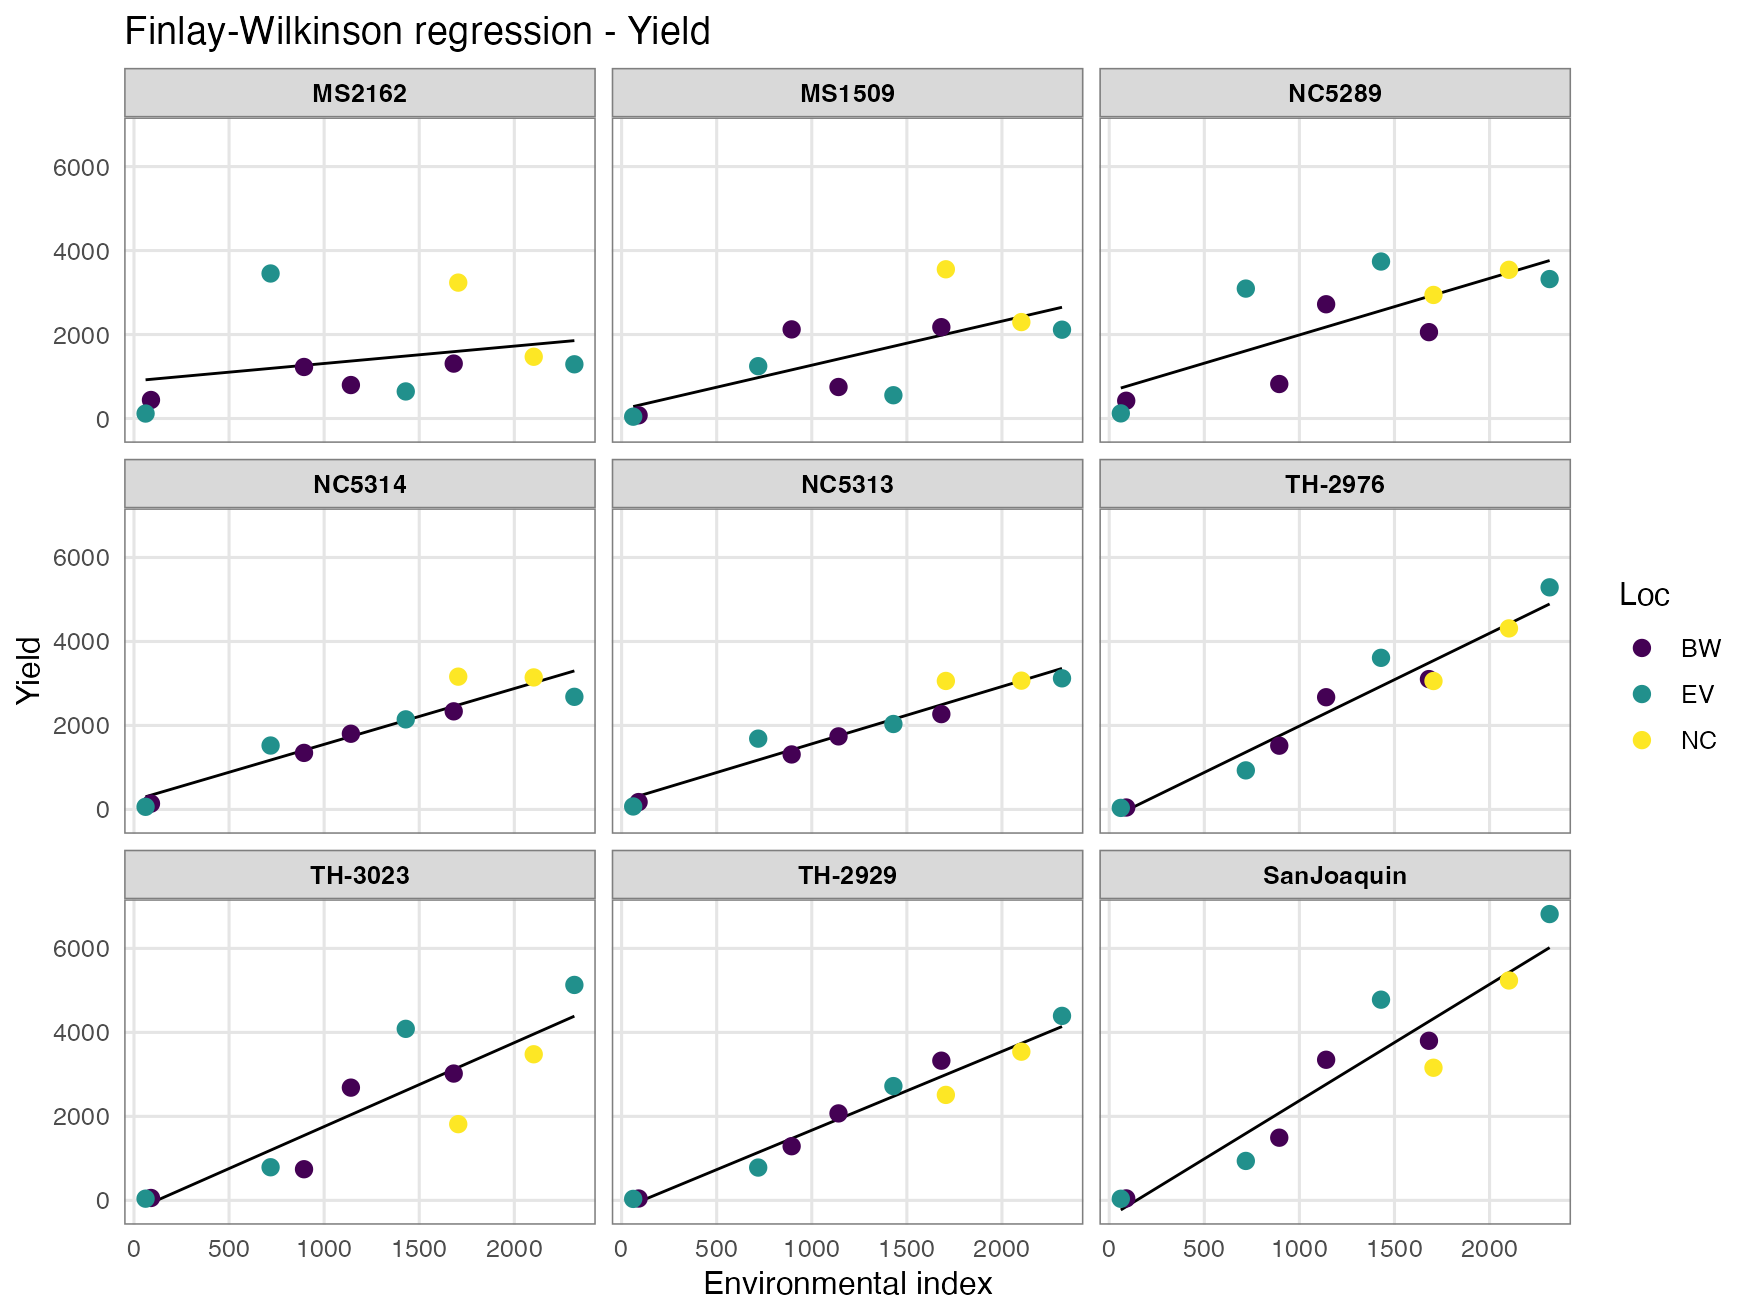

In [281]:
plot_fw_trellis(
  fw$fit,
  genotypes = c("MS2162", 'MS1509', "NC5289", "NC5314", 'NC5313', "TH-2976", "TH-3023", "TH-2929", "TH-2937", "SanJoaquin"),
  trait_label = "Yield",
  color_by = "loc"
)

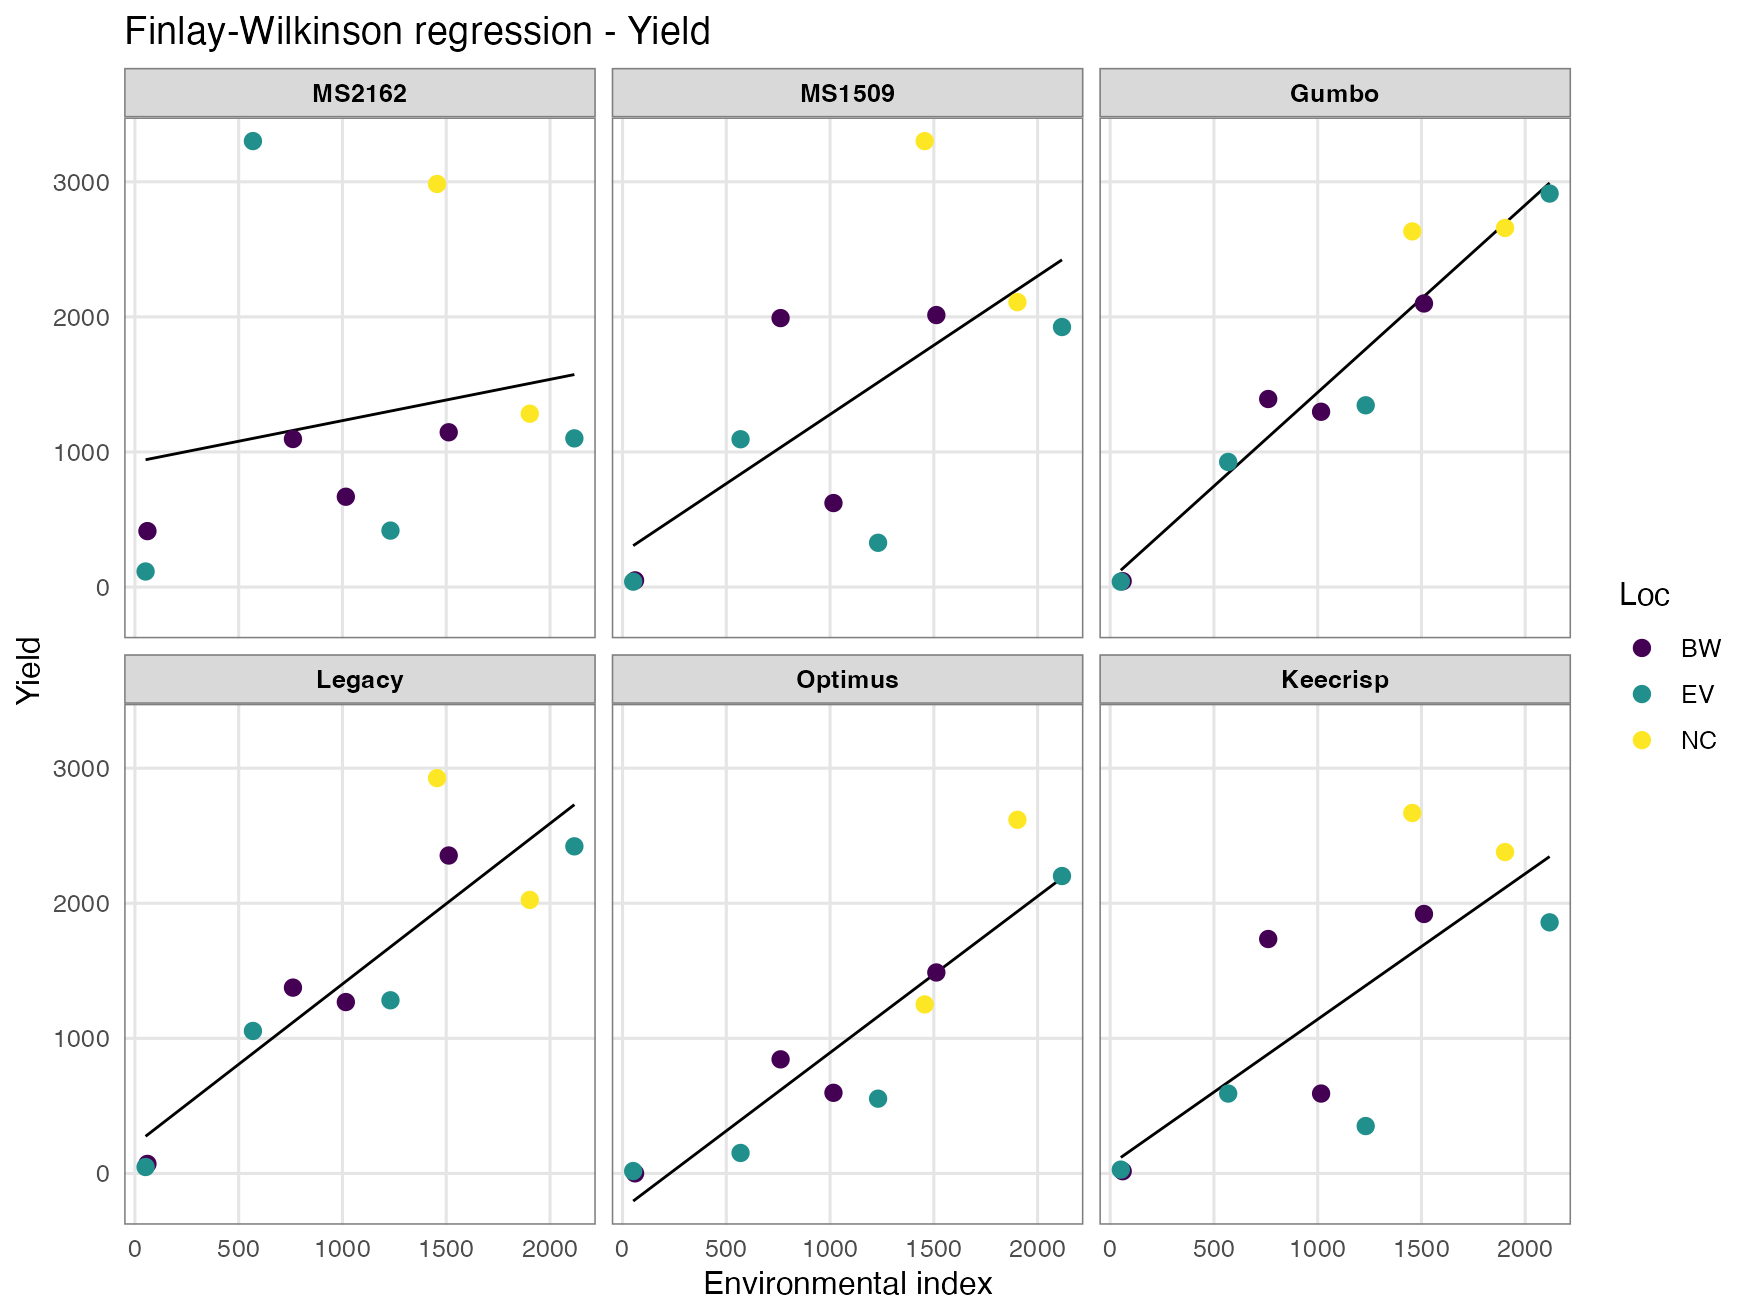

In [279]:
plot_fw_trellis(
  fw$fit,
  genotypes = c("MS2162", "MS1509", "Gumbo", 'Legacy', "Optimus", "Keecrisp"),
  trait_label = "Yield",
  color_by = "loc"
)

Rows: 10
Columns: 11
$ location                              <chr> "EV", "EV", "EV", "EV", "BW", "BW", "BW", "BW", "NC", "NC"
$ season                                <int> 2023, 2024, 2025, 2026, 2023, 2024, 2025, 2026, 2024, 2025
$ Chill_Portions_sum                    <dbl> 46.09304, 74.13447, 54.98871, 53.56137, 38.60503, 51.35283, 44.57487, 45.69871,…
$ GDH_sum                               <dbl> 11197.875, 7783.898, 6900.132, 8039.409, 13966.288, 9600.651, 9366.392, 11006.0…
$ n_frost_hours_available               <int> 5088, 5088, 5088, 5088, 5088, 5088, 5088, 5088, 5088, 5088
$ frost_late_window                     <lgl> TRUE, FALSE, FALSE, TRUE, TRUE, FALSE, FALSE, FALSE, FALSE, FALSE
$ frost_late_window_min_temp            <dbl> -3.3333333, -1.0555556, -1.2777778, -2.8888889, -2.5555556, -0.1666667, -0.6111…
$ frost_score                           <dbl> 0.5, 0.0, 0.0, 0.5, 0.5, 0.0, 0.0, 0.0, 0.0, 0.0
$ imputed_hours_in_chill_window         <int> 0, 51, 163, 96, 31, 13, 0, 0, 

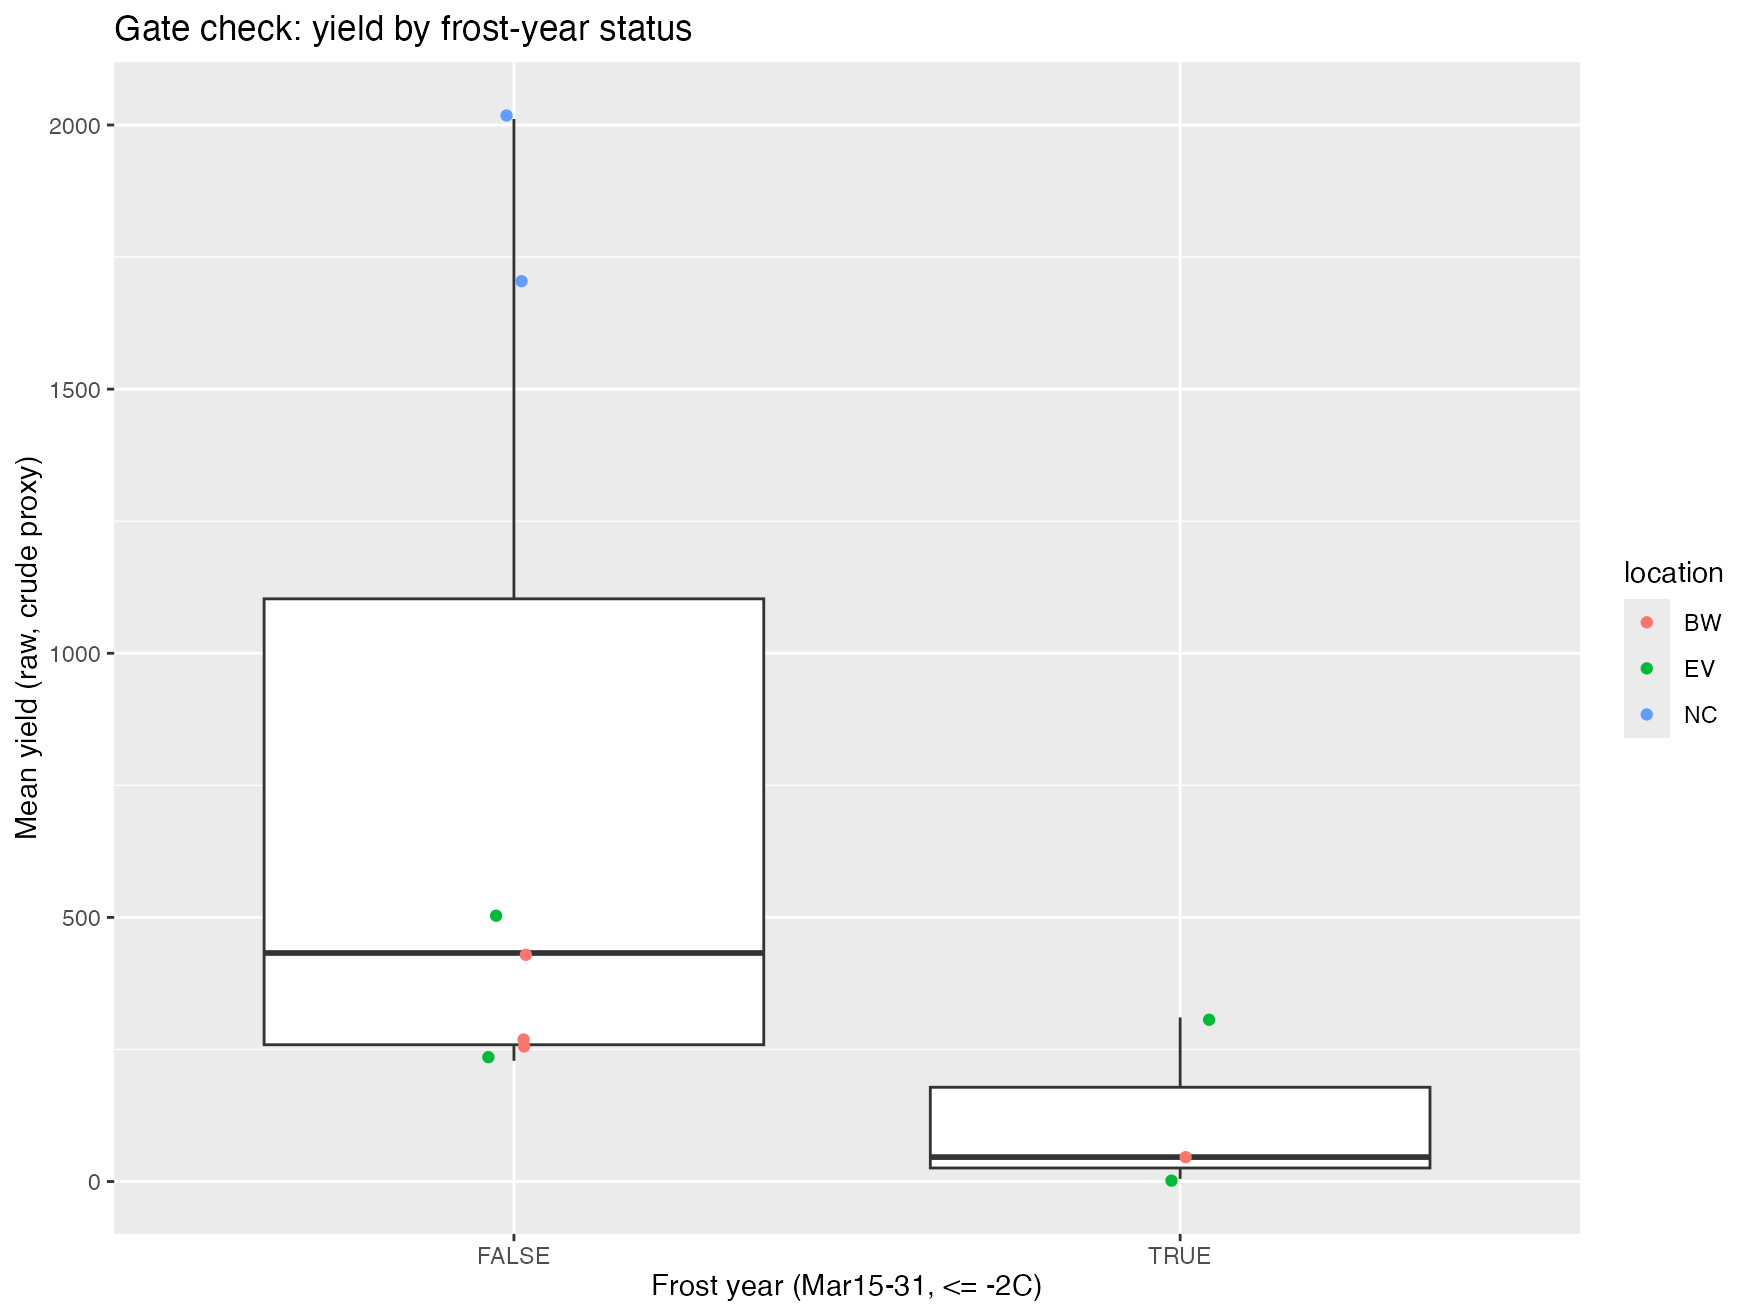

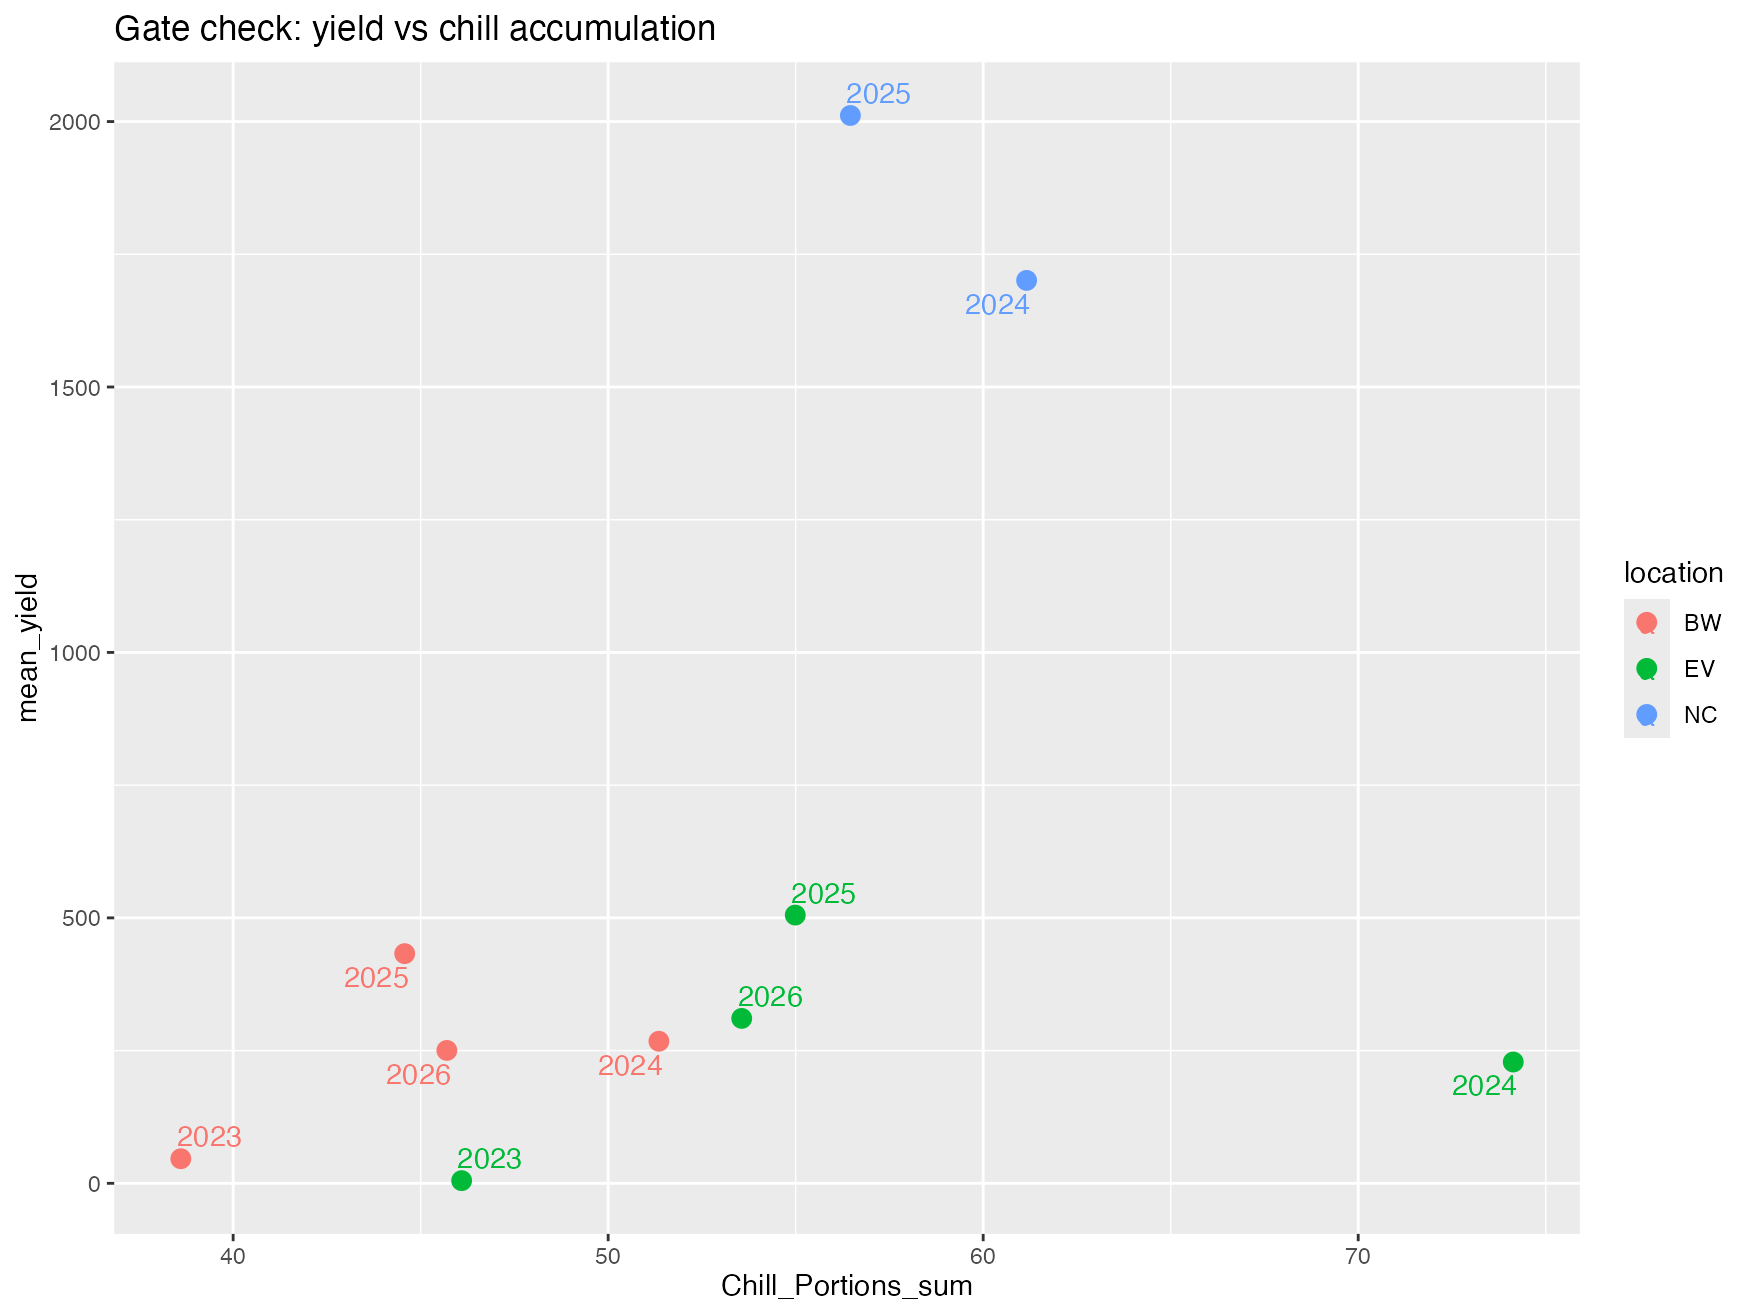

In [257]:
# gate_check_yield_vs_weather.R
# Cheap, crude check: does environment-level yield correlate at all with
# the Stage 6 chill/heat/frost covariates, before committing to a real
# yield reaction-norm build. NOT a substitute for Model 1 BLUEs -- see
# DESIGN.md Stage 9 / §9 for the caveat.

library(targets)
library(dplyr)
library(ggplot2)

# --- 1. Load what already exists in the pipeline store -----------------
tar_load(env_clustering_covariates)   # location, season, Chill_Portions_sum, GDH_sum, frost_score, ...

# Adjust these three tar_load() calls / column names if your real target
# names or schemas differ -- check with glimpse() before trusting the join.
tar_load(al_yield_long_clean)
tar_load(nc_yield_clean)
nc_yield_clean = nc_yield_clean %>% rename(yield = y)
# tar_load(fl_yield_clean)

glimpse(env_clustering_covariates)
glimpse(al_yield_long_clean)

# --- 2. Build one row per (location, season) with a crude mean yield ---
# EDIT the `location`/`season`/`yield` column names below to match your
# real cleaned tables if they differ (e.g. Location/Season/TotalYield).
harmonize_yield <- function(df, loc_col, season_col, yield_col, location_label = NULL) {
  out <- df %>%
    transmute(
      location = if (!is.null(location_label)) location_label else as.character(.data[[loc_col]]),
      season   = as.integer(.data[[season_col]]),
      yield    = as.numeric(.data[[yield_col]])
    ) %>%
    filter(!is.na(.data$yield))
  out
}

al_y <- harmonize_yield(al_yield_long_clean, "location", "season", "yield")
nc_y <- harmonize_yield(nc_yield_clean,      "location", "season", "yield", location_label = "NC")
# fl_y <- harmonize_yield(fl_yield_clean,      "Location", "Season", "Yield", location_label = "FL")

env_mean_yield <- bind_rows(al_y, nc_y) %>%
  group_by(location, season) %>%
  summarise(
    mean_yield = mean(yield, na.rm = TRUE),
    n_obs      = n(),
    .groups = "drop"
  )

# --- 3. Join to the weather covariates ----------------------------------
gate_data <- env_mean_yield %>%
  inner_join(env_clustering_covariates, by = c("location", "season")) %>%
  arrange(location, season)

print(gate_data, n = Inf)

# --- 4. Correlations (descriptive -- N is ~10 environments, don't read
# a p-value here as confirmatory) ----------------------------------------
cor_report <- tibble(
  covariate = c("frost_score", "Chill_Portions_sum", "GDH_sum"),
  pearson_r = c(
    cor(gate_data$mean_yield, gate_data$frost_score, use = "complete.obs"),
    cor(gate_data$mean_yield, gate_data$Chill_Portions_sum, use = "complete.obs"),
    cor(gate_data$mean_yield, gate_data$GDH_sum, use = "complete.obs")
  )
)
print(cor_report)

# --- 5. The more honest version of the frost question: frost-year vs
# non-frost-year mean yield, same envs --------------------------------
frost_group_summary <- gate_data %>%
  mutate(frost_year = frost_score > 0) %>%
  group_by(frost_year) %>%
  summarise(
    n_envs = n(),
    mean_yield = mean(mean_yield),
    sd_yield   = sd(mean_yield),
    .groups = "drop"
  )
print(frost_group_summary)

# --- 6. Quick visual ----------------------------------------------------
p1 <- ggplot(gate_data, aes(x = frost_score > 0, y = mean_yield)) +
  geom_boxplot() +
  geom_jitter(width = 0.05, aes(color = location)) +
  labs(x = "Frost year (Mar15-31, <= -2C)", y = "Mean yield (raw, crude proxy)",
       title = "Gate check: yield by frost-year status")

p2 <- ggplot(gate_data, aes(x = Chill_Portions_sum, y = mean_yield, color = location, label = season)) +
  geom_point(size = 3) +
  ggrepel::geom_text_repel() +
  labs(title = "Gate check: yield vs chill accumulation")

print(p1)
print(p2)

N environments with chill data: 10 
Range: 38.6 - 74.1 
# A tibble: 10 × 3
   location season Chill_Portions_sum
   <chr>     <int>              <dbl>
 1 BW         2023               38.6
 2 BW         2025               44.6
 3 BW         2026               45.7
 4 EV         2023               46.1
 5 BW         2024               51.4
 6 EV         2026               53.6
 7 EV         2025               55.0
 8 NC         2025               56.5
 9 NC         2024               61.2
10 EV         2024               74.1

Candidate thresholds (of 200 scanned) with >= 3 environments on each side: 61 
Viable threshold window: 45.7 - 56.5 

--- VERDICT ---
MARGINAL PASS: a density-adequate threshold window exists, but with
 only 10 environments total, treat any fitted threshold's
 confidence interval with real caution -- fit it, but inspect the CI
 width before trusting the breakpoint estimate.


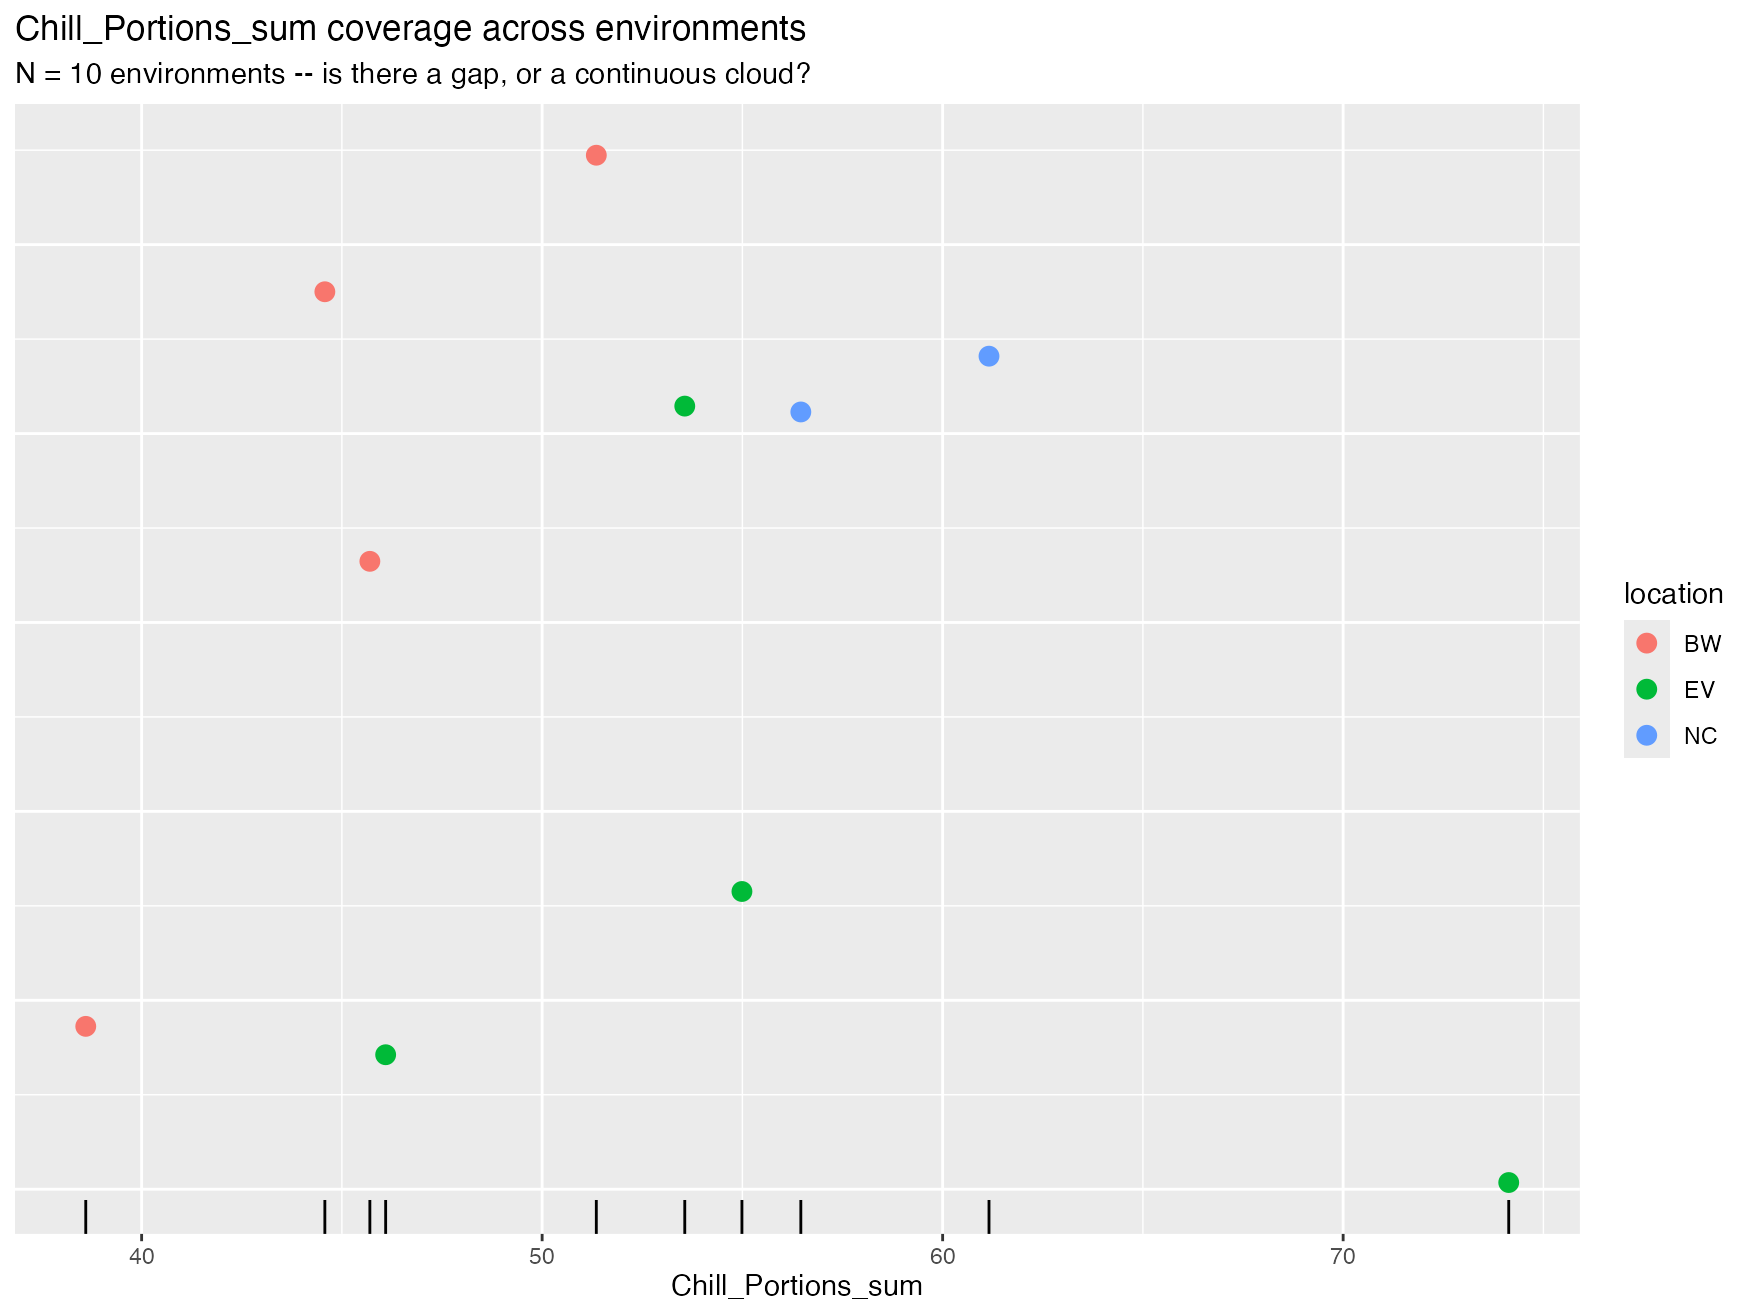

In [260]:
# chill_density_gate_check.R
#
# Gate check (DESIGN.md §6.2/Stage 6): before fitting a genotype-level
# bilinear/hinge reaction norm (bloom thermal-time ~ chill accumulation),
# check whether our environments' Chill_Portions_sum values actually span
# a plausible dormancy-release threshold with reasonable density on BOTH
# sides -- a segmented/changepoint regression can't identify a threshold
# reliably if the data barely straddles it, or does so with only a
# couple of points per side. This is exactly the failure mode Drouault
# et al. (2025) documented on their own sparser dataset ("bogus
# estimates" from a bilinear fit with inadequate covariate density).
#
# This does NOT require Stage 4's bloom thermal-time data yet -- it's a
# precondition check on the COVARIATE alone, independent of the response.
# If this fails, there's no point building the response side of the model.

library(targets)
library(dplyr)
library(ggplot2)

tar_load(env_clustering_covariates)   # location, season, Chill_Portions_sum, GDH_sum, frost_score, ...

chill_vals <- env_clustering_covariates %>%
  filter(!is.na(Chill_Portions_sum)) %>%
  arrange(Chill_Portions_sum)

cat("N environments with chill data:", nrow(chill_vals), "\n")
cat("Range:", round(min(chill_vals$Chill_Portions_sum), 1), "-",
    round(max(chill_vals$Chill_Portions_sum), 1), "\n")
print(chill_vals %>% dplyr::select(location, season, Chill_Portions_sum) %>% arrange(Chill_Portions_sum))

# --- Scan candidate breakpoints across the observed range -------------
# For each candidate threshold, count environments strictly below and
# strictly above it. A changepoint model needs a reasonable minimum count
# on BOTH sides to identify both the flat and sloped segments -- too few
# on either side (or candidates sitting right at the data's edge) means
# the threshold itself can't be pinned down, which is exactly how
# Drouault et al. got "bogus estimates" on their sparser dataset.
min_density_required <- 3   # floor per side; adjust if you have a domain-informed minimum

grid <- seq(min(chill_vals$Chill_Portions_sum), max(chill_vals$Chill_Portions_sum), length.out = 200)

density_check <- tibble(
  candidate_threshold = grid,
  n_below = sapply(grid, function(t) sum(chill_vals$Chill_Portions_sum < t)),
  n_above = sapply(grid, function(t) sum(chill_vals$Chill_Portions_sum >= t))
) %>%
  mutate(both_sides_adequate = n_below >= min_density_required & n_above >= min_density_required)

n_viable_thresholds <- sum(density_check$both_sides_adequate)
cat("\nCandidate thresholds (of", nrow(density_check), "scanned) with >=",
    min_density_required, "environments on each side:", n_viable_thresholds, "\n")

if (n_viable_thresholds > 0) {
  viable_range <- density_check %>% filter(both_sides_adequate) %>%
    summarise(lo = min(candidate_threshold), hi = max(candidate_threshold))
  cat("Viable threshold window:", round(viable_range$lo, 1), "-", round(viable_range$hi, 1), "\n")
} else {
  cat("No candidate threshold achieves adequate density on both sides.\n")
}

# --- Verdict -------------------------------------------------------------
cat("\n--- VERDICT ---\n")
if (nrow(chill_vals) < 10) {
  cat("FAIL on raw sample size alone: only", nrow(chill_vals),
      "environments total. Changepoint/threshold estimation is data-hungry;\n",
      "this is thin regardless of distributional shape.\n")
} else if (n_viable_thresholds == 0) {
  cat("FAIL: no interior threshold has adequate density on both sides.\n",
      "Fall back to the linear fixed-window model (already the production\n",
      "spec in DESIGN.md Stage 6/§6.2) rather than attempting bilinear.\n")
} else {
  cat("MARGINAL PASS: a density-adequate threshold window exists, but with\n",
      "only", nrow(chill_vals), "environments total, treat any fitted threshold's\n",
      "confidence interval with real caution -- fit it, but inspect the CI\n",
      "width before trusting the breakpoint estimate.\n")
}

# --- Visual: where do our environments actually sit? ---------------------
p <- ggplot(chill_vals, aes(x = Chill_Portions_sum, y = 0)) +
  geom_jitter(height = 0.02, width = 0, size = 3, aes(color = location)) +
  geom_rug(sides = "b") +
  labs(title = "Chill_Portions_sum coverage across environments",
       subtitle = paste0("N = ", nrow(chill_vals), " environments -- is there a gap, or a continuous cloud?"),
       x = "Chill_Portions_sum", y = NULL) +
  theme(axis.text.y = element_blank(), axis.ticks.y = element_blank())
print(p)

In [271]:
l_bloom_aligned <- al_bloom_doy %>%
  mutate(bloom50_dsa = days_since_season_anchor(bloom50, season)) 

b = l_bloom_aligned %>% dplyr::select(season, location, Genotype, bloom50 = bloom50_dsa)

In [276]:
base_fit <- lm(mean_bloom50 ~ Chill_Portions_sum, data = train)

: [1m[33mError[39m:[22m
[33m![39m object 'train' not found

In [275]:
seg_fit  <- segmented(base_fit, seg.Z = ~Chill_Portions_sum,
                           control = seg.control(it.max = 50, display = FALSE))

: [1m[33mError[39m:[22m
[33m![39m object 'base_fit' not found

In [ ]:
tar

In [274]:
# bloom_chill_linear_vs_bilinear_loyo.R
# AL = dates (needs days_since_season_anchor()); NC = already days-since-
# anchor. FL excluded per instruction (also has no weather covariates in
# env_clustering_covariates regardless).

library(targets)
library(dplyr)
library(segmented)

season_anchor_date = function(season) {
  as.Date(paste0(season - 1L, '-09-01'))
}


days_since_season_anchor = function(obs_date, season) {
  as.numeric(obs_date - season_anchor_date(season))
}

tar_load(al_bloom_doy)
tar_load(nc_bloom_doy)
tar_load(env_clustering_covariates)

glimpse(al_bloom_doy)   # confirm bloom50 is Date-typed before trusting the conversion below

# --- 1. Put AL on the same days-since-anchor axis as NC -------------
al_bloom_aligned <- al_bloom_doy %>%
  mutate(bloom50_dsa = days_since_season_anchor(bloom50, season)) 

al_bloom_aligned = al_bloom_aligned %>% dplyr::select(season, location, Genotype, bloom50 = bloom50_dsa)

nc_bloom_aligned <- nc_bloom_doy %>%
  dplyr::select(season, location, genotype, bloom50)   # already days-since-anchor

bloom_all <- bind_rows(al_bloom_aligned, nc_bloom_aligned) %>%
  filter(!is.na(bloom50))

# --- 2. Population-average bloom50 per environment -----------------
env_bloom <- bloom_all %>%
  group_by(location, season) %>%
  summarise(mean_bloom50 = mean(bloom50, na.rm = TRUE), n_genotypes = n(), .groups = "drop")

model_data <- env_bloom %>%
  inner_join(env_clustering_covariates %>% dplyr::select(location, season, Chill_Portions_sum),
             by = c("location", "season")) %>%
  filter(!is.na(Chill_Portions_sum)) %>%
  arrange(location, season)

cat("N environments with both bloom and chill data:", nrow(model_data), "\n")
print(model_data)

if (nrow(model_data) < 8) {
  stop("Too few environments for a meaningful LOYO comparison -- stop and reconsider.")
}

# --- 3. LOYO comparison ---------------------------------------------------
loyo_results <- purrr::map_dfr(seq_len(nrow(model_data)), function(i) {
  train <- model_data[-i, ]
  test  <- model_data[i, ]

  lin_fit  <- lm(mean_bloom50 ~ Chill_Portions_sum, data = train)
  lin_pred <- predict(lin_fit, newdata = test)

  bilin_pred <- tryCatch({
    base_fit <- lm(mean_bloom50 ~ Chill_Portions_sum, data = train)
    seg_fit  <- segmented(base_fit, seg.Z = ~Chill_Portions_sum,
                           control = seg.control(it.max = 50, display = FALSE))
    predict(seg_fit, newdata = test)
  }, error = function(e) NA_real_, warning = function(w) NA_real_)

  tibble(
    location = test$location, season = test$season,
    observed = test$mean_bloom50,
    linear_pred = lin_pred, bilinear_pred = bilin_pred,
    linear_err = abs(observed - lin_pred),
    bilinear_err = abs(observed - bilin_pred)
  )
})

print(loyo_results)

cat("\n--- LOYO summary ---\n")
cat("Linear   MAE:", round(mean(loyo_results$linear_err, na.rm = TRUE), 2),
    " RMSE:", round(sqrt(mean(loyo_results$linear_err^2, na.rm = TRUE)), 2), "\n")
n_ok <- sum(!is.na(loyo_results$bilinear_err))
cat("Bilinear MAE:", round(mean(loyo_results$bilinear_err, na.rm = TRUE), 2),
    " RMSE:", round(sqrt(mean(loyo_results$bilinear_err^2, na.rm = TRUE)), 2),
    " (", n_ok, "of", nrow(loyo_results), "folds converged)\n")

Rows: 1,708
Columns: 12
$ season         <int> 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, …
$ location       <chr> "BW", "BW", "BW", "BW", "BW", "BW", "BW", "BW", "BW", "BW", "BW", "BW", "BW", "BW", "BW", "BW", "BW", …
$ PlantID        <chr> "BW_NC3104_209_1", "BW_NC3104_209_2", "BW_NC3104_614_1", "BW_NC3104_614_2", "BW_NC3104_614_3", "BW_NC3…
$ BlockNo        <dbl> 1, 1, 2, 2, 2, 3, 3, 3, 3, 3, 3, 2, 2, 3, 3, 3, 1, 1, 1, 2, 3, 3, 3, 1, 1, 1, 2, 2, 2, 3, 3, 3, 1, 1, …
$ SubplotNo      <dbl> 209, 209, 614, 614, 614, 913, 913, 913, 1102, 1102, 1102, 509, 509, 1006, 1006, 1006, 109, 109, 109, 8…
$ Genotype       <chr> "NC3104", "NC3104", "NC3104", "NC3104", "NC3104", "NC3104", "NC3104", "NC3104", "NC5271", "NC5271", "N…
$ bloom1         <date> 2023-02-13, 2023-02-14, 2023-02-06, 2023-02-06, 2023-02-06, 2023-03-06, 2023-03-06, 2023-02-06, 2022-…
$ bloom5         <date> 2023-02-17, 2023-02-23, 2023-02-07, 2023-02-07, 2023-02-07, 202

In [282]:
tar_load(fit_fa3_asr)

In [283]:
varcomp <- summary(fit_fa3_asr)$varcomp
env_levels <- levels(factor(prep_yield$Env))
rg <- extract_rg_matrix_asreml(varcomp, env_levels, n_factors = 3)

# diagonal of cov = sum of squared loadings (factor-explained) + Psi (specific)
R <- varcomp[grep("!var$", rownames(varcomp)), 1]       # Psi per environment
factor_var <- diag(rg$cov) - R                          # factor-explained part

pct_specific <- 100 * R / diag(rg$cov)
pct_factor   <- 100 * factor_var / diag(rg$cov)

data.frame(Env = env_levels, pct_factor_explained = round(pct_factor, 1),
           pct_specific_Psi = round(pct_specific, 1))

            Env pct_factor_explained pct_specific_Psi
BW 2023 BW 2023                 97.2              2.8
BW 2024 BW 2024                100.0              0.0
BW 2025 BW 2025                100.0              0.0
BW 2026 BW 2026                100.0              0.0
EV 2023 EV 2023                100.0              0.0
EV 2024 EV 2024                 99.4              0.6
EV 2025 EV 2025                 92.3              7.7
EV 2026 EV 2026                100.0              0.0
NC 2024 NC 2024                100.0              0.0
NC 2025 NC 2025                100.0              0.0

In [318]:



library(dplyr)
library(purrr)
library(tibble)

#' Combine per-trait OP/RMSD into one selection index.
#'
#' @param stab_list named list of `fa_stability()` outputs or the table in it
#' @param weights breeder weights for traits
#'
#' @return tibble: Genotype, n_traits, Index, RMSD_index, and group
build_selection_index <- function(stab_list, weights) {

  stopifnot(setequal(names(stab_list), names(weights)))

  # takes raw fa_stability() output or the table in it
  get_table <- function(x) if (is.data.frame(x)) x else x$table

  per_trait = purrr::imap_dfr(stab_list, function(x, trait) {
    tab = get_table(x)
    stopifnot(all(c('Genotype', 'OP', 'RMSD') %in% names(tab)))
    tab %>%
      transmute(
        Genotype,
        trait = trait,
        OP_z   = as.numeric(scale(OP)),
        RMSD_z = as.numeric(scale(RMSD))
      )
  })

  per_trait = per_trait %>%
    mutate(
      w = weights[trait],
      OP_contrib   = w * OP_z,
      RMSD_contrib = abs(w) * RMSD_z
    )

  index_tab = per_trait %>%
    group_by(Genotype) %>%
    summarise(
      n_traits   = dplyr::n(),
      Index      = sum(OP_contrib, na.rm = TRUE),
      RMSD_index = sum(RMSD_contrib, na.rm = TRUE),
      .groups = 'drop'
    )

  idx_cut  = mean(index_tab$Index)
  rmsd_cut = median(index_tab$RMSD_index, na.rm = TRUE)

  index_tab %>%
    mutate(group = case_when(
      Index >= idx_cut & RMSD_index <= rmsd_cut ~ 'Above average & stable',
      Index >= idx_cut & RMSD_index >  rmsd_cut ~ 'Above average, unstable',
      Index <  idx_cut & RMSD_index <= rmsd_cut ~ 'Below average, stable',
      TRUE                                      ~ 'Below average, unstable'
    )) %>%
    arrange(desc(Index))
}


group_cols = c(
  'Above average & stable' = '#1b7837',
  'Above average, unstable' = '#e08214',
  'Below average, stable' = '#4393c3',
  'Below average, unstable' = '#b2182b'
)

plot_selection_index = function(index_tab, label_n = 41) {
  idx_cut  = mean(index_tab$Index)
  rmsd_cut = median(index_tab$RMSD_index, na.rm = TRUE)

  lab = index_tab %>% slice_max(Index, n = label_n) %>%
    bind_rows(index_tab %>% filter(group == "Above average & stable")) %>%
    distinct(Genotype, .keep_all = TRUE)

  p = ggplot(index_tab, aes(RMSD_index, Index, colour = group)) +
    geom_point(alpha = 0.8, size = 4) +
    scale_colour_manual(values = group_cols, name = NULL) +
    geom_hline(yintercept = idx_cut, linetype = 'dashed') +
    geom_vline(xintercept = rmsd_cut, linetype = 'dashed') +
    labs(
      title = 'Multi-trait selection index: overall performance vs. stability',
      subtitle = 'Dashed lines = (y: mean Index, x: median RMSD_index).',
      x = 'RMSD index (lower = more stable across traits)',
      y = 'Selection index (higher = better)',
      colour = NULL
    ) +
    theme_minimal()

  if (requireNamespace("ggrepel", quietly = TRUE)) {
    p + ggrepel::geom_text_repel(data = lab, aes(label = Genotype), size = 3,
                                 show.legend = FALSE, max.overlaps = 30)
  } else {
    p + geom_text(data = lab, aes(label = Genotype), size = 3, vjust = -1,
                  check_overlap = TRUE, show.legend = FALSE)
  }
}







In [325]:
weights = c(
  yield = 1.0,
  bloom5 = 0.5,  
  # bloom50 = 0.3,
  # bloom100 = 0.4,
  bloom_auc = -0.3,
  ph = 0.3,
  berry_weight = 0.25,
  tss = 0.25,   
  ta = -0.05,  
  firmness = 0.3    
)

stab_list = list(
  yield = stab_fa3_asr,       
  bloom5  = stab_fa2_asr_bloom_bloom5,  
  # bloom50 = stab_fa2_asr_bloom_bloom50,
  # bloom100 = stab_fa2_asr_bloom_bloom100,
  bloom_auc = stab_fa2_asr_auc,
  ph = stab_fa2_asr_ph,
  berry_weight = stab_fa2_asr_qual_avg_berry_weight,
  tss = stab_fa2_asr_qual_brix,   
  ta = stab_fa2_asr_qual_ta,  
  firmness = stab_fa2_asr_qual_firmness 
)
# 
# plot_selection_index(index_tab)

In [326]:
index_tab = build_selection_index(stab_list, weights)

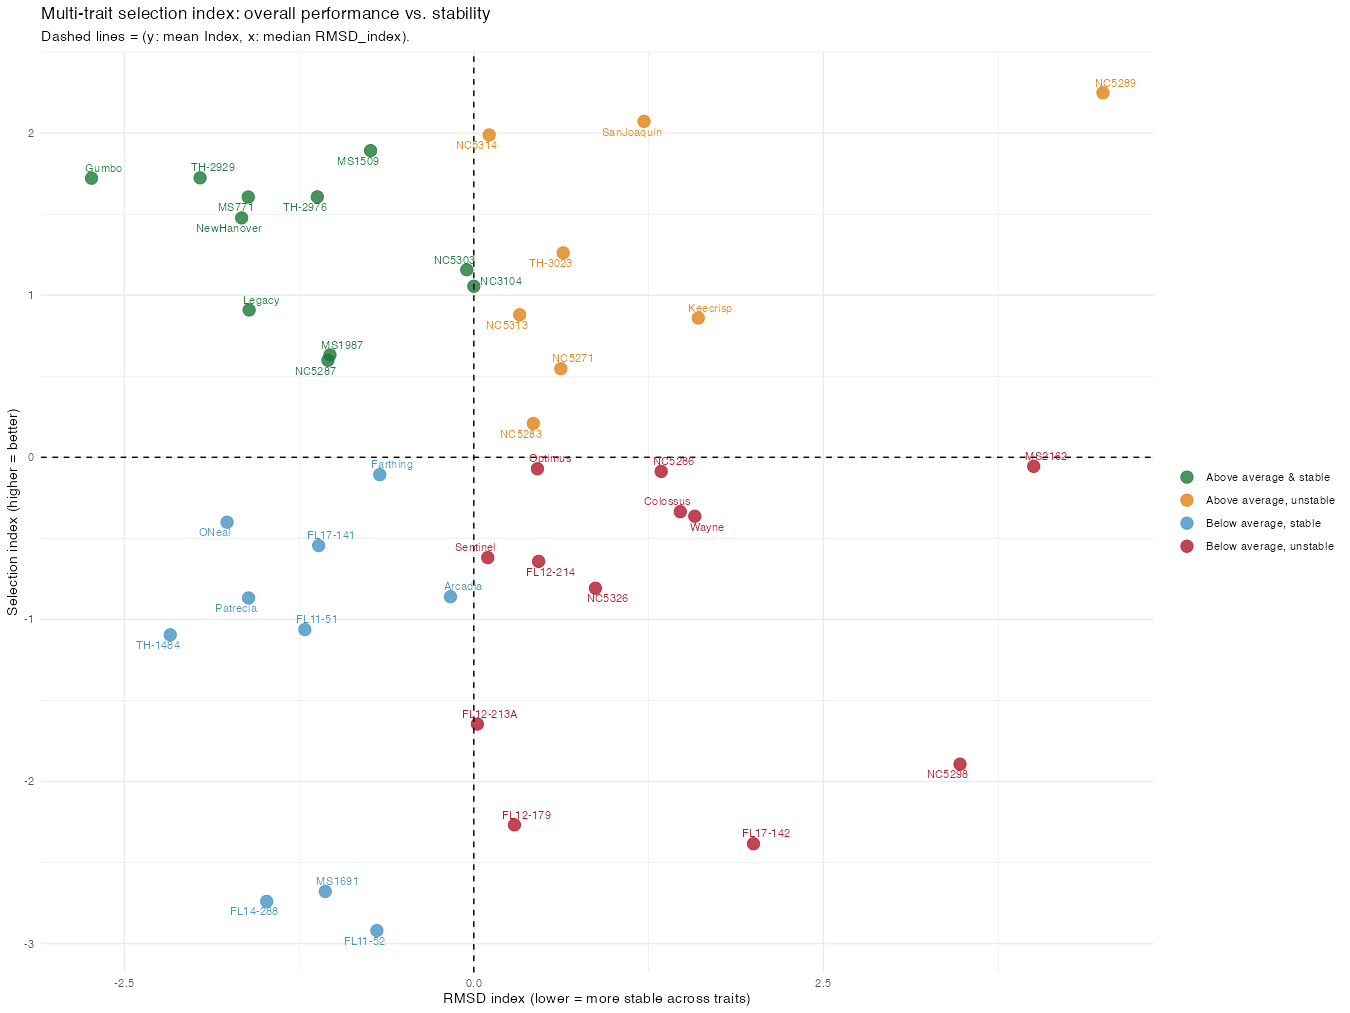

In [327]:
plot_selection_index(index_tab)

In [294]:
tar_load(stab_fa3_asr)
tar_load(stab_fa2_asr_bloom_bloom100)
tar_load(stab_fa2_asr_bloom_bloom5)
tar_load(stab_fa2_asr_bloom_bloom50)
tar_load(stab_fa2_asr_auc)
tar_load(stab_fa2_asr_qual_ta)
tar_load(stab_fa2_asr_qual_brix)
tar_load(stab_fa2_asr_ph)
tar_load(stab_fa2_asr_qual_avg_berry_weight)
tar_load(stab_fa2_asr_qual_firmness)

In [293]:
objs <- tar_objects()
objs[730:length(objs)]

  [1] "mods_comp_sm_bloom_bloom_duration"               "mods_comp_sm_lrt_auc"                           
  [3] "mods_comp_sm_lrt_bloom_bloom100"                 "mods_comp_sm_lrt_bloom_bloom5"                  
  [5] "mods_comp_sm_lrt_bloom_bloom50"                  "mods_comp_sm_lrt_bloom_bloom_duration"          
  [7] "mods_comp_sm_lrt_ph"                             "mods_comp_sm_lrt_qual_avg_berry_weight"         
  [9] "mods_comp_sm_lrt_qual_brix"                      "mods_comp_sm_lrt_qual_firmness"                 
 [11] "mods_comp_sm_lrt_qual_ta"                        "mods_comp_sm_ph"                                
 [13] "mods_comp_sm_qual_avg_berry_weight"              "mods_comp_sm_qual_brix"                         
 [15] "mods_comp_sm_qual_firmness"                      "mods_comp_sm_qual_ta"                           
 [17] "mods_ide_asr"                                    "mods_min_ide_asr"                               
 [19] "mods_min_ide_asr_auc"                  

In [ ]:
# 11/11 -- generalized (Cullis) heritability from the fitted FA model,
# ADDITIVE TERM ONLY (vm(Genotype, Ainv); no non-additive/dominance
# contribution). Two related but distinct quantities, both following the
# standard Cullis et al. (2006) generalized heritability:
#
#     H2 = 1 - mean(PEV_D) / (2 * sigma2_g)
#
# where PEV_D is the prediction error variance of a DIFFERENCE between two
# genotypes' predictions (not a single genotype's own PEV -- averaging
# individual reliabilities, the way add_reliability() in post_fa_fast.R
# does, is a common simplification but is not identical to this when PEVs
# and relatedness are uneven across genotype pairs, which is expected here
# given vm(Genotype, Ainv)). This matches the formula already cited in our
# own project library (Bakare et al. 2022, eq. 12).
#
#   compute_fa_heritability_env()  -- one H2 per ENVIRONMENT. This is the
#     FA-model analog of a single-trial QC H2, but estimated from the
#     JOINT multi-environment fit rather than independently per trial:
#     genotypes borrow strength across environments via the factor
#     structure and across relatives via Ainv, so expect these numbers to
#     differ from -- usually run higher/more stable than -- a per-trial-
#     only H2, especially for the thinner trials (BW/EV 2023, n=36-37).
#
#   compute_fa_heritability_op()   -- ONE H2 per trait, for the overall
#     performance (OP) BLUP itself (Smith & Cullis 2018's lambda_bar_1 *
#     f1_i). This is a genuinely joint quantity, not an average of the
#     per-Env numbers above -- it answers "how heritable is a genotype's
#     overall merit across the whole MET," the single number most
#     relevant to a release/parent-selection decision made on OP.
#
# Both expect Sigma/loadings already restricted to the additive term --
# pass split_varcomp_asreml(varcomp)$additive first (then
# extract_rg_matrix_asreml() on that) if the fitted model also has a
# non-additive term, exactly as fa_stability() expects elsewhere in this
# pipeline. `ka` is the number of additive FA factors (3 for yield's
# selected FA3, etc.).

library(dplyr)
library(tibble)
library(purrr)


# Full Genotype x Env covariance matrix of the ADDITIVE predictions,
# restricted via onlyuse so neither the Env fixed effect nor any
# non-additive random term contributes.
#
# NOTE on why the Env fixed effect needs no separate handling: every
# quantity computed downstream (a genotype-PAIR difference within the same
# Env, or the OP weighted-combination difference) only ever combines two
# genotypes' predictions at the SAME set of environments, so the Env fixed
# effect -- being the identical realized value for both genotypes at that
# Env -- cancels exactly in the difference regardless of whether it's
# included in predicted.value. That's an algebraic fact about variances of
# linear combinations, not an approximation, so onlyuse here only needs to
# exclude the NON-ADDITIVE random term, not the fixed effect.
get_fa_additive_vcov = function(fit, dta, ka, onlyuse = NULL) {
  if (is.null(onlyuse)) {
    onlyuse = as.formula(paste0("~fa(Env, k = ", ka, "):vm(Genotype, Gmat)"))
  }
  pred = predict(fit, classify = "Env:Genotype", data = dta,
                 onlyuse = onlyuse, vcov = TRUE)
  pv = pred$pvals %>%
    mutate(Env = as.character(Env), Genotype = as.character(Genotype),
           row = dplyr::row_number())
  list(pvals = pv, vcov = pred$vcov)
}


# ---- 1. Per-environment generalized heritability (additive only) ----
#
# sigma2_g per Env = diag(Sigma_additive), Sigma_additive = Lambda %*%
# t(Lambda) + diag(Psi) -- the SAME `cov` matrix extract_rg_matrix_asreml()
# already returns (restricted to the additive varcomp rows first, if the
# model also has a non-additive term).
#
# `tested` is REQUIRED, not optional -- a (Genotype, Env) long table of
# which genotypes were ACTUALLY phenotyped in each environment, same
# shape/convention as fa_stability()'s own `tested` argument. This matters
# a great deal for a thin trial: predict(classify = "Env:Genotype") with
# vm(Genotype, Ainv) returns a BLUP for EVERY genotype in Ainv at EVERY
# environment, including genotypes with zero data there at all -- those
# predictions are pure relatedness-shrinkage toward the population mean,
# with much larger PEV than a genotype actually grown in that trial. A
# per-trial heritability is supposed to describe how well THAT TRIAL
# discriminates among the genotypes it actually grew, not prediction
# accuracy into completely untested relatives (a different, genomic-
# selection-flavored question) -- so pairs are restricted to genotypes in
# `tested` for that Env before averaging PEV_D. Confirmed 2026-11-11: BW
# 2023 has only 14 genotypes tested (DESIGN.md Sec 2.1.2's all-genotype
# overlap table, diagonal), not 41 -- an earlier version of this function
# used every Ainv-level genotype's prediction regardless of whether it was
# tested, which silently inflated mean_pev_d (and depressed H2) for every
# thin trial by folding in ~27 untested-genotype predictions for BW 2023
# alone.
compute_fa_heritability_env = function(fit, dta, ka, Sigma_additive, tested) {

  vc = get_fa_additive_vcov(fit, dta, ka)
  pv = vc$pvals
  V  = vc$vcov

  envs = unique(pv$Env)
  gen_var = tibble(Env = rownames(Sigma_additive), sigma2_g = diag(Sigma_additive))

  purrr::map_dfr(envs, function(e) {
    tested_genos = tested %>% filter(Env == e) %>% pull(Genotype)

    rows = pv %>% filter(Env == e, Genotype %in% tested_genos)
    idx  = rows$row
    n    = length(idx)
    if (n < 2) return(tibble(Env = e, n_genotype = n, H2 = NA_real_))

    Vsub = V[idx, idx, drop = FALSE]
    # mean PEV of a pairwise difference over all unique TESTED-genotype
    # pairs in this Env: Var(g_i - g_j) = V_ii + V_jj - 2*V_ij
    pairs = combn(n, 2)
    pev_d = apply(pairs, 2, function(p) {
      i = p[1]; j = p[2]
      Vsub[i, i] + Vsub[j, j] - 2 * Vsub[i, j]
    })
    mean_pev_d = mean(pev_d)
    sg2 = gen_var$sigma2_g[match(e, gen_var$Env)]

    tibble(
      Env = e, n_genotype = n,
      mean_pev_d = mean_pev_d, sigma2_g = sg2,
      H2 = 1 - mean_pev_d / (2 * sg2)
    )
  })
}


# ---- 2. Joint heritability of OP (additive only), one number per trait ----
#
# OP_i = lambda_bar_1 * f1_i, f1_i = sum_j(w_j * beta_ij), w_j = L1_j /
# sum(L1^2) -- the SAME rotation/projection fa_stability() and
# fa_pc_scores() use, recomputed identically here so H2_OP refers to
# exactly the OP reported in the stability table, not a re-derived
# quantity that only shares the name.
#
# Var(OP) in the denominator is a MODEL-BASED quadratic form in the known
# genetic covariance matrix (lambda_bar1^2 * w' Sigma_additive w), not the
# empirical variance of the predicted BLUPs -- using the BLUPs' own
# variance would understate sigma2_g through shrinkage/regression-to-the-
# mean, the same reason Cullis et al. (2006) use the model-based variance
# component rather than var(BLUPs) in the single-trait case.
#
# UNLIKE compute_fa_heritability_env() above, this one deliberately does
# NOT restrict to a `tested` subset per genotype -- OP is explicitly a
# whole-of-MET, borrowing-strength quantity (that's the entire point of
# fitting one joint FA-GBLUP model instead of per-trial analyses), so a
# genotype tested in only 1 of 10 environments is SUPPOSED to get an OP
# prediction leaning on its relatives, with correspondingly larger PEV.
# The cost is that the single pooled H2_OP below mixes well-tested and
# thinly-tested genotypes together -- a genotype-level OP reliability
# (PEV_i vs. var_op, no pairwise differencing, no pooling across
# genotypes) is a better diagnostic than this one pooled number if you
# want to see that spread rather than average over it.
compute_fa_heritability_op = function(fit, dta, ka, loadings_additive, Sigma_additive, engine = 'asreml') {

  vc = get_fa_additive_vcov(fit, dta, ka)
  pv = vc$pvals
  V  = vc$vcov

  env_levs = unique(pv$Env)
  if (engine == 'asreml') rownames(loadings_additive) = levels(factor(dta$Env))
  stopifnot(setequal(env_levs, rownames(loadings_additive)))
  loadings_additive = loadings_additive[env_levs, , drop = FALSE]

  # same SVD/PC rotation fa_stability()/fa_pc_scores() use
  s = svd(loadings_additive)
  Lpc = s$u %*% diag(s$d, nrow = length(s$d))
  if (mean(Lpc[, 1]) < 0) Lpc[, 1] = -Lpc[, 1]
  L1 = Lpc[, 1]
  w = L1 / sum(L1^2)
  lambda_bar1 = mean(L1)

  var_op = as.numeric(lambda_bar1^2 * (t(w) %*% Sigma_additive[env_levs, env_levs] %*% w))

  genos = unique(pv$Genotype)
  idx_list = lapply(genos, function(g) {
    pv %>% filter(Genotype == g) %>% arrange(match(Env, env_levs)) %>% pull(row)
  })
  names(idx_list) = genos

  pair_list = combn(genos, 2, simplify = FALSE)
  pev_d = vapply(pair_list, function(pr) {
    idx_i = idx_list[[pr[1]]]; idx_j = idx_list[[pr[2]]]
    if (length(idx_i) != length(env_levs) || length(idx_j) != length(env_levs)) return(NA_real_)

    Vii = V[idx_i, idx_i, drop = FALSE]
    Vjj = V[idx_j, idx_j, drop = FALSE]
    Vij = V[idx_i, idx_j, drop = FALSE]

    # Var(OP_i - OP_j) = lambda_bar1^2 * w' (Vii + Vjj - 2 Vij) w
    as.numeric(lambda_bar1^2 * (t(w) %*% (Vii + Vjj - 2 * Vij) %*% w))
  }, numeric(1))

  mean_pev_d = mean(pev_d, na.rm = TRUE)

  tibble(
    n_genotype = length(genos),
    mean_pev_d = mean_pev_d,
    var_op     = var_op,
    H2_OP      = 1 - mean_pev_d / (2 * var_op)
  )
}




In [393]:
targets::tar_load(fit_fa1_asr)
tar_load(g_mat)

In [364]:
Gmat = g_mat

In [ ]:
varcomp = summary(fit_fa3_asr)$varcomp
# parts   = split_varcomp_asreml(varcomp)          
rg = extract_rg_matrix_asreml(varcomp, env_levels, n_factors = 3)
# rg$cov is Sigma_additive; rg$loadings is loadings_additive

tested = prep_yield %>% distinct(Genotype, Env)   
h2_env = compute_fa_heritability_env(fit_fa3_asr, prep_and_scale_dta(prep_yield), ka = 3,
                                       Sigma_additive = rg$cov,
                                       tested = tested)
h2_op = compute_fa_heritability_op(fit_fa3_asr, prep_and_scale_dta(prep_yield), ka = 3,
                                      loadings_additive = rg$loadings,
                                      Sigma_additive = rg$cov)

ASReml Version 4.2 11/11/2026 16:55:13
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -141.9823           1.0    795   16:55:13
  2     -141.9821           1.0    795   16:55:13
 3     -141.9819           1.0    795   16:55:13


Warning message:
In asreml(fixed = y_scaled ~ Env + factor(Age), random = ~fa(Env,  :
  Some components changed by more than 1% on the last iteration


ASReml Version 4.2 11/11/2026 16:55:14
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -141.9823           1.0    795   16:55:14
  2     -141.9821           1.0    795   16:55:14
 3     -141.9819           1.0    795   16:55:14


Warning message:
In asreml(fixed = y_scaled ~ Env + factor(Age), random = ~fa(Env,  :
  Some components changed by more than 1% on the last iteration


In [378]:
h2_env

# A tibble: 10 × 5
   Env     n_genotype mean_pev_d sigma2_g    H2
   <chr>        <int>      <dbl>    <dbl> <dbl>
 1 BW 2023         14     0.128     1.16  0.945
 2 BW 2024         39     0.0474    0.293 0.919
 3 BW 2025         39     0.0740    0.490 0.924
 4 BW 2026         39     0.153     0.714 0.893
 5 EV 2023         13     0.0483    0.397 0.939
 6 EV 2024         37     0.0796    0.497 0.920
 7 EV 2025         37     0.132     0.714 0.907
 8 EV 2026         29     0.157     0.739 0.894
 9 NC 2024         13     0.0728    1.15  0.968
10 NC 2025         17     0.101     1.48  0.966

In [375]:
mean(h2_env$H2)

[1] 0.9276026

In [376]:
h2_op

# A tibble: 1 × 4
  n_genotype mean_pev_d var_op H2_OP
       <int>      <dbl>  <dbl> <dbl>
1         41     0.0402  0.291 0.931

In [370]:
extract_env_var_sqrt_scale = function(cov, env_stats) {
  v = tibble::tibble(Env = rownames(cov), var_z = diag(cov)) %>%
    left_join(env_stats, by = 'Env') %>%
    mutate(env_var = var_z * sd_env^2)
  setNames(v$env_var, v$Env)
}

In [377]:
env_stats = prep_and_scale_dta(prep_yield) %>% distinct(Env, mean_env, sd_env)
vg_sqrt_scale = extract_env_var_sqrt_scale(rg$cov, env_stats)
vg_sqrt_scale 

   BW 2023    BW 2024    BW 2025    BW 2026    EV 2023    EV 2024    EV 2025    EV 2026    NC 2024    NC 2025 
 33.714915  59.617266 117.154211 126.600355   3.696691 117.816634 168.341954 155.474828 290.533850 296.965645 

In [388]:
tally(prep_yield$Env, prep_yield$Genotype)

: [1m[33mError[39m in `UseMethod()`:[22m
[33m![39m no applicable method for 'tally' applied to an object of class "character"

In [390]:
prep_yield %>% filter(Env == "BW 2023") %>%
  group_by(Genotype) %>%
  summarise(n = n(), mean_y = mean(y), min_y = min(y), max_y = max(y))

# A tibble: 14 × 5
   Genotype       n mean_y min_y max_y
   <chr>      <int>  <dbl> <dbl> <dbl>
 1 NC3104         3   9.83  1.73 16.3 
 2 NC5271         2   1.65  1.19  2.11
 3 NC5283         3   2.57  2.29  2.78
 4 NC5286         3   5.68  3.23  8.10
 5 NC5287         3   4.60  3.91  5.16
 6 NC5289         3  19.1  17.5  19.9 
 7 NC5298         3   3.18  2.45  4.39
 8 NC5313         3  11.0   9.96 11.5 
 9 NC5314         3   7.44  4.07  9.39
10 NC5326         1   3.29  3.29  3.29
11 NewHanover     2   1.92  1.51  2.33
12 TH-2929        2   2.11  1.31  2.91
13 TH-2976        2   1.85  1.23  2.48
14 TH-3023        3   3.27  2.59  3.67

In [394]:
varcomp_fa1 = summary(fit_fa1_asr)$varcomp
varcomp_fa2 = summary(fit_fa2_asr)$varcomp
varcomp_fa3 = summary(fit_fa3_asr)$varcomp

In [404]:
rg1 = extract_rg_matrix_asreml(varcomp_fa1, env_levels, n_factors = 1)
rg2 = extract_rg_matrix_asreml(varcomp_fa2, env_levels, n_factors = 2)
rg3 = extract_rg_matrix_asreml(varcomp_fa3, env_levels, n_factors = 3)
print(diag(rg1$cov)["BW 2023"]); print(diag(rg2$cov)["BW 2023"]); print(diag(rg3$cov)["BW 2023"])

  BW 2023 
0.9330044 
  BW 2023 
0.9465369 
 BW 2023 
1.157446 


In [399]:
extract_blups_asreml_additive = function(fit, dta, Gmat, Dmat = NULL) {
  pv = predict(fit, classify = "Env:Genotype", data = dta,
                onlyuse = ~fa(Env, k = 2):vm(Genotype, Gmat))$pvals
  env_fixed = predict(fit, classify = "Env", data = dta)$pvals
  pv %>%
    mutate(Env = as.character(Env), Genotype = as.character(Genotype)) %>%
    left_join(
      env_fixed %>% transmute(Env = as.character(Env), env_effect = predicted.value),
      by = "Env"
    ) %>%
    transmute(Genotype, Env, blup = predicted.value - env_effect, se = std.error)
}


In [401]:
extract_blups_asreml_additive(fit_fa3_asr, prep_and_scale_dta(prep_yield), Gmat) %>%
  filter(Env == "BW 2023") %>% arrange(blup)

ASReml Version 4.2 11/11/2026 17:56:20
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -141.9823           1.0    795   17:56:21
  2     -141.9821           1.0    795   17:56:21
 3     -141.9819           1.0    795   17:56:21
ASReml Version 4.2 11/11/2026 17:56:21
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -141.9823           1.0    795   17:56:21
  2     -141.9821           1.0    795   17:56:21
 3     -141.9819           1.0    795   17:56:21


Warning messages:
1: In asreml(fixed = y_scaled ~ Env + factor(Age), random = ~fa(Env,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env + factor(Age), random = ~fa(Env,  :
  Some components changed by more than 1% on the last iteration


     Genotype     Env       blup        se
1     Optimus BW 2023 -1.2720959 0.5610190
2    FL17-142 BW 2023 -0.9247049 0.7251097
3    Farthing BW 2023 -0.9227652 0.5465327
4     Arcadia BW 2023 -0.8997785 0.5787677
5       Wayne BW 2023 -0.8873604 0.6813732
6      MS1691 BW 2023 -0.8380149 0.7075805
7    FL17-141 BW 2023 -0.7701520 0.6237846
8      NC5271 BW 2023 -0.6970393 0.3390459
9     TH-1484 BW 2023 -0.6189972 1.0963486
10 SanJoaquin BW 2023 -0.4951365 0.5200049
11    TH-2929 BW 2023 -0.4686133 0.3911730
12    TH-2976 BW 2023 -0.4536822 0.3906847
13     MS1987 BW 2023 -0.4486670 0.5445725
14   FL14-288 BW 2023 -0.4317279 0.9979002
15     NC5326 BW 2023 -0.4284751 0.3748926
16   Keecrisp BW 2023 -0.3711141 0.5232669
17 NewHanover BW 2023 -0.3565021 0.3372893
18    TH-3023 BW 2023 -0.2308608 0.3468127
19   Patrecia BW 2023 -0.2142188 0.5124214
20      ONeal BW 2023 -0.1878096 0.5161920
21     NC5303 BW 2023 -0.1856888 0.4473837
22     NC5298 BW 2023 -0.1625625 0.3144484
23     NC52

In [ ]:

library(dplyr)

refit_without_genotype_env = function(fa_dta, Gmat, ka, drop_genotype, drop_env,
                                       extra_fixed = NULL, maxiter = 300) {
  dta_sensitivity = fa_dta %>%
    filter(!(Genotype == drop_genotype & Env == drop_env))

  fit_fa_asreml(dta_sensitivity, Gmat, ka = ka, maxiter = maxiter, extra_fixed = extra_fixed)
}




In [408]:

fit_fa_asreml = function(fa_dta, Gmat, ka, maxiter = 300, extra_fixed = NULL) {
  dta = prep_and_scale_dta(fa_dta)

  fixed_ef = 'Env'
  if(!is.null(extra_fixed)) fixed_ef = paste(fixed_ef, extra_fixed, sep = '+')
  fixed_formula = as.formula(paste0('y_scaled ~ ', fixed_ef ))

  # print(fixed_formula)

  fit = asreml(
    fixed = fixed_formula,
    random = as.formula(paste0("~fa(Env, k = ", ka, "):vm(Genotype, Gmat) + Env:Block")),
    residual = ~dsum(~units | Env),
    data = dta,
    maxit = maxiter,
    ai.loadings = 5,   
    ai.penalty = 15     
  )
  fit$call$maxit = maxiter
  update.asreml(fit)
}


In [409]:
fit_fa3_sensitivity = refit_without_genotype_env(
  prep_yield, Gmat, ka = 3,
  drop_genotype = "NC5289", drop_env = "BW 2023",
  extra_fixed = "factor(Age)"   
)

ASReml Version 4.2 11/11/2026 18:19:04
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -216.4040           1.0    792   18:19:04  (  2 restrained)
  2     -179.6237           1.0    792   18:19:04  (  3 restrained)
  3     -162.4292           1.0    792   18:19:04  (  3 restrained)
  4     -154.4623           1.0    792   18:19:04  (  5 restrained)
  5     -152.1295           1.0    792   18:19:04  (  2 restrained)
  6     -150.1418           1.0    792   18:19:04  (  2 restrained)
  7     -149.2326           1.0    792   18:19:04  (  2 restrained)
  8     -147.9592           1.0    792   18:19:04  (  2 restrained)
  9     -146.8940           1.0    792   18:19:04  (  2 restrained)
 10     -146.5559           1.0    792   18:19:04  (  1 restrained)
 11     -146.4746           1.0    792   18:19:04  (  1 restrained)
 12     -146.4257           1.0    792   18:19:04
 13     -146.3989           1.0    792   18:19:04
 14     -146

Warning messages:
1: In asreml(fixed = fixed_formula, random = as.formula(paste0("~fa(Env, k = ",  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env + factor(Age), random = ~fa(Env,  :
  Some components changed by more than 1% on the last iteration


In [410]:
varcomp_sensitivity = summary(fit_fa3_sensitivity)$varcomp
rg_sensitivity = extract_rg_matrix_asreml(varcomp_sensitivity, env_levels, n_factors = 3)

In [411]:
compare = tibble::tibble(
  Env = rownames(rg_sensitivity$cov),
  sigma2_g_original    = diag(rg$cov)[rownames(rg_sensitivity$cov)],
  sigma2_g_sensitivity  = diag(rg_sensitivity$cov)
)
compare   

# A tibble: 10 × 3
   Env     sigma2_g_original sigma2_g_sensitivity
   <chr>               <dbl>                <dbl>
 1 BW 2023             1.16                 0.729
 2 BW 2024             0.293                0.295
 3 BW 2025             0.490                0.536
 4 BW 2026             0.714                0.735
 5 EV 2023             0.397                0.393
 6 EV 2024             0.497                0.445
 7 EV 2025             0.714                0.653
 8 EV 2026             0.739                0.748
 9 NC 2024             1.15                 0.940
10 NC 2025             1.48                 0.859

In [ ]:


library(dplyr)
library(purrr)

test_age_fixed_effect = function(fa_dta_list, Ainv, ka_list, maxiter = 300) {

  stopifnot(setequal(names(fa_dta_list), names(ka_list)))

  purrr::imap_dfr(fa_dta_list, function(fa_dta, trait) {

    if (!"Age" %in% names(fa_dta)) {
      return(tibble::tibble(
        trait = trait, F_inc = NA_real_, numDF = NA_integer_, denDF = NA_real_,
        p_value = NA_real_, note = "Age column missing from this trait's data -- not tested"
      ))
    }
    if (dplyr::n_distinct(fa_dta$Age, na.rm = TRUE) < 2) {
      return(tibble::tibble(
        trait = trait, F_inc = NA_real_, numDF = NA_integer_, denDF = NA_real_,
        p_value = NA_real_, note = "Age has <2 distinct levels in this trait's data -- not testable"
      ))
    }

    fit = fit_fa_asreml(fa_dta, Ainv, ka = ka_list[[trait]], maxiter = maxiter,
                         extra_fixed = "factor(Age)")


    w = asreml::wald.asreml(fit, ssType = "incremental", denDF = "numeric")
    age_row = w$Wald[grepl("factor\\(Age\\)", rownames(w$Wald)), , drop = FALSE]

    F_inc = age_row[["F.inc"]]
    numDF = age_row[["Df"]]
    denDF = age_row[["denDF"]]
    p_f   = age_row[["Pr"]]


    used_fallback = is.na(denDF) || is.na(p_f)
    p_value = if (used_fallback) {
      pchisq(F_inc * numDF, df = numDF, lower.tail = FALSE)
    } else p_f

    tibble::tibble(
      trait   = trait,
      F_inc   = F_inc,
      numDF   = numDF,
      denDF   = denDF,
      p_value = p_value,
      method  = if (used_fallback) "Wald chi-square (denDF fallback)" else "Wald F-test",
      note    = dplyr::case_when(
        p_value < 0.05  ~ "significant -- Age earns its place",
        TRUE            ~ "not significant at alpha=0.05"
      )
    )
  })
}



In [454]:
tar_load(prep_yield)
tar_load(prep_bloom_bloom5)
tar_load(prep_bloom_bloom50)
tar_load(prep_bloom_bloom100)
tar_load(al_prep_auc)
tar_load(prep_ph)
tar_load(prep_qual_avg_berry_weight)
tar_load(prep_qual_brix)
tar_load(prep_qual_ta)
tar_load(prep_qual_firmness)

In [471]:
fa_dta_list = list(
  yield          = prep_yield,
  bloom5 = prep_bloom_bloom5,
  bloom50 = prep_bloom_bloom50,
  bloom100 = prep_bloom_bloom100,
  # bloom_auc = al_prep_auc,
  plant_height   = prep_ph,
  berry_weight   = prep_qual_avg_berry_weight,
  tss            = prep_qual_brix,
  ta             = prep_qual_ta,
  firmness       = prep_qual_firmness
)
ka_list = list(
  yield = 3, bloom5 = 2, bloom50 = 2, bloom100 = 2,  plant_height = 2,
  berry_weight = 2, tss = 2, ta = 2, firmness = 2   )

In [460]:
age_test_results = test_age_fixed_effect(fa_dta_list, Gmat, ka_list)


ASReml Version 4.2 12/11/2026 10:53:20
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -213.1228           1.0    795   10:53:20  (  2 restrained)
  2     -200.2391           1.0    795   10:53:20  (  2 restrained)
  3     -171.2611           1.0    795   10:53:20  (  2 restrained)
  4     -157.7433           1.0    795   10:53:20  (  4 restrained)
  5     -153.4471           1.0    795   10:53:20  (  3 restrained)
  6     -150.4209           1.0    795   10:53:20  (  4 restrained)
  7     -149.0209           1.0    795   10:53:20  (  1 restrained)
  8     -148.4236           1.0    795   10:53:20  (  2 restrained)
  9     -148.2462           1.0    795   10:53:20  (  1 restrained)
 10     -148.0915           1.0    795   10:53:20  (  1 restrained)
 11     -147.9393           1.0    795   10:53:20  (  1 restrained)
 12     -147.7347           1.0    795   10:53:20  (  1 restrained)
 13     -147.4256           1.0    795   10:

There were 33 warnings (use warnings() to see them)


In [461]:
age_test_results

# A tibble: 10 × 7
   trait        F_inc numDF denDF  p_value method                           note                              
   <chr>        <dbl> <dbl> <dbl>    <dbl> <chr>                            <chr>                             
 1 yield         12.4     5  NA   4.92e-12 Wald chi-square (denDF fallback) significant -- Age earns its place
 2 bloom5        13.8     5 105.  2.25e-10 Wald F-test                      significant -- Age earns its place
 3 bloom50       16.8     5  53.6 6.05e-10 Wald F-test                      significant -- Age earns its place
 4 bloom100      18.1     5  NA   5.40e-18 Wald chi-square (denDF fallback) significant -- Age earns its place
 5 bloom_auc     17.8     5  54.3 2.10e-10 Wald F-test                      significant -- Age earns its place
 6 plant_height  11.4     5  NA   5.43e-11 Wald chi-square (denDF fallback) significant -- Age earns its place
 7 berry_weight  12.8     5  53.2 3.39e- 8 Wald F-test                      significant -- Ag

In [469]:
# 11/12 -- does Age's significance (test_age_fixed_effect.R) survive once
# restricted to genotypes that show REAL within-genotype Age variation
# (tested across multiple years, so the same genotype is compared to its
# own earlier/later self), or was it mostly a proxy for check-vs-newer-
# breeding-line identity (most newer lines only ever observed at one Age,
# so "Age" and "which genotype cohort" are nearly the same variable for
# them)? See the 11/12 discussion: Age is significant on top of Env for
# EVERY trait tested, including fruit chemistry (TSS/TA/firmness), which
# is surprising enough to want this check before trusting it as a
# physiological-maturation finding across the board.
#
# Genotypes are identified EMPIRICALLY (>=2 distinct Age values actually
# observed in THIS trait's own data), not from an external "official
# check list" -- a genotype can show real within-genotype Age variation
# without being a formal check, and the official check list may not line
# up exactly with which genotypes happen to have multi-year data for a
# given trait (traits differ in which environments/years they were
# scored in).

library(dplyr)
library(purrr)

test_age_within_genotype = function(fa_dta_list, A_mat, ka_list, maxiter = 300) {

  stopifnot(setequal(names(fa_dta_list), names(ka_list)))

  purrr::imap_dfr(fa_dta_list, function(fa_dta, trait) {

    if (!"Age" %in% names(fa_dta)) {
      return(tibble::tibble(trait = trait, note = "Age column missing -- not tested"))
    }

    multi_age_genos = fa_dta %>%
      distinct(Genotype, Age) %>%
      count(Genotype) %>%
      filter(n >= 2) %>%
      pull(Genotype)

    n_total_genos = dplyr::n_distinct(fa_dta$Genotype)
    n_multi       = length(multi_age_genos)

    if (n_multi < 5) {
      return(tibble::tibble(
        trait = trait, n_total_genotypes = n_total_genos, n_multi_age_genotypes = n_multi,
        note = paste0("too few multi-Age genotypes (", n_multi, ") to refit reliably -- not tested")
      ))
    }

    dta_sub = fa_dta %>% filter(Genotype %in% multi_age_genos)

    if (dplyr::n_distinct(dta_sub$Age, na.rm = TRUE) < 2) {
      return(tibble::tibble(
        trait = trait, n_total_genotypes = n_total_genos, n_multi_age_genotypes = n_multi,
        note = "Age has <2 distinct levels within the multi-Age subset -- not testable"
      ))
    }

    # Ainv needs rebuilding on the RESTRICTED genotype set -- reusing the
    # full-panel Ainv as-is would silently keep rows/cols for genotypes no
    # longer in the data, which asreml's vm() will not accept cleanly.
    # build_A_inverse() (build_relationship_matrix.R) already does exactly
    # this subset-then-invert step.
    Ainv_sub = A_mat[(unique(dta_sub$Genotype)), (unique(dta_sub$Genotype))]
    # Ainv_sub = build_A_inverse(A_mat, keep_genotypes = sort(unique(dta_sub$Genotype)))

    fit = tryCatch(
      fit_fa_asreml(dta_sub, Ainv_sub, ka = ka_list[[trait]], maxiter = maxiter,
                     extra_fixed = "factor(Age)"),
      error = function(e) e
    )

    if (inherits(fit, "error")) {
      return(tibble::tibble(
        trait = trait, n_total_genotypes = n_total_genos, n_multi_age_genotypes = n_multi,
        note = paste0("refit failed: ", conditionMessage(fit))
      ))
    }

    w = asreml::wald.asreml(fit, ssType = "incremental", denDF = "numeric")
    age_row = w$Wald[grepl("factor\\(Age\\)", rownames(w$Wald)), , drop = FALSE]

    F_inc = age_row[["F.inc"]]
    numDF = age_row[["Df"]]
    denDF = age_row[["denDF"]]
    p_f   = age_row[["Pr"]]

    used_fallback = is.na(denDF) || is.na(p_f)
    p_value = if (used_fallback) pchisq(F_inc * numDF, df = numDF, lower.tail = FALSE) else p_f

    tibble::tibble(
      trait = trait,
      n_total_genotypes = n_total_genos, n_multi_age_genotypes = n_multi,
      F_inc = F_inc, numDF = numDF, denDF = denDF, p_value = p_value,
      method = if (used_fallback) "Wald chi-square (denDF fallback)" else "Wald F-test",
      note = dplyr::case_when(
        p_value < 0.05 ~ "significant WITHIN multi-Age genotypes -- supports a real aging effect",
        TRUE           ~ "not significant within multi-Age genotypes -- consistent with Age mostly proxying genotype cohort"
      )
    )
  })
}


# ---- Run it ----
# age_within_results = test_age_within_genotype(fa_dta_list, A_mat, ka_list)
# age_within_results
#
# Read alongside test_age_fixed_effect.R's full-panel result per trait:
#   - full-panel significant AND within-genotype significant  -> real aging effect, keep Age
#   - full-panel significant BUT within-genotype NOT significant -> Age was mostly a
#     genotype-cohort proxy; still worth keeping in the model (you don't want that
#     cohort difference leaking into Genotype/Env), just describe it honestly as that,
#     not as a maturation effect, in the methods text

In [472]:
age_within_results = test_age_within_genotype(fa_dta_list, Gmat, ka_list)

ASReml Version 4.2 12/11/2026 14:17:42
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -214.3868           1.0    795   14:17:42  (  2 restrained)
  2     -201.5580           1.0    795   14:17:42  (  2 restrained)
  3     -172.9155           1.0    795   14:17:42  (  2 restrained)
  4     -158.9773           1.0    795   14:17:42  (  3 restrained)
  5     -153.6135           1.0    795   14:17:42  (  1 restrained)
  6     -148.1969           1.0    795   14:17:42  (  3 restrained)
  7     -145.8485           1.0    795   14:17:42  (  3 restrained)
  8     -144.9652           1.0    795   14:17:42  (  2 restrained)
  9     -144.1811           1.0    795   14:17:42  (  3 restrained)
 10     -143.5070           1.0    795   14:17:42  (  1 restrained)
 11     -143.1920           1.0    795   14:17:42  (  2 restrained)
 12     -142.5462           1.0    795   14:17:42  (  1 restrained)
 13     -142.1470           1.0    795   14:

There were 26 warnings (use warnings() to see them)


In [473]:
age_within_results

# A tibble: 9 × 9
  trait        n_total_genotypes n_multi_age_genotypes F_inc numDF denDF  p_value method                           note                                                                  
  <chr>                    <int>                 <int> <dbl> <dbl> <dbl>    <dbl> <chr>                            <chr>                                                                 
1 yield                       41                    41  14.3     5  NA   4.87e-14 Wald chi-square (denDF fallback) significant WITHIN multi-Age genotypes -- supports a real aging effect
2 bloom5                      41                    41  15.2     5 120.  1.50e-11 Wald F-test                      significant WITHIN multi-Age genotypes -- supports a real aging effect
3 bloom50                     41                    41  16.9     5  53.7 5.22e-10 Wald F-test                      significant WITHIN multi-Age genotypes -- supports a real aging effect
4 bloom100                    41                    

In [474]:
# 11/12 -- eyeball check: does Age's significance (test_age_fixed_effect.R)
# look like a sensible maturation TREND (roughly monotonic/smooth across
# Age levels, in a biologically plausible direction) or an ERRATIC/
# non-monotonic pattern (more consistent with Age partly absorbing leftover
# year-to-year noise not already separated out by Env)? A significant
# p-value alone can't distinguish these two very different stories -- this
# just pulls and plots predict(fit, classify = "factor(Age)") for every
# trait so you can look at the shape directly.
#
# Works from EITHER a list of already-fitted models (fastest -- reuses fits
# you already have sitting in your session, e.g. from test_age_fixed_effect()
# if you capture them) OR refits from scratch per trait if you don't have
# them handy. Both paths produce the SAME downstream data/plot.

library(dplyr)
library(purrr)
library(ggplot2)

# Pulls predicted marginal means by Age from a SINGLE already-fitted model
# (must have been fit with extra_fixed = "factor(Age)", i.e. the same fits
# test_age_fixed_effect() produces internally).
get_age_predictions = function(fit, trait) {
  pred = predict(fit, classify = "factor(Age)")
  pv = pred$pvals
  tibble::tibble(
    trait           = trait,
    Age             = as.character(pv[["Age"]] %||% pv[[1]]),
    predicted.value = pv$predicted.value,
    std.error       = pv$std.error
  )
}

`%||%` = function(a, b) if (!is.null(a)) a else b

# fits_list: OPTIONAL named list of trait -> already-fitted asreml object
# (fit WITH factor(Age) in the fixed formula). Any trait missing from
# fits_list gets refit here using fa_dta_list/Gmat/ka_list, same call
# test_age_fixed_effect() makes internally -- so this is safe to run
# standalone without having saved anything from that script.
compute_age_trends = function(fa_dta_list, Gmat, ka_list, fits_list = NULL, maxiter = 300) {

  stopifnot(setequal(names(fa_dta_list), names(ka_list)))

  purrr::imap_dfr(fa_dta_list, function(fa_dta, trait) {

    if (!"Age" %in% names(fa_dta) || dplyr::n_distinct(fa_dta$Age, na.rm = TRUE) < 2) {
      return(tibble::tibble(trait = trait, Age = NA_character_,
                             predicted.value = NA_real_, std.error = NA_real_))
    }

    fit = fits_list[[trait]]
    if (is.null(fit)) {
      fit = fit_fa_asreml(fa_dta, Gmat, ka = ka_list[[trait]], maxiter = maxiter,
                           extra_fixed = "factor(Age)")
    }

    get_age_predictions(fit, trait)
  })
}

# Faceted trend plot, one panel per trait, free y-scales (traits are on
# different y_scaled scales so comparing SHAPE across panels is the point,
# not comparing magnitudes). Age is treated as ordered/numeric on the x-axis
# so a real maturation trend shows up as a visibly rising/falling line
# rather than an arbitrary left-to-right category order.
plot_age_trends = function(age_pred_df) {
  df = age_pred_df %>%
    filter(!is.na(Age)) %>%
    mutate(Age_num = suppressWarnings(as.numeric(Age))) %>%
    arrange(trait, Age_num)

  ggplot(df, aes(x = Age_num, y = predicted.value)) +
    geom_ribbon(aes(ymin = predicted.value - std.error, ymax = predicted.value + std.error),
                alpha = 0.2) +
    geom_line() +
    geom_point(size = 2) +
    facet_wrap(~trait, scales = "free_y") +
    labs(x = "Age", y = "Predicted mean (y_scaled)",
         title = "Predicted mean by Age, per trait (±1 SE)") +
    theme_minimal()
}


# ---- Run it ----
# age_pred_df = compute_age_trends(fa_dta_list, Gmat, ka_list)
#   # or, reusing fits you already have:
# age_pred_df = compute_age_trends(fa_dta_list, Gmat, ka_list,
#                                    fits_list = list(yield = fit_yield, tss = fit_tss, ...))
#
# plot_age_trends(age_pred_df)
#
# Reading it:
#   - smooth, roughly monotonic trend (up or down) across Age -> consistent
#     with a real plant-maturity effect on that trait
#   - zig-zag / no clear direction -> more consistent with Age partly
#     standing in for leftover year-to-year noise not already separated out
#     by Env; still statistically "significant" by the Wald test, but not
#     a maturation story -- describe it that way in the methods text rather
#     than as physiological aging

In [475]:
age_pred_df = compute_age_trends(fa_dta_list, Gmat, ka_list)
  # or, reusing fits you already have:
# age_pred_df = compute_age_trends(fa_dta_list, Gmat, ka_list,
#                                    fits_list = list(yield = fit_yield, tss = fit_tss, ...))


ASReml Version 4.2 12/11/2026 15:03:39
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -213.1228           1.0    795   15:03:39  (  2 restrained)
  2     -200.2391           1.0    795   15:03:39  (  2 restrained)
  3     -171.2611           1.0    795   15:03:39  (  2 restrained)
  4     -157.7433           1.0    795   15:03:39  (  4 restrained)
  5     -153.4471           1.0    795   15:03:39  (  3 restrained)
  6     -150.4209           1.0    795   15:03:39  (  4 restrained)
  7     -149.0209           1.0    795   15:03:39  (  1 restrained)
  8     -148.4236           1.0    795   15:03:39  (  2 restrained)
  9     -148.2462           1.0    795   15:03:39  (  1 restrained)
 10     -148.0915           1.0    795   15:03:39  (  1 restrained)
 11     -147.9393           1.0    795   15:03:39  (  1 restrained)
 12     -147.7347           1.0    795   15:03:39  (  1 restrained)
 13     -147.4256           1.0    795   15:

There were 23 warnings (use warnings() to see them)


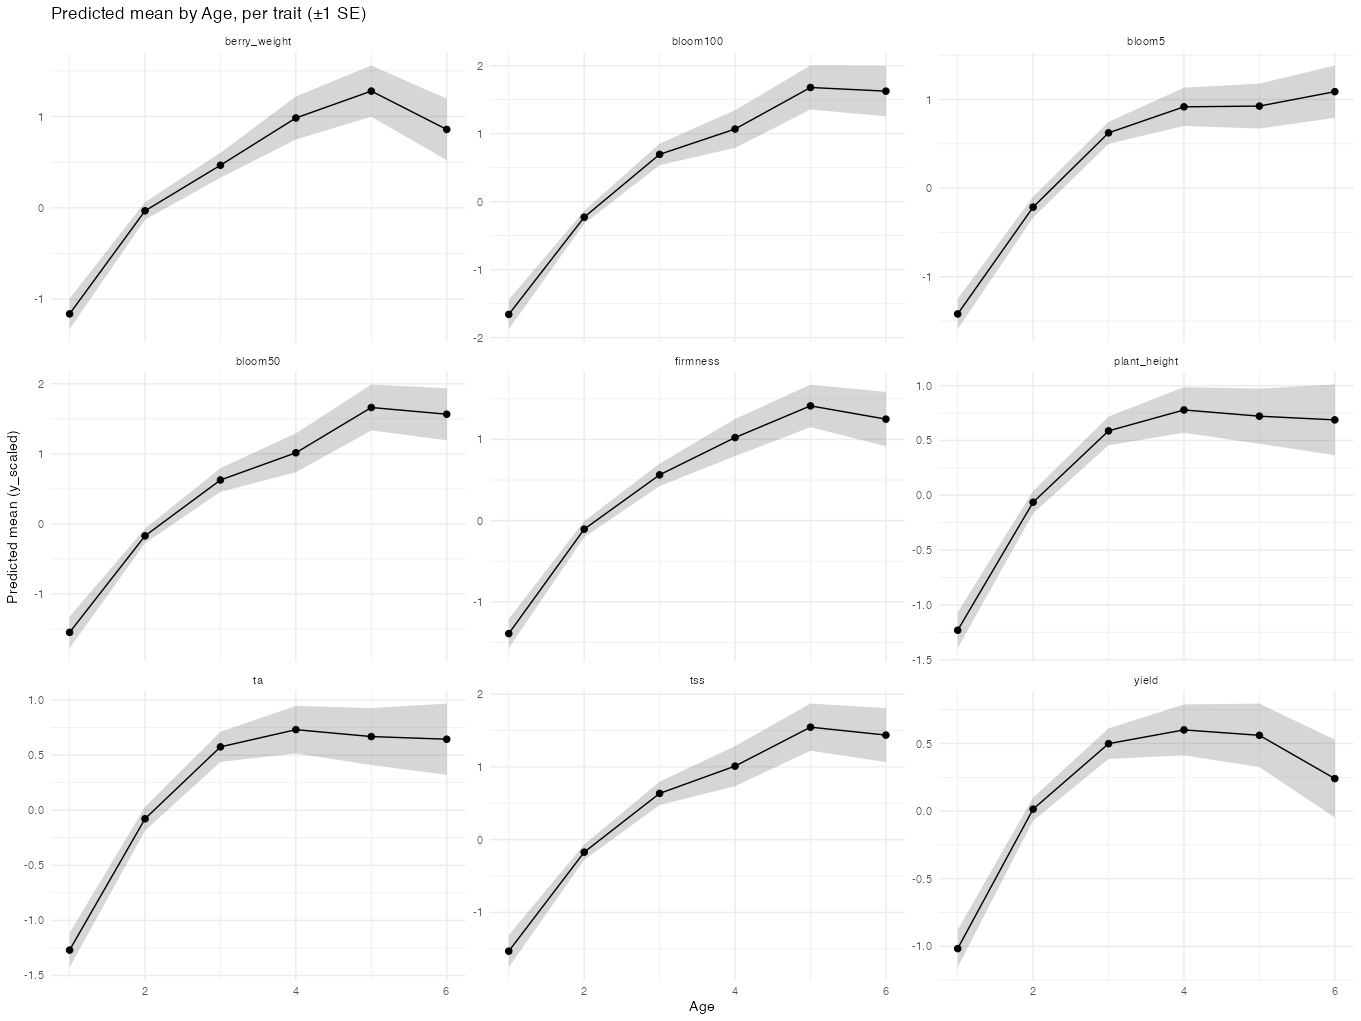

In [476]:
plot_age_trends(age_pred_df)

In [477]:
# 11/12 -- how much data actually backs each Age level, per trait? The
# predicted-mean-by-Age plot showed a plateau from Age 3 onward with a
# slight downturn at Age 6 (yield, berry_weight) and visibly wider CIs
# there -- before reading that as a real late-stage decline, check whether
# Age 6 is just thin (few observations/genotypes/environments), in which
# case the wobble is imprecision, not biology.

library(dplyr)
library(purrr)

# One row per trait x Age: n_obs (raw rows), n_genotype (distinct
# genotypes contributing at that Age), n_env (distinct environments at
# that Age -- a single Age value is often tied to very few environments
# by construction, since Age = season - planting_year, so this is often
# the most informative count: an Age level resting on one environment is
# fundamentally a single-season estimate, however many genotypes/reps it has).
check_age_counts = function(fa_dta_list) {
  purrr::imap_dfr(fa_dta_list, function(fa_dta, trait) {
    if (!"Age" %in% names(fa_dta)) {
      return(tibble::tibble(trait = trait, Age = NA, note = "Age column missing"))
    }
    fa_dta %>%
      group_by(Age) %>%
      summarise(
        n_obs       = n(),
        n_genotype  = n_distinct(Genotype),
        n_env       = n_distinct(Env),
        envs        = paste(sort(unique(as.character(Env))), collapse = ", "),
        .groups = "drop"
      ) %>%
      mutate(trait = trait, .before = 1) %>%
      arrange(Age)
  })
}


# ---- Run it ----
# age_counts = check_age_counts(fa_dta_list)
# age_counts %>% filter(Age == 6)          # the level in question
# age_counts %>% arrange(trait, Age) %>% print(n = Inf)   # full picture
#
# Reading it: if Age == 6 has noticeably fewer n_env (and/or n_genotype)
# than Age == 3/4/5 for yield/berry_weight specifically, that's enough to
# treat the Age-6 downturn as low-precision rather than a real late-stage
# decline -- consistent with the visibly wider SE band already seen in the
# plot, now with a concrete n behind it. If n_env at Age 6 is 1, the
# "downturn" is really just that one environment's idiosyncrasy, not a
# trend over plant age at all.

In [478]:
age_counts = check_age_counts(fa_dta_list)
age_counts %>% filter(Age == 6)

# A tibble: 6 × 6
  trait      Age n_obs n_genotype n_env envs   
  <chr>    <dbl> <int>      <int> <int> <chr>  
1 yield        6    37         10     1 NC 2025
2 bloom5       6    26          7     1 NC 2025
3 bloom50      6    26          7     1 NC 2025
4 bloom100     6    26          7     1 NC 2025
5 tss          6    28          8     1 NC 2025
6 ta           6    28          8     1 NC 2025

In [479]:
age_counts %>% arrange(trait, Age) %>% print(n = Inf)

# A tibble: 50 × 6
   trait          Age n_obs n_genotype n_env envs                                       
   <chr>        <dbl> <int>      <int> <int> <chr>                                      
 1 berry_weight     1   207         40     4 BW 2023, BW 2024, EV 2023, EV 2024         
 2 berry_weight     2   215         41     4 BW 2024, BW 2025, EV 2024, EV 2025         
 3 berry_weight     3   196         41     5 BW 2025, BW 2026, EV 2025, EV 2026, NC 2024
 4 berry_weight     4    98         18     3 BW 2026, EV 2026, NC 2024                  
 5 berry_weight     5    19          6     1 NC 2024                                    
 6 bloom100         1   218         41     4 BW 2023, BW 2024, EV 2023, EV 2024         
 7 bloom100         2   218         41     4 BW 2024, BW 2025, EV 2024, EV 2025         
 8 bloom100         3   150         41     3 BW 2025, EV 2025, EV 2026                  
 9 bloom100         4    54         14     2 EV 2026, NC 2025                           
10